In [420]:
#import needed packages
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from copy import deepcopy as cdc

from datetime import datetime as dt
import re
def extract_timestamps(series:pd.Series) -> pd.Series:
    timestamp = series.str.extract('_(\d{4}-[\-\d_T]*)DLC', expand=False)
    return pd.to_datetime(timestamp, format="%Y-%m-%dT%H_%M_%S")
##need to have filename column as type str in order for datetime extraction to be used, won't run on Posix type

import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats

import prey_capture_python as preycap
# import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [90]:
## load in data in a different way, need to clean up the conditions etc
h5_newmice="/Users/mollyshallow/Desktop/opto_metrics_result/20230530_newcohort_LD_test.h5"
h5_oldmice="/Users/mollyshallow/Desktop/opto_metrics_result/20230530_oldcohorts_LD_test.h5"

## use the below lines to clean up the conditions (will fix this so its not hard coded later)
df_old=pd.read_hdf(h5_oldmice, key='df')
with open('folderlist.txt', 'w') as f_out:
    f_out.write('\n'.join(df_old['folder_path'].astype('str')))
df_old['filename']=df_old['filename'].astype('str')
# type(df_all['filename'][0])
df_old=df_old[df_old['filename'].str.contains('0896|0897|0898|0893|0895')]
df_old['capduration']=df_old['captureT']-df_old['timetointercept']

df_new=pd.read_hdf(h5_newmice, key='df')
with open('folderlist.txt', 'w') as f_out:
    f_out.write('\n'.join(df_new['folder_path'].astype('str')))
df_new['filename']=df_new['filename'].astype('str')
# type(df_all['filename'][0])
df_new=df_new[df_new['filename'].str.contains('1337|1429|1430')]
df_new['capduration']=df_new['captureT']-df_new['timetointercept']

df_all=pd.concat([df_old, df_new], ignore_index=True)

fr=200

nandf=cdc(df_all)
nans=np.where(nandf['captureT']>=120)
nanvals=nandf['captureT'].iloc[nans[0]]
nandf=nandf.replace({'captureT':nanvals.values}, np.nan)

nan_attacks=np.where(nandf['timetointercept']>=120)
nan_attackvals=nandf['timetointercept'].iloc[nan_attacks[0]]
nandf=nandf.replace({'timetointercept':nan_attackvals.values}, np.nan)

nan_approach=np.where(nandf['timetoapproach']>=120)
nan_approachvals=nandf['timetoapproach'].iloc[nan_approach[0]]
nandf=nandf.replace({'timetoapproach':nan_approachvals.values}, np.nan)

nandf['capduration']=nandf['captureT']-nandf['timetointercept']

#unfortunately, intercept time was initially calculated from the start of the trial not from the cricket drop, attemtping to correct for this 
# in correcting for this, realized that a bunch of the intercept frames are for some reason before the cricket drop, not quite sure how this is happening because dist data doesnt align
nandf['corrected_timetointercept']=(nandf['interceptframe']-nandf['cricketdrop'])/fr
nandf['corrected_capduration']=nandf['captureT']-nandf['corrected_timetointercept']

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

drops=np.where(nandf['trials_to_drop']=='both')[0]
drops

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

test=extract_timestamps(test_nandf["filename"])

test=test.to_list()
test_nandf['timestamps']=test

start_cohort1_baseline_l = dt.strptime('2022-02-10', "%Y-%m-%d")
end_cohort1_baseline_l = dt.strptime('2022-02-15', "%Y-%m-%d")

start_cohort1_baseline_d = dt.strptime('2022-02-16', "%Y-%m-%d")
end_cohort1_baseline_d = dt.strptime('2022-02-21', "%Y-%m-%d")

start_cohort1_l = dt.strptime('2022-02-22', "%Y-%m-%d")
end_cohort1_l = dt.strptime('2022-03-02', "%Y-%m-%d")

start_cohort1_d = dt.strptime('2022-03-03', "%Y-%m-%d")
end_cohort1_d = dt.strptime('2022-03-12', "%Y-%m-%d")

start_cohort2_baseline_l = dt.strptime('2022-07-11', "%Y-%m-%d")
end_cohort2_baseline_l = dt.strptime('2022-07-14', "%Y-%m-%d")

start_cohort2_baseline_d = dt.strptime('2022-07-15', "%Y-%m-%d")
end_cohort2_baseline_d = dt.strptime('2022-07-22', "%Y-%m-%d")

start_cohort2_l = dt.strptime('2022-07-20', "%Y-%m-%d")
end_cohort2_l = dt.strptime('2022-07-26', "%Y-%m-%d")

start_cohort2_d = dt.strptime('2022-07-27', "%Y-%m-%d")
end_cohort2_d = dt.strptime('2022-08-25', "%Y-%m-%d")


start_cohort3_baseline_l = dt.strptime('2022-12-07', "%Y-%m-%d")
end_cohort3_baseline_l = dt.strptime('2022-12-13', "%Y-%m-%d")

start_cohort3_baseline_d = dt.strptime('2023-01-05', "%Y-%m-%d")
end_cohort3_baseline_d = dt.strptime('2023-01-11', "%Y-%m-%d")

start_cohort3_l = dt.strptime('2023-01-13', "%Y-%m-%d")
end_cohort3_l = dt.strptime('2023-01-22', "%Y-%m-%d")

start_cohort3_d = dt.strptime('2023-01-23', "%Y-%m-%d")
end_cohort3_d = dt.strptime('2023-01-29', "%Y-%m-%d")

indices=np.asarray(test_nandf.index)

for i in indices:
    if start_cohort1_baseline_l<=test_nandf['timestamps'][i]<=start_cohort1_baseline_d:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_l'
            # print(test_nandf['condition'].iloc[i])
  
    elif start_cohort1_baseline_d<=test_nandf['timestamps'][i]<=start_cohort1_l:
        if test_nandf['condition'][i]!=[5,6]:
            # print(test_nandf['folder_path'].iloc[i])
            # print(test_nandf['condition'].iloc[i])
            test_nandf.at[i, 'condition']='baseline_d'
            # print(test_nandf['condition'].iloc[i])
        
    elif start_cohort2_baseline_l<=test_nandf['timestamps'][i]<=start_cohort2_baseline_d:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_l'
        
    elif start_cohort2_baseline_d<=test_nandf['timestamps'][i]<=start_cohort2_l:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_d'
        
    elif start_cohort3_baseline_l<=test_nandf['timestamps'][i]<=start_cohort3_baseline_d:
        if test_nandf['condition'][i]!=[7,8]:
            test_nandf.at[i, 'condition']='baseline_l'
        
    elif start_cohort3_baseline_d<=test_nandf['timestamps'][i]<=start_cohort3_l:
        if test_nandf['condition'][i]!=[7,8]:
            test_nandf.at[i, 'condition']='baseline_d'
            
indices=np.asarray(test_nandf.index)
for i in indices:
    if test_nandf['condition'][i]=='9':
        test_nandf.at[i, 'condition']='2'

conds_keep=test_nandf[test_nandf['condition'].str.contains('1|2', na=False)]
cleaned_conds_keep=conds_keep[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]
cleaned_conds_keep

baseline_trials=test_nandf[test_nandf['condition'].str.contains('baseline_l|baseline_d', na=False)]
# cleaned_baseline_trials=baseline_trials[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]


hue_order=[1,0]
palette=['#2976bb','#929591']

In [94]:
np.where(baseline_trials['condition'].str.contains('baseline_d'))

(array([102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114,
        115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127,
        128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140,
        141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153,
        154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166,
        167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179,
        180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192,
        289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301,
        302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314,
        315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327,
        328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340,
        341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353,
        354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366,
        367, 500, 501, 502, 503, 504, 505, 506, 507

In [95]:
baseline_trials

,filename,folder_path,condition,laser_value,dist,cricket_spd,mouse_spd,az,captureT,cricketdrop,...,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,trials_to_drop,corrected_timetointercept,corrected_capduration,timestamps
51,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-10_10-00-06_mouse-0896,baseline_l,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.7409957277682093, 1.8043564226373539, 1.943...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",4.960,2786.0,...,0.250000,1.000000,4.160,832.0,10.98650,0.800,NaN,-9.770,14.730,2022-02-10 10:00:06
52,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-10_10-15-31_mouse-0897,baseline_l,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[5.2736812180669475, 5.538678124903959, 5.8628...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",9.155,2033.0,...,1.000000,0.333333,2.690,538.0,9.82625,6.465,NaN,-7.475,16.630,2022-02-10 10:15:31
53,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-10_10-17-24_mouse-0897,baseline_l,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.6607266263611489, 1.9237976743785534, 2.717...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",22.900,1771.0,...,0.714286,0.200000,13.150,2630.0,11.94925,9.750,NaN,4.295,18.605,2022-02-10 10:17:24
54,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-10_10-19-26_mouse-0897,baseline_l,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.6852905966486629, 0.9424460568841765, 1.084...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",39.285,2269.0,...,0.750000,0.111111,1.300,260.0,12.92725,37.985,NaN,-10.045,49.330,2022-02-10 10:19:26
55,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-10_10-22-02_mouse-0897,baseline_l,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[6.055302407961652, 6.673316263909858, 7.59725...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",6.955,2515.0,...,0.333333,1.000000,6.915,1383.0,12.73900,0.040,NaN,-5.660,12.615,2022-02-10 10:22:02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2001,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-11_14-57-20_mouse-1429,baseline_d,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.9212509124998991, 0.7598631455963343, 0.799...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",84.965,501.0,...,0.176471,0.333333,2.230,446.0,10.83350,82.735,left_only,-0.275,85.240,2023-01-11 14:57:20
2002,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-11_15-00-04_mouse-1429,baseline_d,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[10.072573898211406, 11.726550823499476, 13.55...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",19.010,647.0,...,0.285714,0.500000,15.375,3075.0,10.80125,3.635,left_only,12.140,6.870,2023-01-11 15:00:04
2003,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-11_15-01-47_mouse-1429,baseline_d,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.079403025403394, 8.707100274384315, 8.79671...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",NaN,487.0,...,0.153846,0.250000,24.495,4899.0,8.28175,NaN,left_only,22.060,NaN,2023-01-11 15:01:47
2004,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-11_15-06-14_mouse-1429,baseline_d,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[6.126285980044673, 8.021479497559783, 8.86203...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",35.000,437.0,...,0.125000,1.000000,32.025,6405.0,9.75350,2.975,left_only,2

In [100]:
def intercepts_from_trialwise_df(trial_df: pd.DataFrame,
                                  az_thresh: float = 30,
                                  speed_thresh: float = 5,
                                  dist_thresh: float = 7) -> pd.DataFrame:
    """
    Identifies intercepts in a trial-wise DataFrame where time series are stored in list-columns.

    Parameters:
        trial_df (pd.DataFrame): One row per trial with columns like 'az', 'mouse_spd', 'dist'.
        az_thresh (float): Max absolute azimuth angle to define approach.
        speed_thresh (float): Minimum speed to define approach.
        dist_thresh (float): Maximum distance to define intercept.

    Returns:
        pd.DataFrame with:
            - 'filename': trial name
            - 'intercept_frames': list of frame indices within the trial
            - 'n_intercepts': number of intercepts
    """
    results = []

    for _, row in trial_df.iterrows():
        filename = row['filename']
        az = np.array(row['az'], dtype=np.float32)
        spd = np.array(row['mouse_spd'], dtype=np.float32)
        dist = np.array(row['dist'], dtype=np.float32)

        # Sanity check: all arrays must be same length
        if not (len(az) == len(spd) == len(dist)):
            continue

        # Define approach: az < threshold and speed > threshold
        is_approach = (np.abs(az) < az_thresh) & (spd > speed_thresh)
        approach_bool = is_approach.astype(int)
        diff = np.diff(approach_bool, prepend=0)

        starts = np.where(diff == 1)[0]
        ends = np.where(diff == -1)[0]

        # Handle edge cases (e.g. if approach starts at first frame)
        if approach_bool[0] == 1:
            starts = np.insert(starts, 0, 0)
        if approach_bool[-1] == 1 and (len(ends) == 0 or ends[-1] < starts[-1]):
            ends = np.append(ends, len(az) - 1)

        approach_periods = list(zip(starts, ends))

        intercept_frames = []
        for _, end_idx in approach_periods:
            if np.isfinite(dist[end_idx]) and dist[end_idx] < dist_thresh:
                intercept_frames.append(end_idx)

        results.append({
            'filename': filename,
            'intercept_frames': intercept_frames,
            'n_intercepts': len(intercept_frames)
        })

    return pd.DataFrame(results)


In [114]:
intercept_df=intercepts_from_trialwise_df(baseline_trials)

In [115]:
intercept_df

,filename,intercept_frames,n_intercepts
0,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[3764, 3770, 3776, 3801, 3875]",5
1,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[2324, 2486, 2511, 2546, 2559, 2574, 2864, 297...",18
2,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[4364, 4366, 4406, 4478, 4490, 4494, 4496, 450...",42
3,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[411, 1387, 1876, 2101, 2490, 2495, 2503, 2515...",65
4,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[3866, 3907]",2
...,...,...,...
624,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[901, 908, 932, 942, 951, 989, 1195, 1224, 123...",60
625,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[1569, 1575, 1580, 1584, 1915, 1966, 1972, 197...",39
626,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[5337, 5349, 5354, 5359, 5404, 5516, 5704, 570...",24
627,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[6844, 7462, 7484]",3


In [438]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

def plot_mean_az_spd_by_mouse_day(trial_df: pd.DataFrame,
                                  intercept_df: pd.DataFrame,
                                  fr: int = 200,
                                  window_sec: float = 2.5):
    """
    Plot mean azimuth and speed with SEM around intercepts, grouped by mouse and condition.
    Each plot contains subplots per day, labeled as Day 1, Day 2, etc.

    Args:
        trial_df (pd.DataFrame): trial-level data; each row contains list-type columns.
        intercept_df (pd.DataFrame): output from intercept function; contains 'filename' and 'intercept_frames'.
        fr (int): frame rate (Hz)
        window_sec (float): window in seconds before/after intercept
    """
    window_frames = int(window_sec * fr)
    time_axis = np.arange(-window_frames, window_frames + 1) / fr

    # Merge intercept data with trial metadata
    merged = pd.merge(
        intercept_df,
        trial_df[['filename', 'mouse_spd', 'az', 'laser_value', 'condition']],
        on='filename',
        how='left'
    )

    # Extract mouse ID and date from filename
    def extract_mouse_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        return match.groups() if match else (None, None)

    merged[['date', 'mouse']] = merged['filename'].apply(lambda f: pd.Series(extract_mouse_date(f)))
    merged['date'] = pd.to_datetime(merged['date'])

    # Sort and assign day index per mouse and condition
    merged['day_index'] = merged.groupby(['condition', 'mouse'])['date'].rank(method='dense').astype(int)

    # Group by condition and mouse
    for (condition, mouse_id), group in merged.groupby(['condition', 'mouse']):
        n_days = group['day_index'].nunique()
        fig, axs = plt.subplots(2, n_days, figsize=(5 * n_days, 8), sharex=True)
        if n_days == 1:
            axs = np.array([[axs[0]], [axs[1]]])  # edge case when n_days = 1

        fig.suptitle(f"Mouse {mouse_id} — {condition}", fontsize=16)

        for _, row in group.iterrows():
            # ✅ Skip if laser_value is NaN
            if pd.isna(row['laser_value']):
                continue

            day = int(row['day_index']) - 1  # 0-indexed
            intercept_frames = row['intercept_frames']
            az_series = row['az']
            spd_series = row['mouse_spd']
            laser_val = int(row['laser_value'])

            az_traces = []
            spd_traces = []

            for idx in intercept_frames:
                start = idx - window_frames
                end = idx + window_frames
                if start < 0 or end >= len(az_series):
                    continue
                az_win = np.array(az_series[start:end + 1], dtype=np.float32)
                spd_win = np.array(spd_series[start:end + 1], dtype=np.float32)
                if len(az_win) == 2 * window_frames + 1:
                    az_traces.append(az_win)
                    spd_traces.append(spd_win)

            if not az_traces:
                continue

            az_stack = np.vstack(az_traces)
            spd_stack = np.vstack(spd_traces)

            az_mean = np.nanmean(az_stack, axis=0)
            az_sem = np.nanstd(az_stack, axis=0, ddof=1) / np.sqrt(az_stack.shape[0])
            spd_mean = np.nanmean(spd_stack, axis=0)
            spd_sem = np.nanstd(spd_stack, axis=0, ddof=1) / np.sqrt(spd_stack.shape[0])

            color = 'blue' if laser_val == 1 else 'gray'
            label = f"Laser {laser_val} (n={az_stack.shape[0]})"

            axs[0, day].plot(time_axis, az_mean, color=color, label=label)
            axs[0, day].fill_between(time_axis, az_mean - az_sem, az_mean + az_sem, color=color, alpha=0.3)
            axs[1, day].plot(time_axis, spd_mean, color=color, label=label)
            axs[1, day].fill_between(time_axis, spd_mean - spd_sem, spd_mean + spd_sem, color=color, alpha=0.3)

        for d in range(n_days):
            axs[0, d].axvline(0, color='k', linestyle='--')
            axs[0, d].set_title(f"Day {d + 1}")
            axs[0, d].set_ylabel("Azimuth (deg)")
            axs[0, d].grid(True)
            axs[0, d].legend()

            axs[1, d].axvline(0, color='k', linestyle='--')
            axs[1, d].set_ylabel("Speed (cm/s)")
            axs[1, d].set_xlabel("Time (s) from Intercept")
            axs[1, d].grid(True)
            axs[1, d].legend()

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()


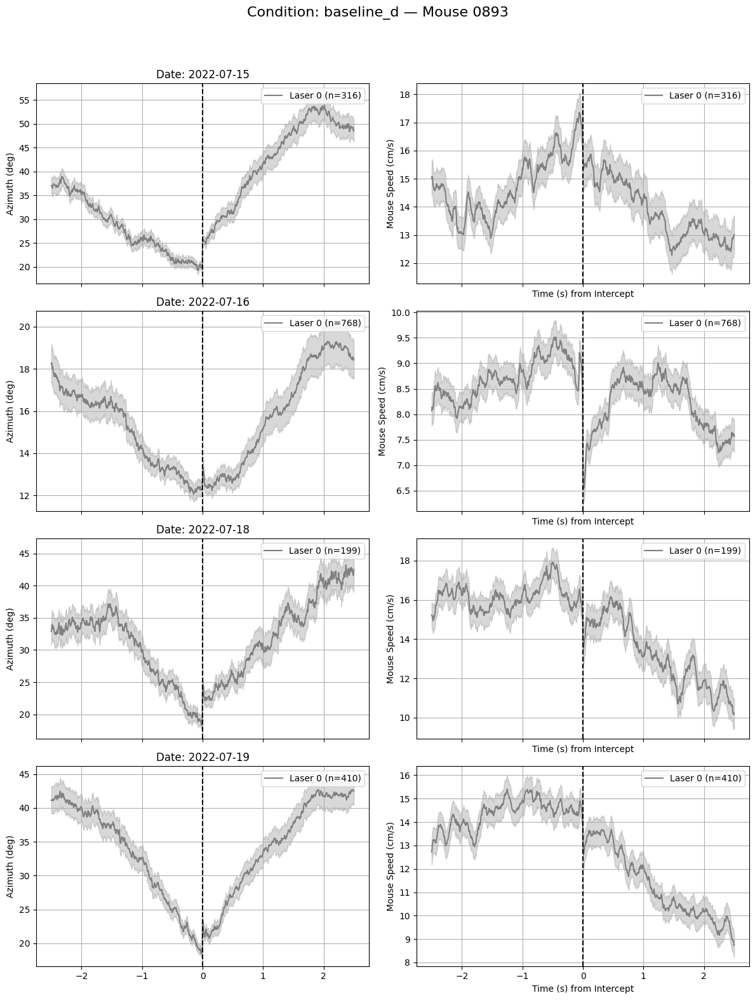

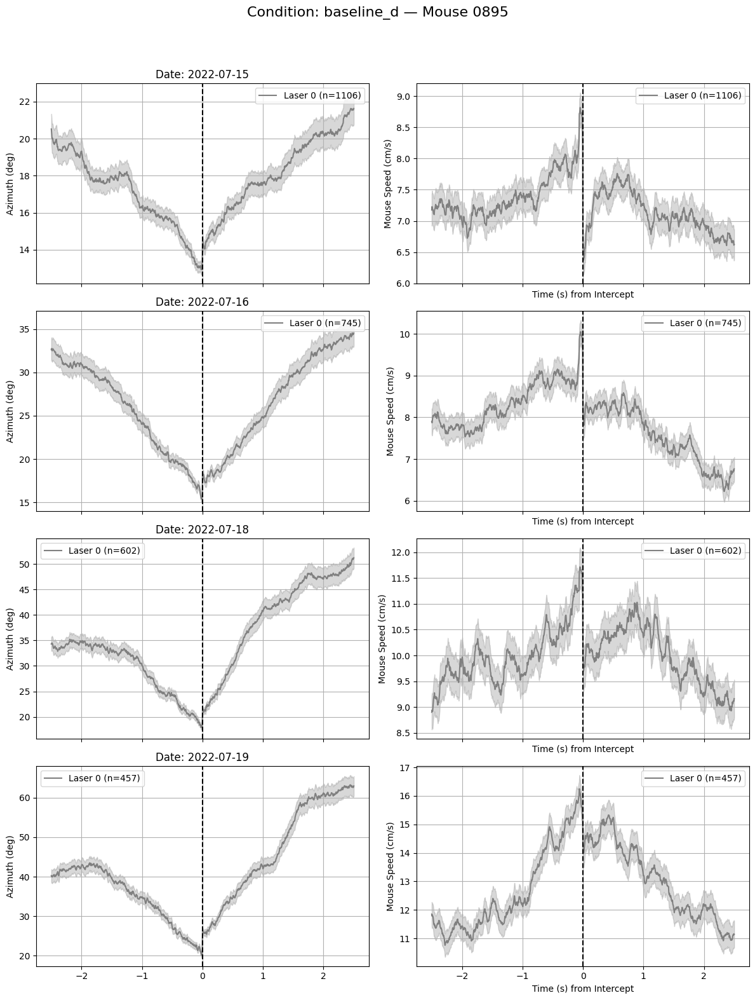

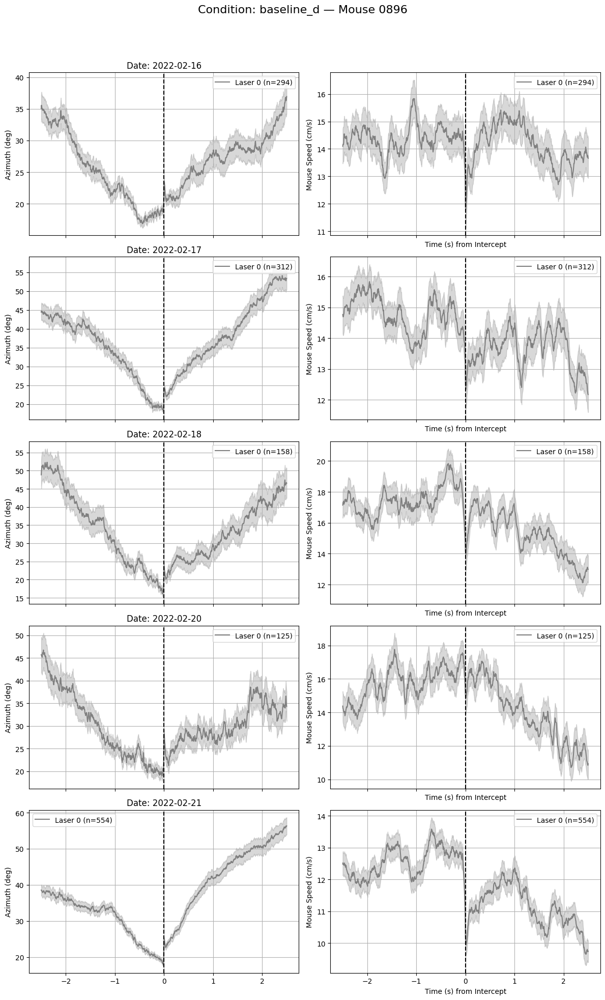

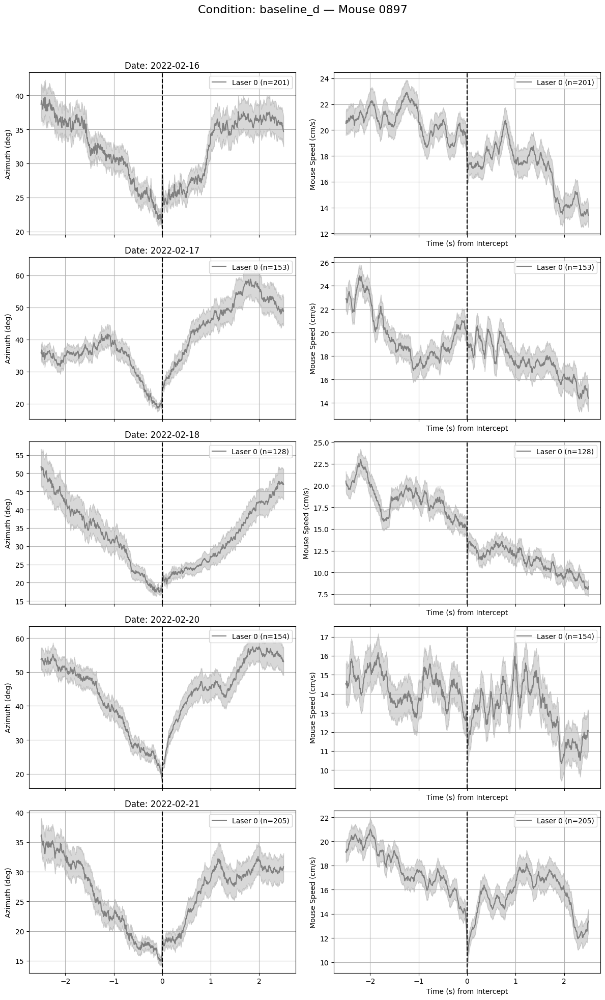

/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


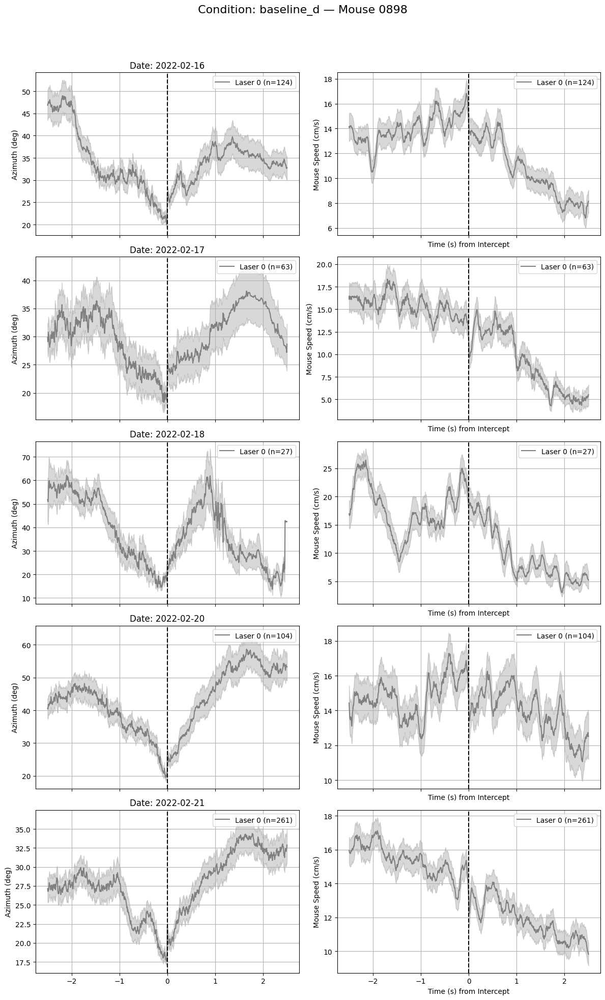

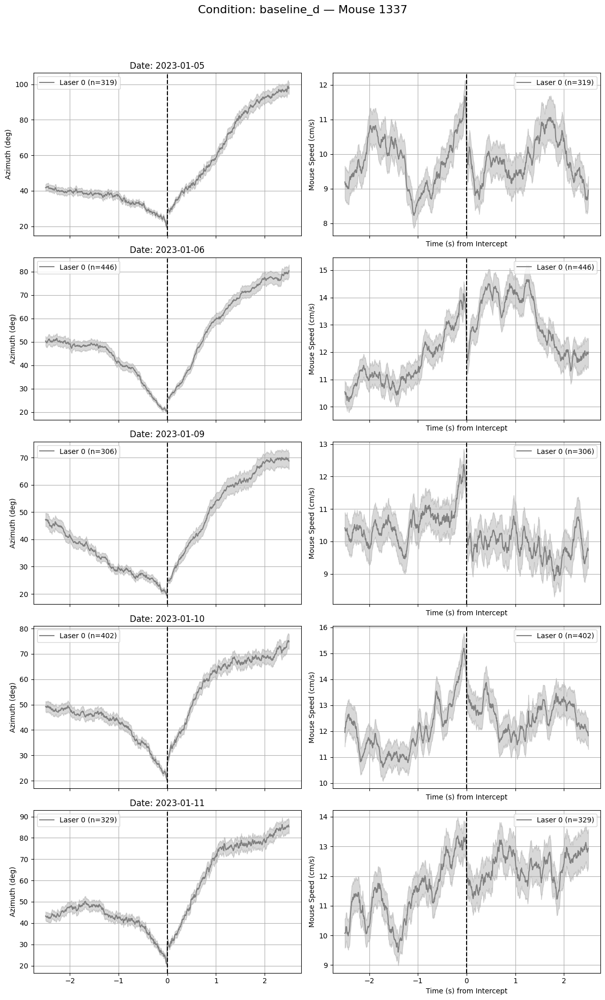

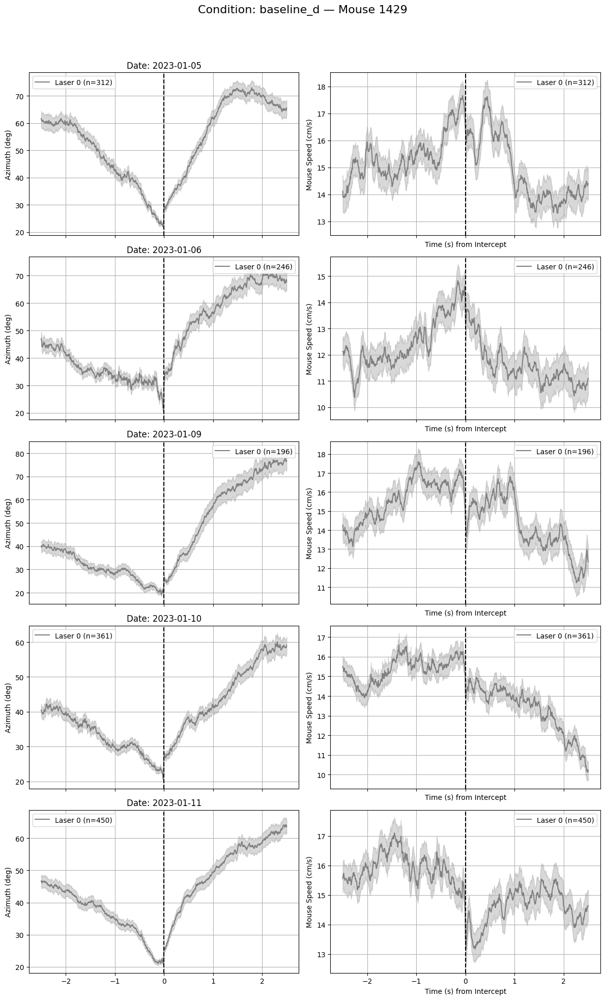

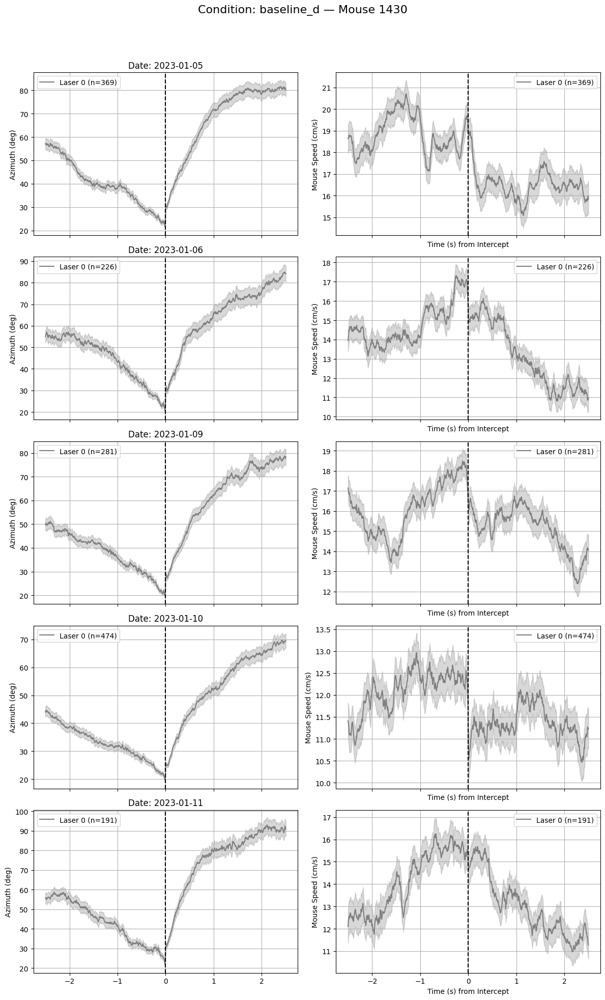

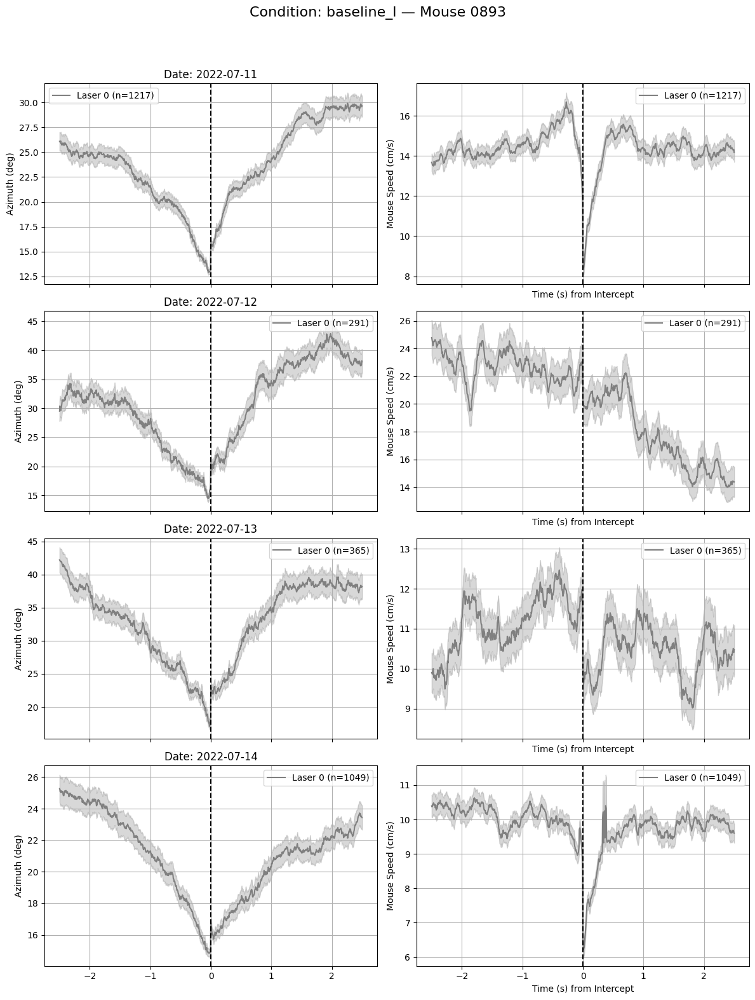

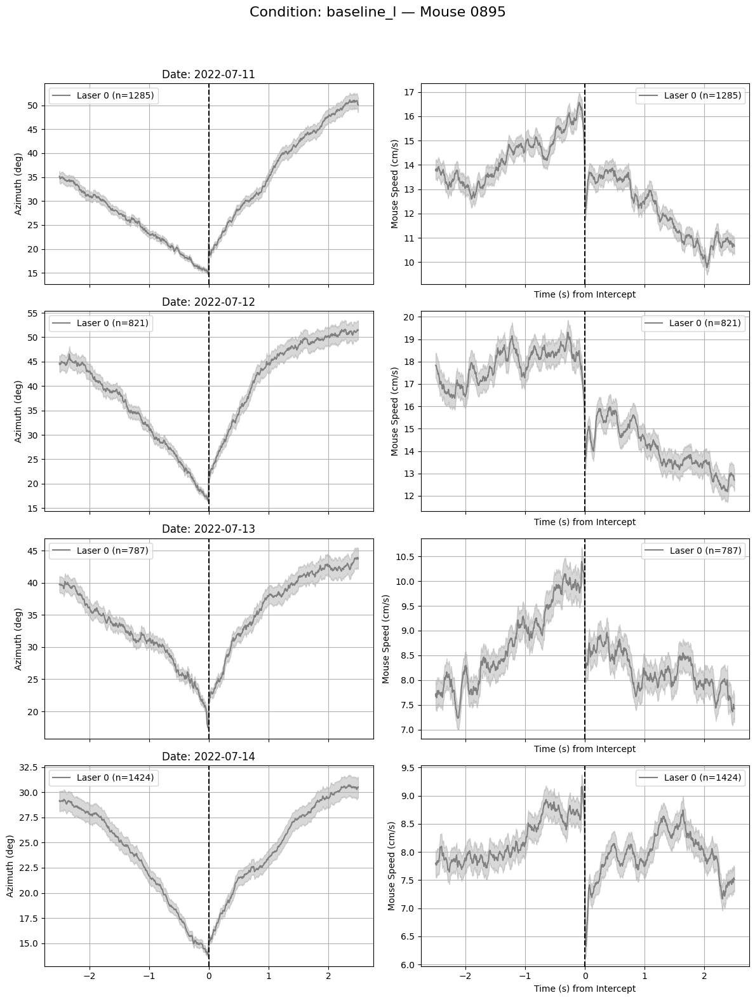

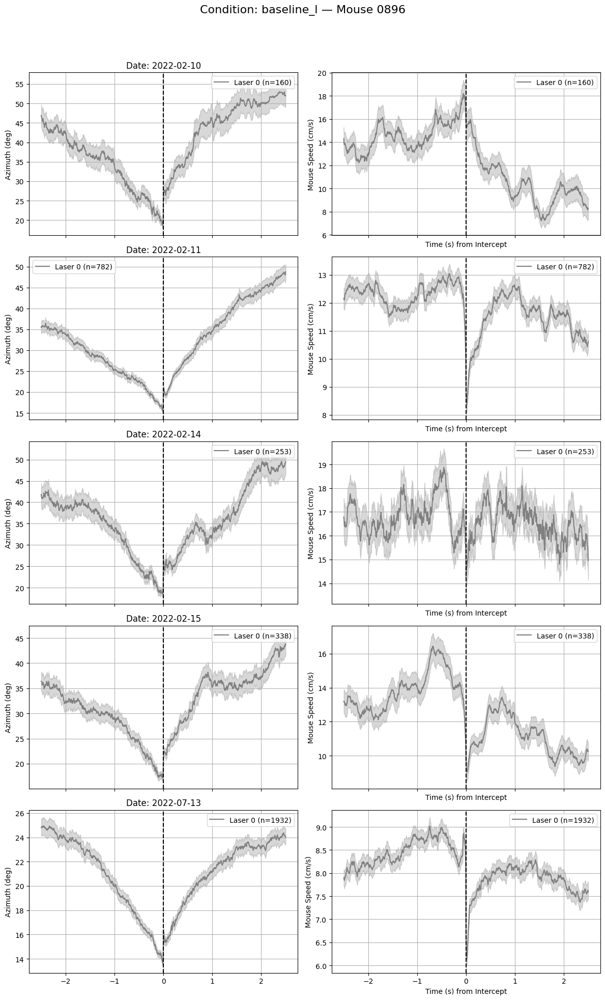

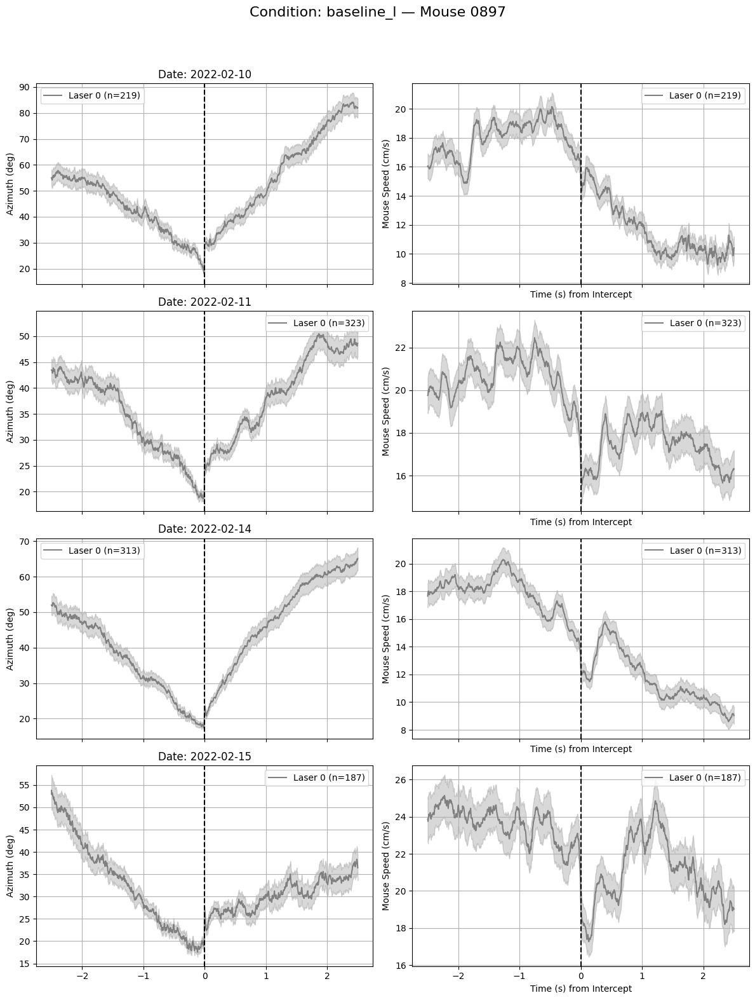

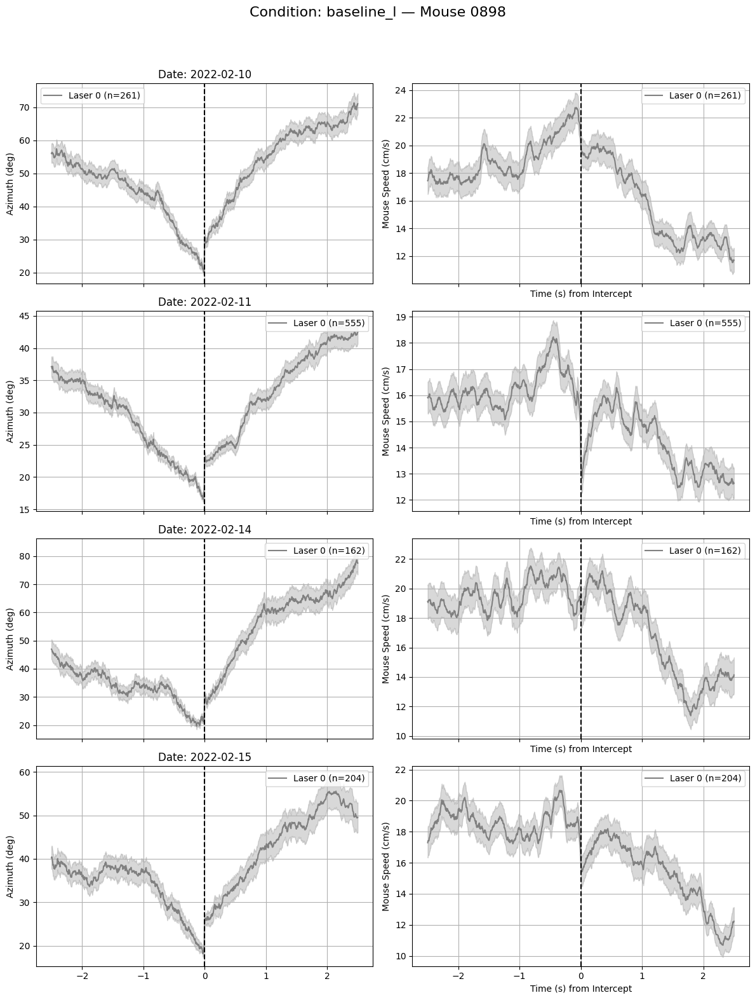

KeyboardInterrupt: 

In [126]:
plot_mean_az_spd_by_mouse(trial_df=baseline_trials, intercept_df=intercept_df)

In [132]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re
import matplotlib.cm as cm

def plot_mean_az_spd_by_mouse_all_days(trial_df: pd.DataFrame,
                                       intercept_df: pd.DataFrame,
                                       fr: int = 200,
                                       window_sec: float = 2.5):
    """
    Plot mean azimuth and speed with SEM around intercepts, grouped by mouse and condition.
    All days for one mouse and condition plotted on the same axes with different colors.

    Args:
        trial_df (pd.DataFrame): trial-level data; each row contains list-type columns.
        intercept_df (pd.DataFrame): output from intercept function; contains 'filename' and 'intercept_frames'.
        fr (int): frame rate (Hz)
        window_sec (float): window in seconds before/after intercept
    """
    window_frames = int(window_sec * fr)
    time_axis = np.arange(-window_frames, window_frames + 1) / fr

    # Merge intercept data with trial metadata
    merged = pd.merge(intercept_df, trial_df[['filename', 'mouse_spd', 'az', 'laser_value', 'condition']],
                      on='filename', how='left')

    # Extract mouse ID and date from filename
    def extract_mouse_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        return match.groups() if match else (None, None)

    merged[['date', 'mouse']] = merged['filename'].apply(lambda f: pd.Series(extract_mouse_date(f)))
    merged['date'] = pd.to_datetime(merged['date'])

    # Sort and assign day index per mouse and condition
    merged['day_index'] = merged.groupby(['condition', 'mouse'])['date'].rank(method='dense').astype(int)

    cmap = cm.get_cmap('tab10')  # colormap for days (up to 10 days)

    # Group by condition and mouse
    for (condition, mouse_id), group in merged.groupby(['condition', 'mouse']):
        fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
        fig.suptitle(f"Mouse {mouse_id} — {condition}", fontsize=16)

        # Loop over days to plot each day with a different color
        for day in sorted(group['day_index'].unique()):
            day_group = group[group['day_index'] == day]

            # For each laser value, collect all traces for this day
            for laser_val in [0, 1]:
                az_traces = []
                spd_traces = []

                for _, row in day_group.iterrows():
                    if int(row['laser_value']) != laser_val:
                        continue

                    az_series = row['az']
                    spd_series = row['mouse_spd']
                    intercept_frames = row['intercept_frames']

                    for idx in intercept_frames:
                        start = idx - window_frames
                        end = idx + window_frames
                        if start < 0 or end >= len(az_series):
                            continue
                        az_win = np.array(az_series[start:end + 1], dtype=np.float32)
                        spd_win = np.array(spd_series[start:end + 1], dtype=np.float32)
                        if len(az_win) == 2 * window_frames + 1:
                            az_traces.append(az_win)
                            spd_traces.append(spd_win)

                if not az_traces:
                    continue

                az_stack = np.vstack(az_traces)
                spd_stack = np.vstack(spd_traces)

                az_mean = np.nanmean(az_stack, axis=0)
                az_sem = np.nanstd(az_stack, axis=0, ddof=1) / np.sqrt(az_stack.shape[0])

                spd_mean = np.nanmean(spd_stack, axis=0)
                spd_sem = np.nanstd(spd_stack, axis=0, ddof=1) / np.sqrt(spd_stack.shape[0])

                # Color for day, line style for laser (solid for laser=1 blue, dashed for laser=0 gray)
                day_color = cmap((day - 1) % 10)
                linestyle = '-' if laser_val == 1 else '--'
                label = f"Day {day} Laser {laser_val} (n={az_stack.shape[0]})"

                axs[0].plot(time_axis, az_mean, color=day_color, linestyle=linestyle, label=label)
                axs[0].fill_between(time_axis, az_mean - az_sem, az_mean + az_sem, color=day_color, alpha=0.3)

                axs[1].plot(time_axis, spd_mean, color=day_color, linestyle=linestyle, label=label)
                axs[1].fill_between(time_axis, spd_mean - spd_sem, spd_mean + spd_sem, color=day_color, alpha=0.3)

        axs[0].axvline(0, color='k', linestyle='--')
        axs[0].set_ylabel("Azimuth (deg)")
        axs[0].legend(loc='upper right', fontsize=8)
        axs[0].grid(True)

        axs[1].axvline(0, color='k', linestyle='--')
        axs[1].set_ylabel("Speed (cm/s)")
        axs[1].set_xlabel("Time (s) from Intercept")
        axs[1].legend(loc='upper right', fontsize=8)
        axs[1].grid(True)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()


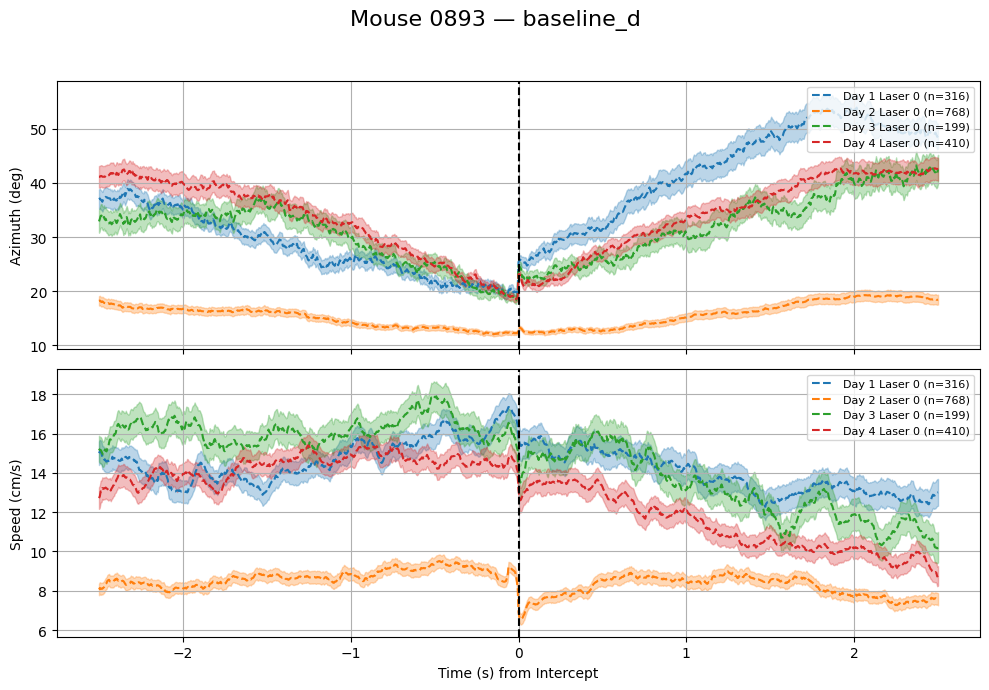

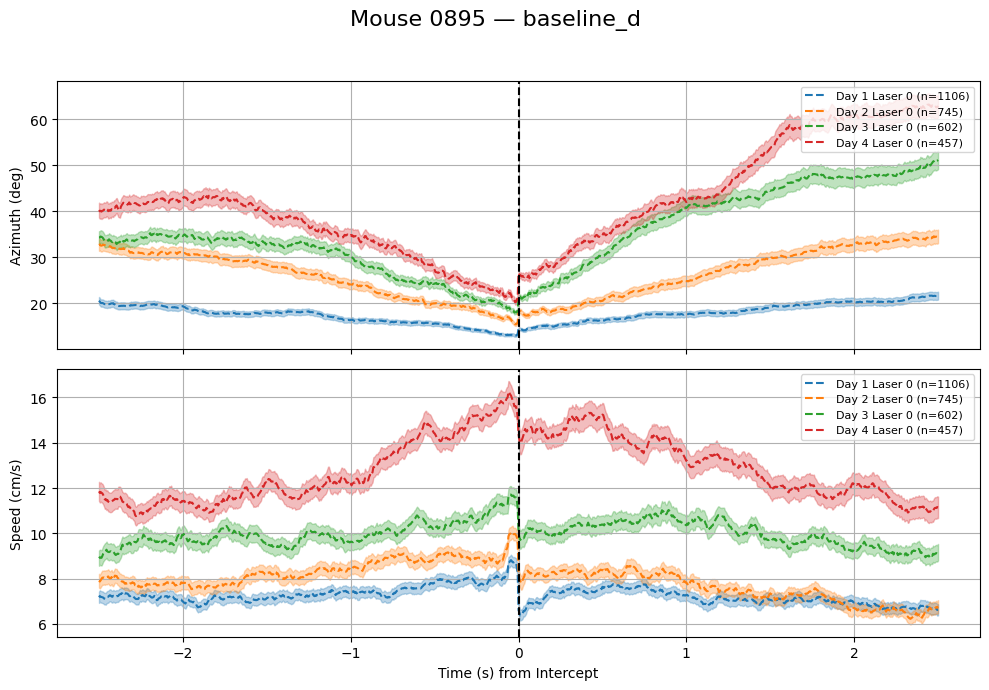

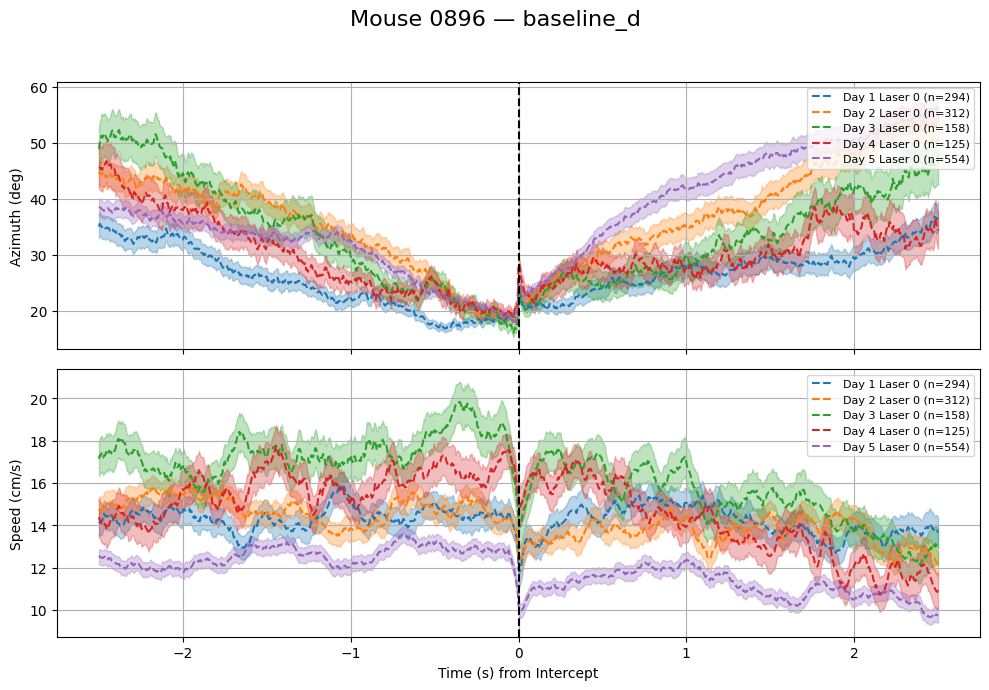

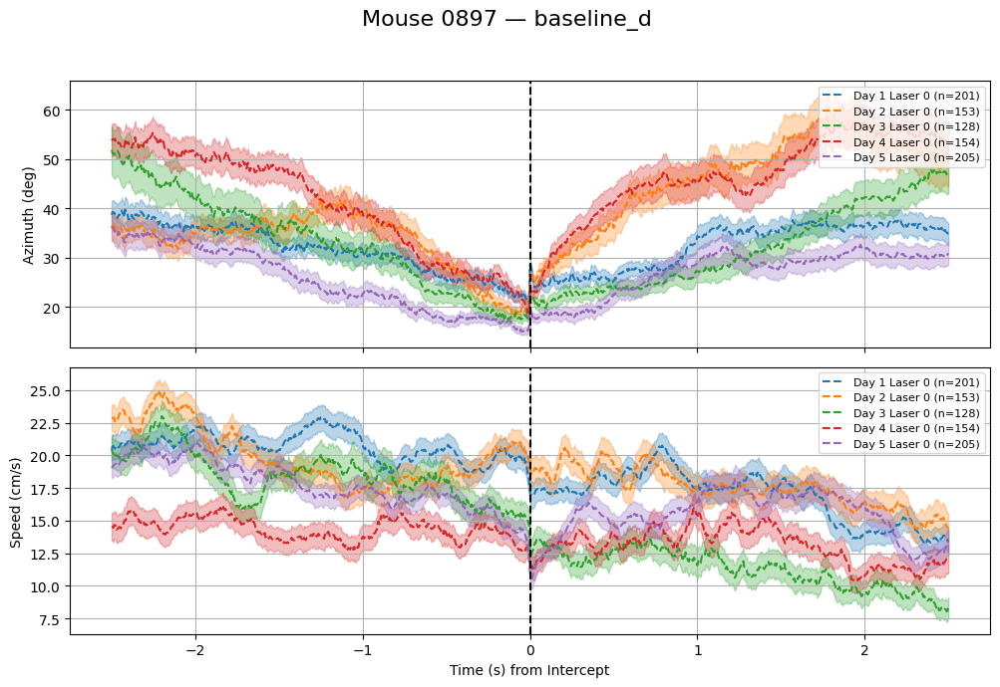

/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


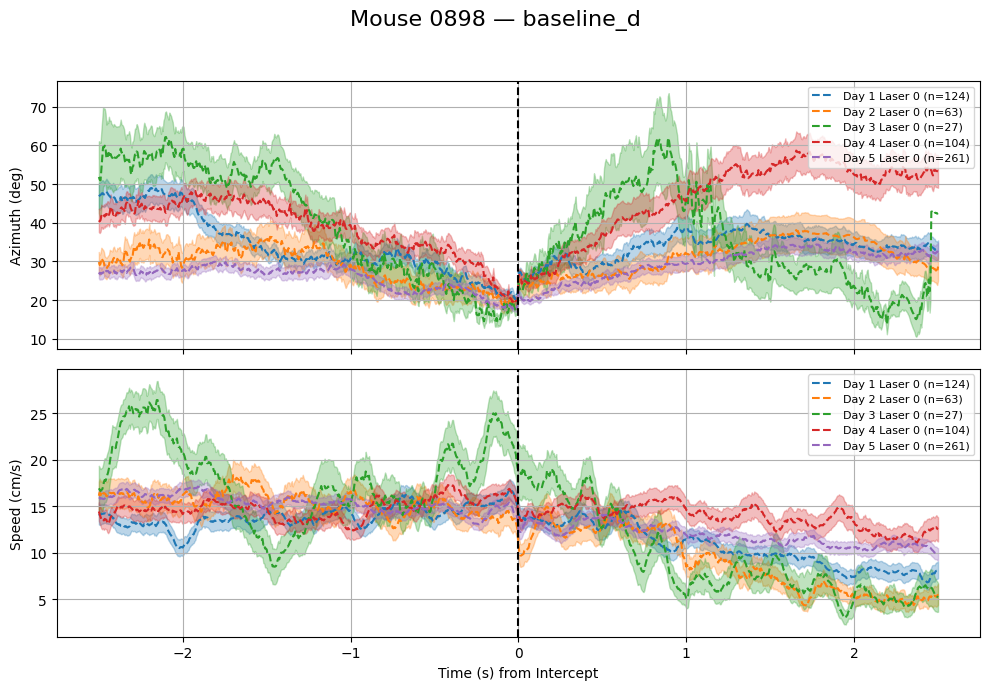

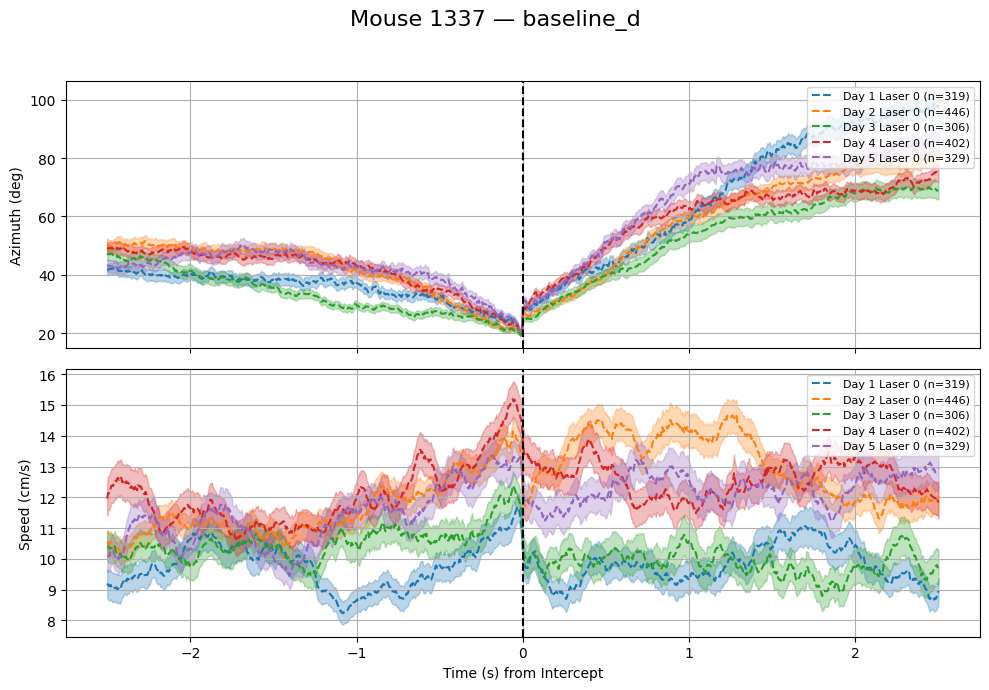

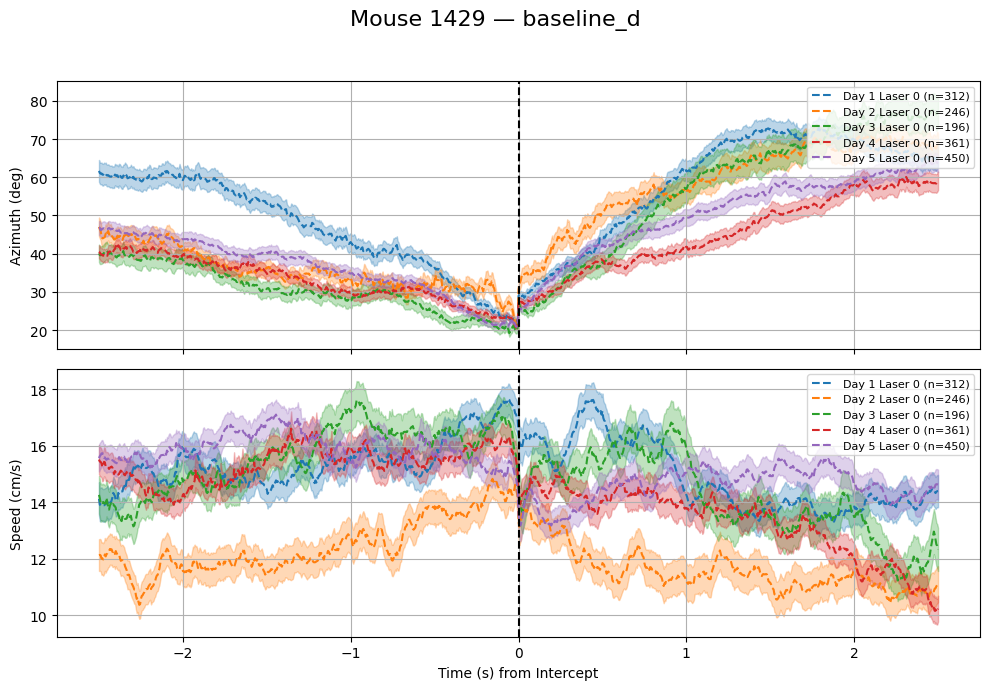

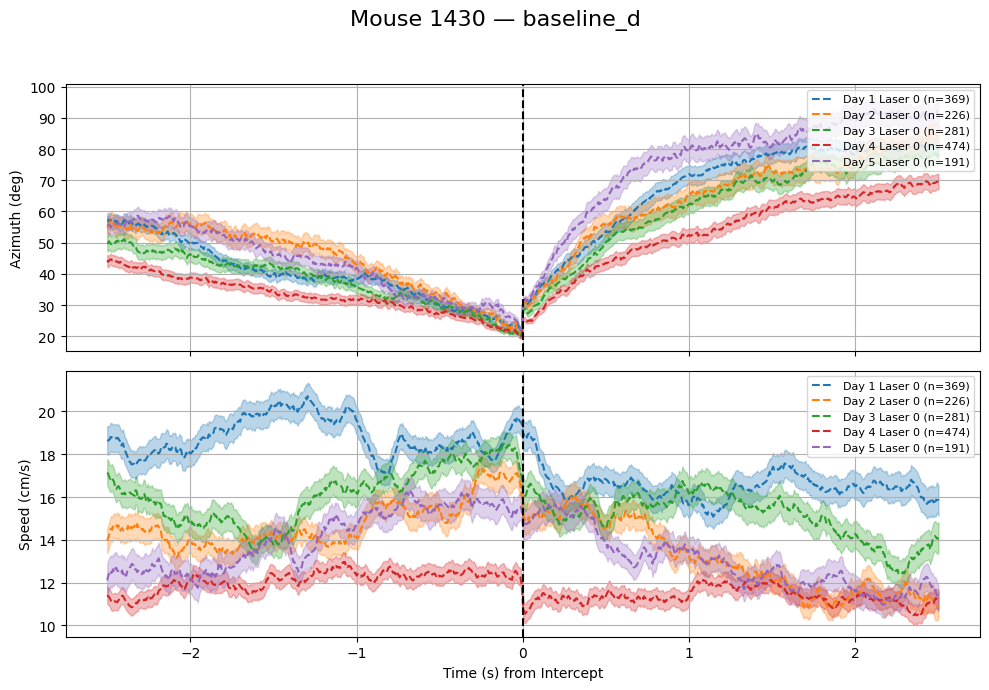

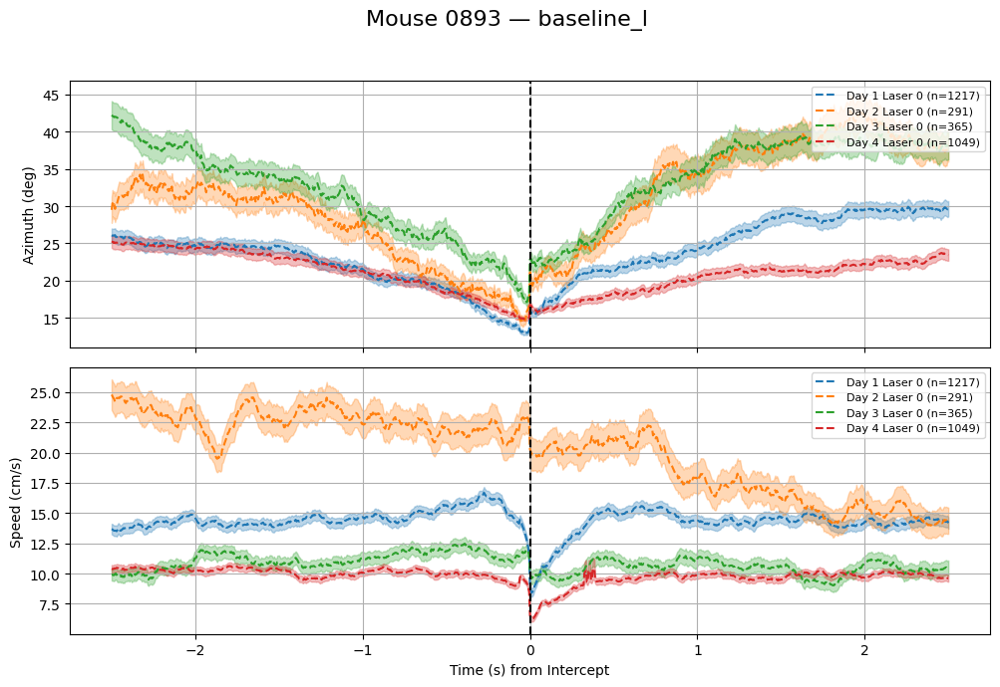

...

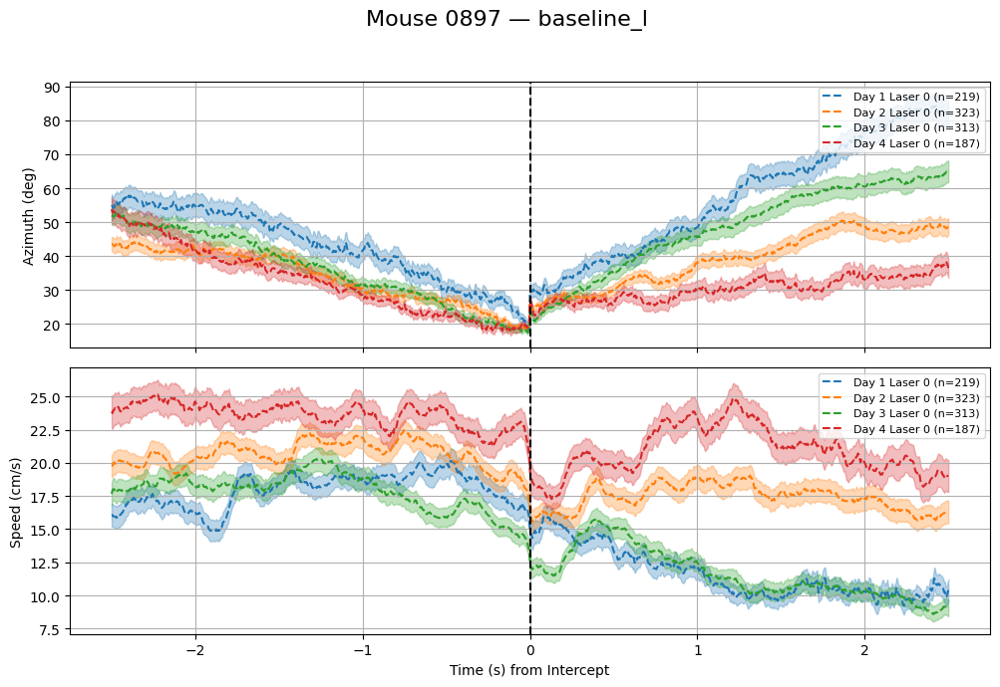

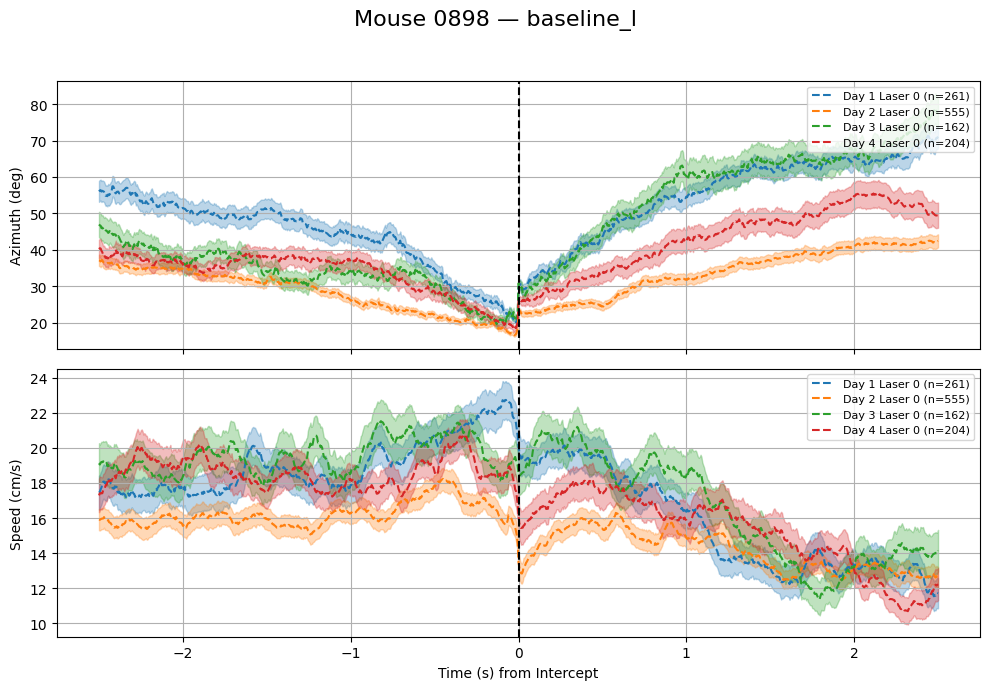

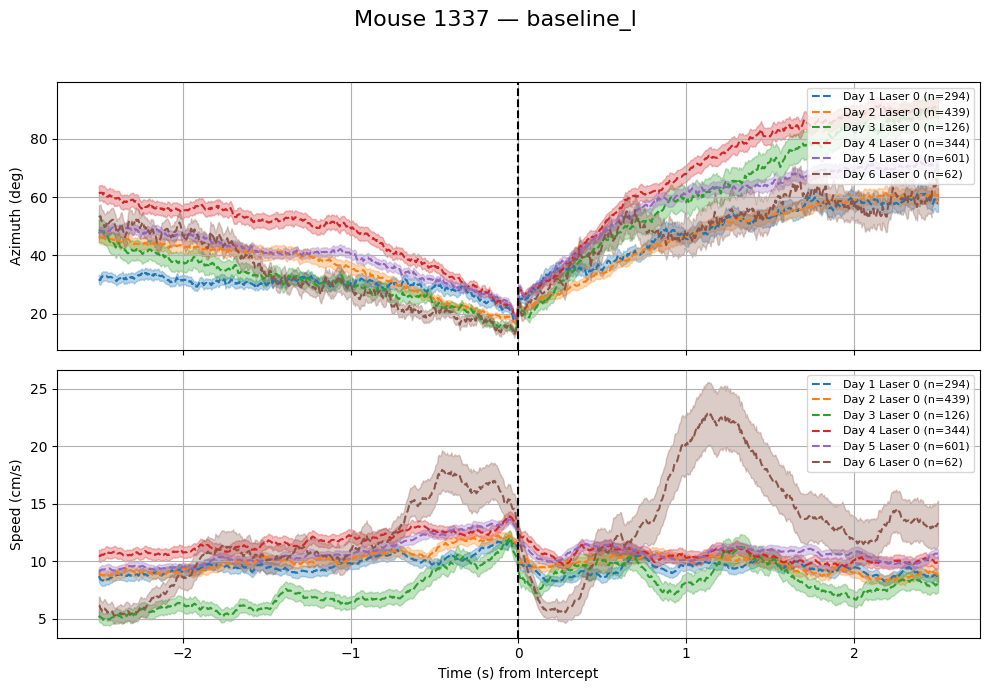

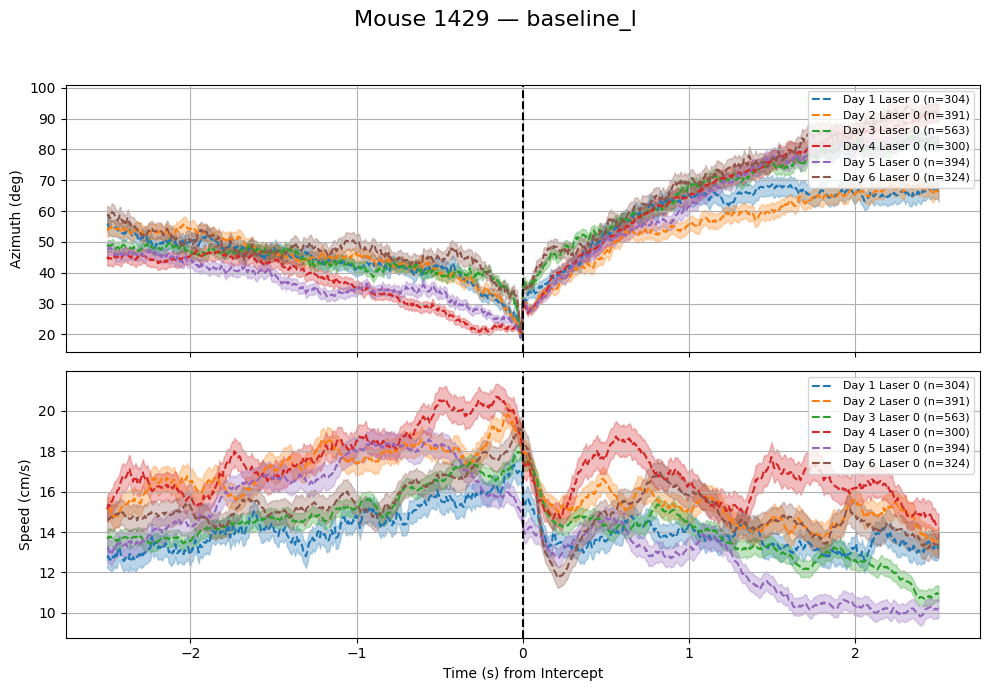

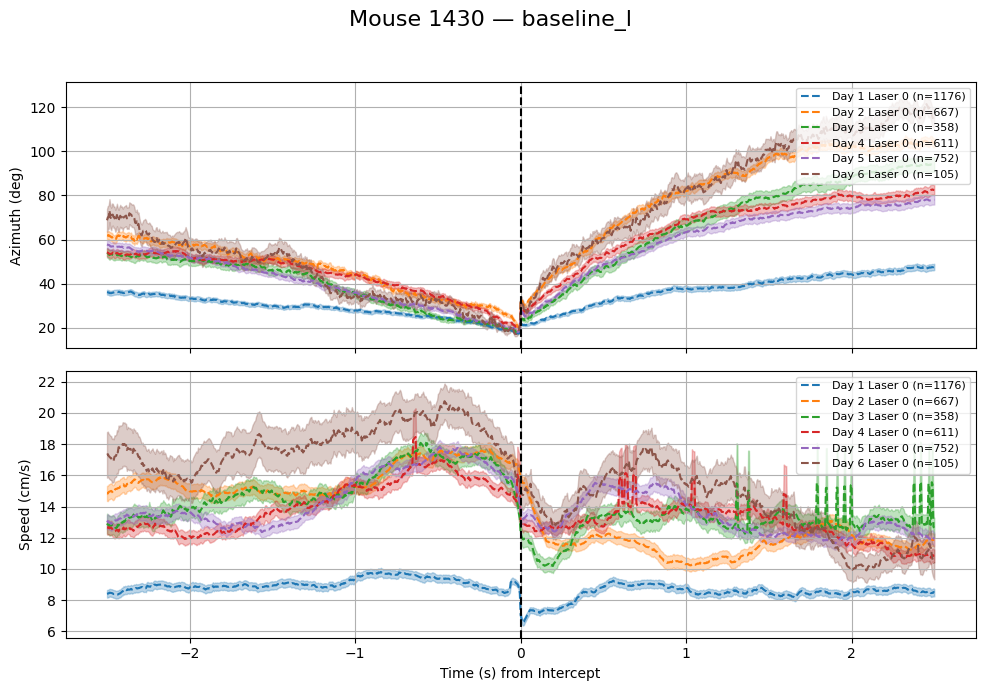

In [133]:
plot_mean_az_spd_by_mouse_all_days(trial_df=baseline_trials,
                                       intercept_df=intercept_df,
                                       fr=200,
                                       window_sec=2.5)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re
import matplotlib.cm as cm

def plot_mean_az_spd_by_mouse_all_days(trial_df: pd.DataFrame,
                                       intercept_df: pd.DataFrame,
                                       fr: int = 200,
                                       window_sec: float = 2.5):
    """
    Plot mean azimuth and speed with SEM around intercepts, grouped by mouse and condition.
    All days for one mouse and condition plotted on the same axes with different colors.

    Args:
        trial_df (pd.DataFrame): trial-level data; each row contains list-type columns.
        intercept_df (pd.DataFrame): output from intercept function; contains 'filename' and 'intercept_frames'.
        fr (int): frame rate (Hz)
        window_sec (float): window in seconds before/after intercept
    """
    window_frames = int(window_sec * fr)
    time_axis = np.arange(-window_frames, window_frames + 1) / fr

    # Merge intercept data with trial metadata
    merged = pd.merge(intercept_df, trial_df[['filename', 'mouse_spd', 'az', 'laser_value', 'condition']],
                      on='filename', how='left')

    # Extract mouse ID and date from filename
    def extract_mouse_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        return match.groups() if match else (None, None)

    merged[['date', 'mouse']] = merged['filename'].apply(lambda f: pd.Series(extract_mouse_date(f)))
    merged['date'] = pd.to_datetime(merged['date'])

    # Sort and assign day index per mouse and condition
    merged['day_index'] = merged.groupby(['condition', 'mouse'])['date'].rank(method='dense').astype(int)

    cmap = cm.get_cmap('tab10')  # colormap for days (up to 10 days)

    # Group by condition and mouse
    for (condition, mouse_id), group in merged.groupby(['condition', 'mouse']):
        fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
        fig.suptitle(f"Mouse {mouse_id} — {condition}", fontsize=16)

        # Loop over days to plot each day with a different color
        for day in sorted(group['day_index'].unique()):
            day_group = group[group['day_index'] == day]

            # For each laser value, collect all traces for this day
            for laser_val in [0, 1]:
                az_traces = []
                spd_traces = []

                for _, row in day_group.iterrows():
                    if int(row['laser_value']) != laser_val:
                        continue

                    az_series = row['az']
                    spd_series = row['mouse_spd']
                    intercept_frames = row['intercept_frames']

                    for idx in intercept_frames:
                        start = idx - window_frames
                        end = idx + window_frames
                        if start < 0 or end >= len(az_series):
                            continue
                        az_win = np.array(az_series[start:end + 1], dtype=np.float32)
                        spd_win = np.array(spd_series[start:end + 1], dtype=np.float32)
                        if len(az_win) == 2 * window_frames + 1:
                            az_traces.append(az_win)
                            spd_traces.append(spd_win)

                if not az_traces:
                    continue

                az_stack = np.vstack(az_traces)
                spd_stack = np.vstack(spd_traces)

                az_mean = np.nanmean(az_stack, axis=0)
                az_sem = np.nanstd(az_stack, axis=0, ddof=1) / np.sqrt(az_stack.shape[0])

                spd_mean = np.nanmean(spd_stack, axis=0)
                spd_sem = np.nanstd(spd_stack, axis=0, ddof=1) / np.sqrt(spd_stack.shape[0])

                # Color for day, line style for laser (solid for laser=1 blue, dashed for laser=0 gray)
                day_color = cmap((day - 1) % 10)
                linestyle = '-' if laser_val == 1 else '--'
                label = f"Day {day} Laser {laser_val} (n={az_stack.shape[0]})"

                axs[0].plot(time_axis, az_mean, color=day_color, linestyle=linestyle, label=label)
                axs[0].fill_between(time_axis, az_mean - az_sem, az_mean + az_sem, color=day_color, alpha=0.3)

                axs[1].plot(time_axis, spd_mean, color=day_color, linestyle=linestyle, label=label)
                axs[1].fill_between(time_axis, spd_mean - spd_sem, spd_mean + spd_sem, color=day_color, alpha=0.3)

        axs[0].axvline(0, color='k', linestyle='--')
        axs[0].set_ylabel("Azimuth (deg)")
        axs[0].legend(loc='upper right', fontsize=8)
        axs[0].grid(True)

        axs[1].axvline(0, color='k', linestyle='--')
        axs[1].set_ylabel("Speed (cm/s)")
        axs[1].set_xlabel("Time (s) from Intercept")
        axs[1].legend(loc='upper right', fontsize=8)
        axs[1].grid(True)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()


In [449]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

def plot_pooled_by_day(trial_df: pd.DataFrame,
                       intercept_df: pd.DataFrame,
                       fr: int = 200,
                       window_sec: float = 2.5):
    """
    Plot pooled mean azimuth and speed (with SEM) across mice for each day and condition.
    Creates one plot per day per condition.

    Args:
        trial_df (pd.DataFrame): trial-level DataFrame with az, mouse_spd, condition, laser_value
        intercept_df (pd.DataFrame): DataFrame with intercept_frames and filename per trial
        fr (int): frame rate (Hz)
        window_sec (float): seconds before and after intercept
    """
    window_frames = int(window_sec * fr)
    time_axis = np.arange(-window_frames, window_frames + 1) / fr

    # Merge with metadata
    merged = pd.merge(intercept_df, trial_df[['filename', 'mouse_spd', 'az', 'laser_value', 'condition']],
                      on='filename', how='left')

    # Extract date and mouse ID
    def extract_mouse_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        return match.groups() if match else (None, None)

    merged[['date', 'mouse']] = merged['filename'].apply(lambda f: pd.Series(extract_mouse_date(f)))
    merged['date'] = pd.to_datetime(merged['date'])

    # Assign Day 1, 2, ... per mouse and condition
    merged['day_index'] = merged.groupby(['condition', 'mouse'])['date'].rank(method='dense').astype(int)

    # Group across all mice by (condition, day)
    for (condition, day), group in merged.groupby(['condition', 'day_index']):
        az_traces = {0: [], 1: []}
        spd_traces = {0: [], 1: []}
        counts = {0: 0, 1: 0}

        for _, row in group.iterrows():
            # Skip NaNs or bad laser values
            if pd.isna(row['laser_value']):
                continue
            try:
                laser_val = int(row['laser_value'])
                if laser_val not in [0, 1]:
                    continue
            except (ValueError, TypeError):
                continue

            az_series = row['az']
            spd_series = row['mouse_spd']
            intercepts = row['intercept_frames']

            for idx in intercepts:
                start = idx - window_frames
                end = idx + window_frames
                if start < 0 or end >= len(az_series):
                    continue
                az_win = np.array(az_series[start:end + 1], dtype=np.float32)
                spd_win = np.array(spd_series[start:end + 1], dtype=np.float32)
                if len(az_win) == 2 * window_frames + 1:
                    az_traces[laser_val].append(az_win)
                    spd_traces[laser_val].append(spd_win)
                    counts[laser_val] += 1

        # Skip if no data
        if counts[0] == 0 and counts[1] == 0:
            continue

        # Plot
        fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
        fig.suptitle(f"{condition} — Day {day}", fontsize=16)

        for laser_val, color in zip([0, 1], ['gray', 'blue']):
            if counts[laser_val] == 0:
                continue

            az_stack = np.vstack(az_traces[laser_val])
            spd_stack = np.vstack(spd_traces[laser_val])

            az_mean = np.nanmean(az_stack, axis=0)
            az_sem = np.nanstd(az_stack, axis=0, ddof=1) / np.sqrt(az_stack.shape[0])

            spd_mean = np.nanmean(spd_stack, axis=0)
            spd_sem = np.nanstd(spd_stack, axis=0, ddof=1) / np.sqrt(spd_stack.shape[0])

            label = f"Laser {laser_val} (n={counts[laser_val]})"

            axs[0].plot(time_axis, az_mean, color=color, label=label)
            axs[0].fill_between(time_axis, az_mean - az_sem, az_mean + az_sem, color=color, alpha=0.3)

            axs[1].plot(time_axis, spd_mean, color=color, label=label)
            axs[1].fill_between(time_axis, spd_mean - spd_sem, spd_mean + spd_sem, color=color, alpha=0.3)

        axs[0].axvline(0, color='k', linestyle='--')
        axs[0].set_ylabel("Azimuth (deg)")
        axs[0].legend()
        axs[0].grid(True)

        axs[1].axvline(0, color='k', linestyle='--')
        axs[1].set_ylabel("Speed (cm/s)")
        axs[1].set_xlabel("Time (s) from Intercept")
        axs[1].legend()
        axs[1].grid(True)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()


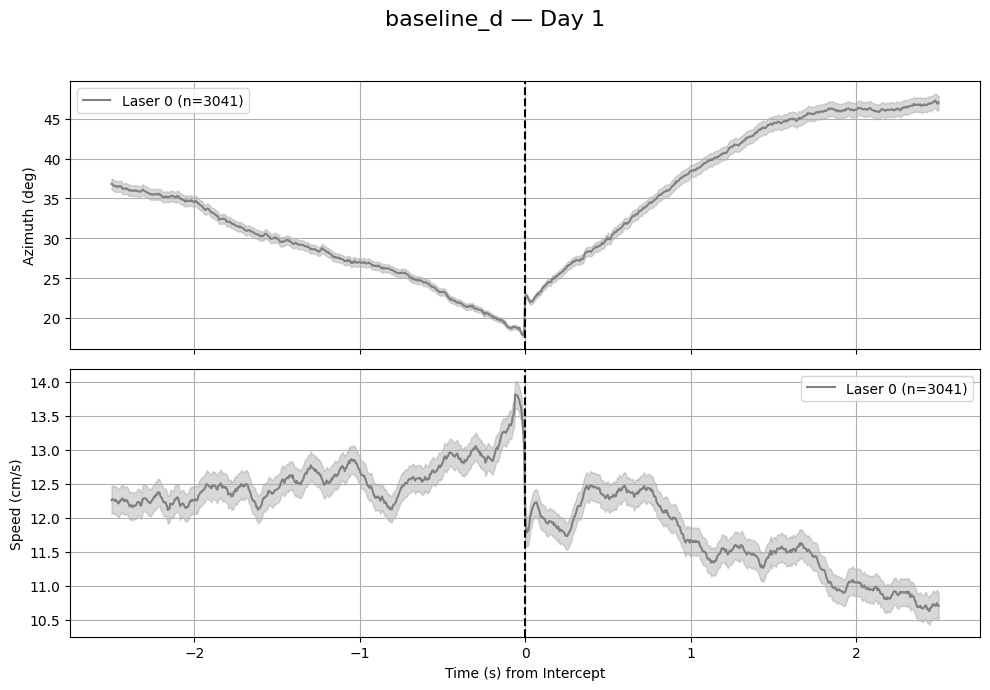

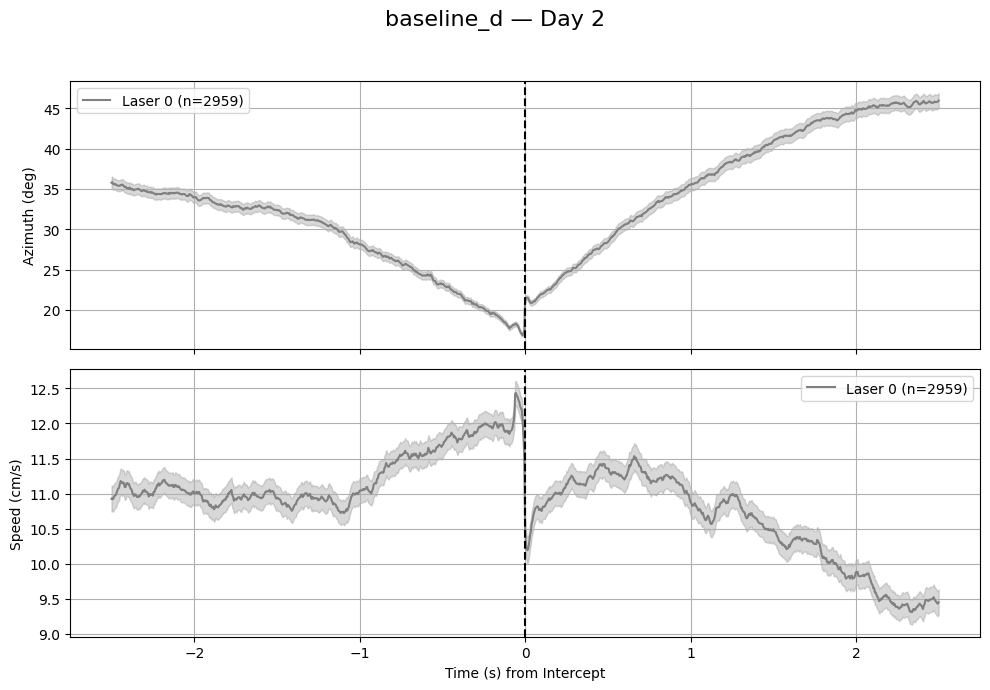

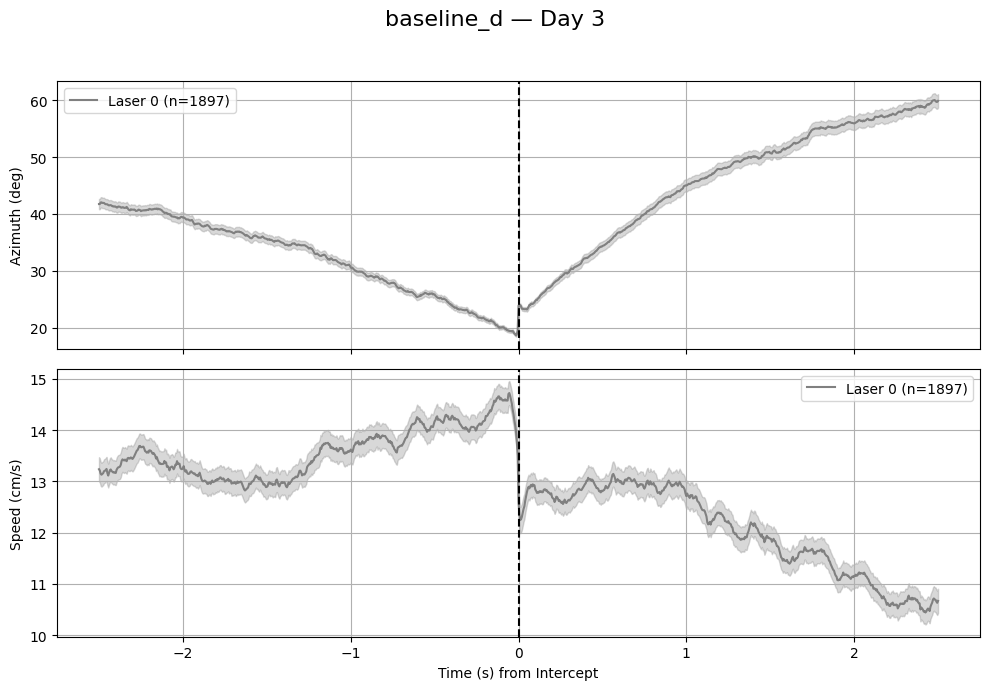

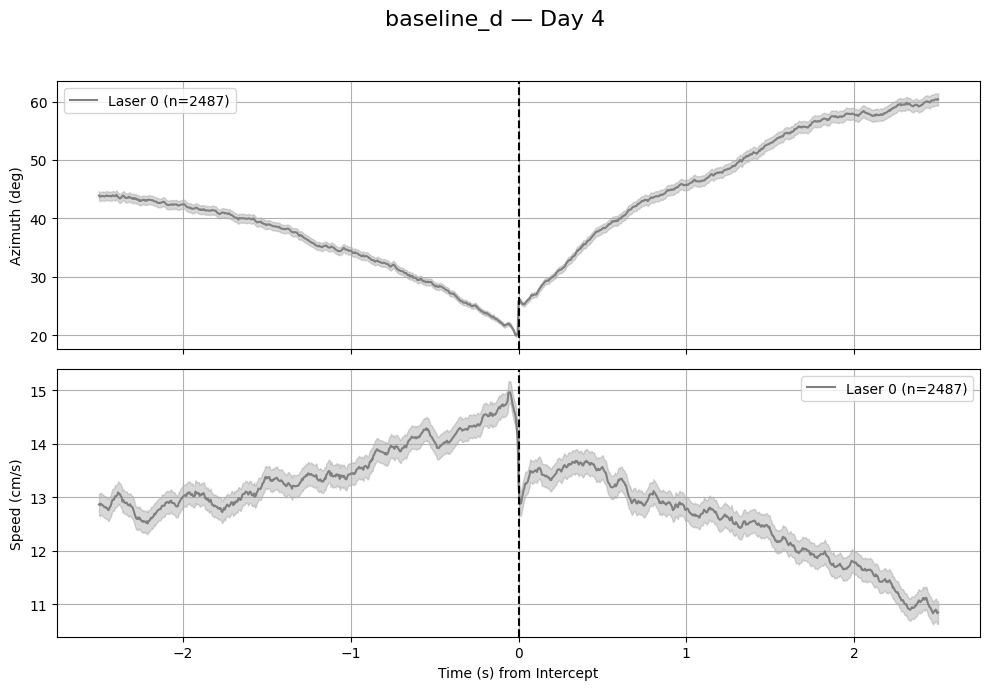

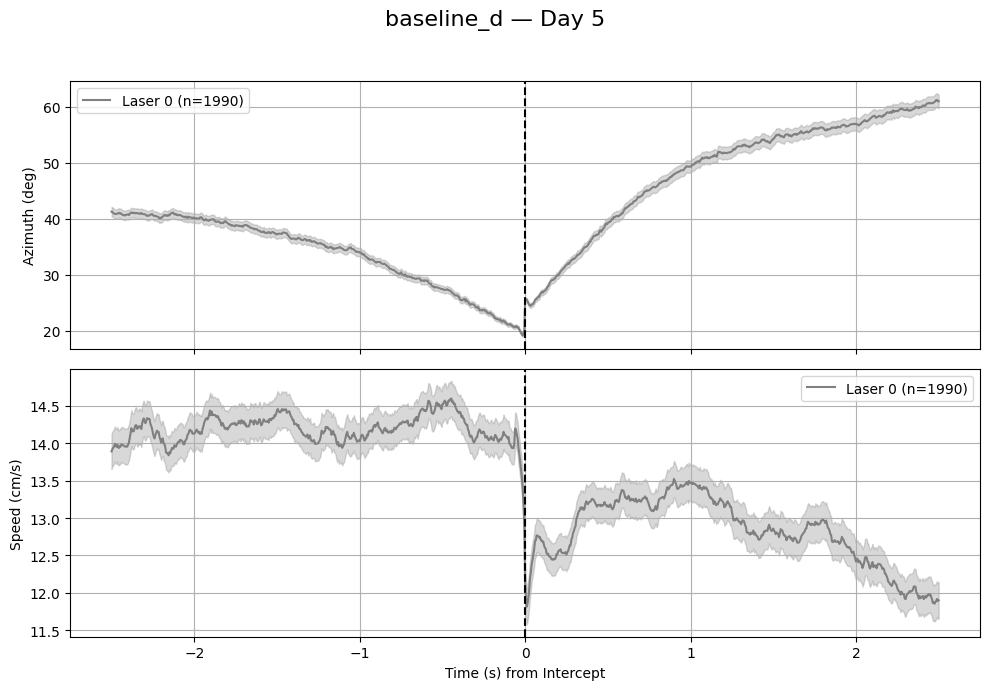

...

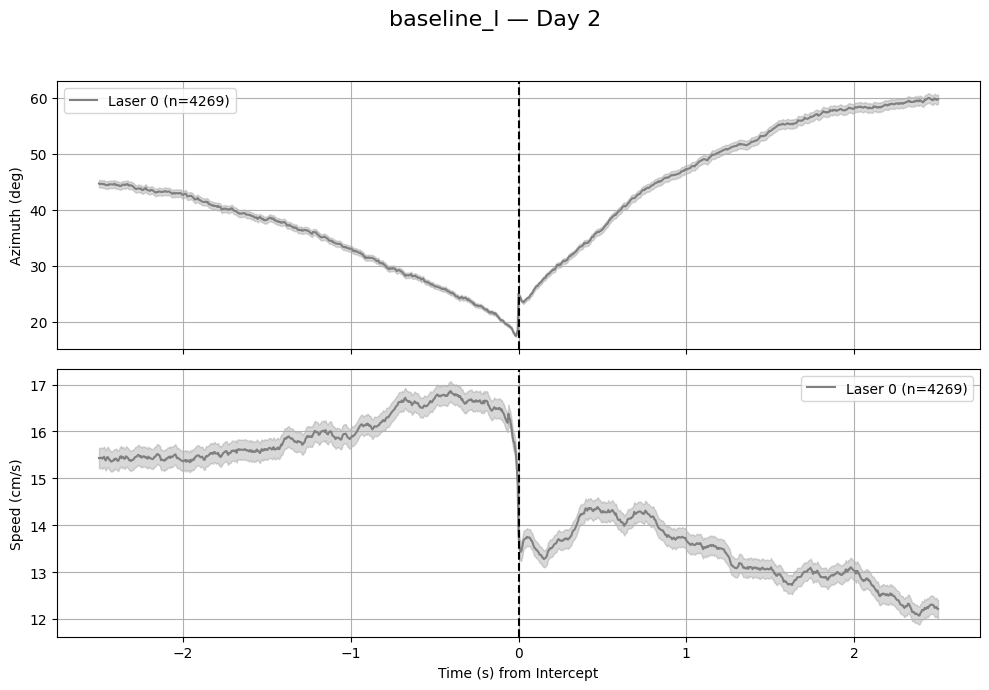

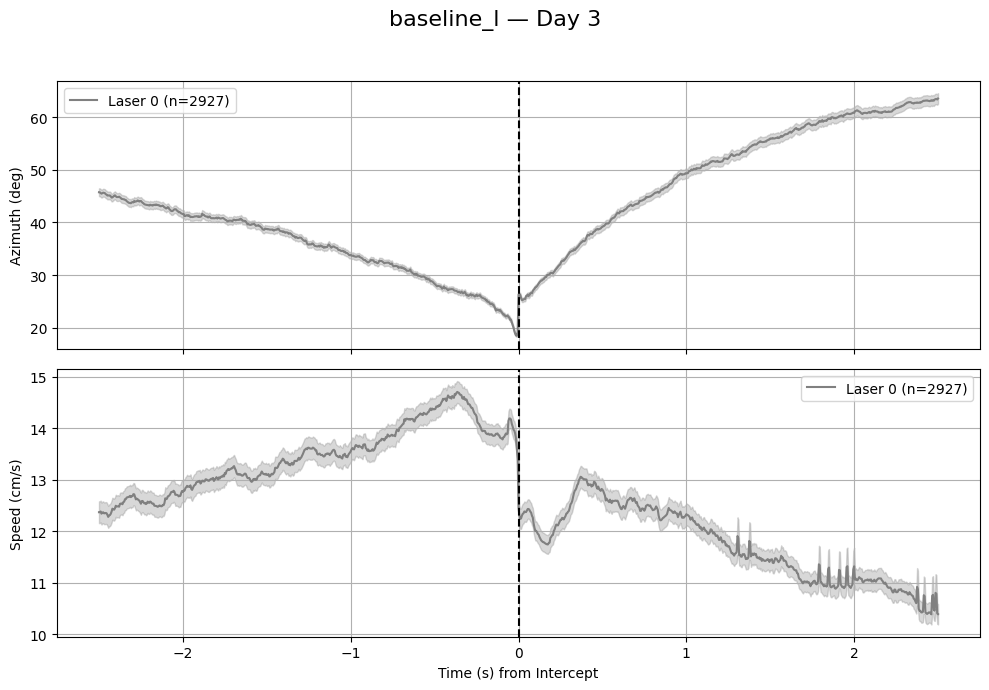

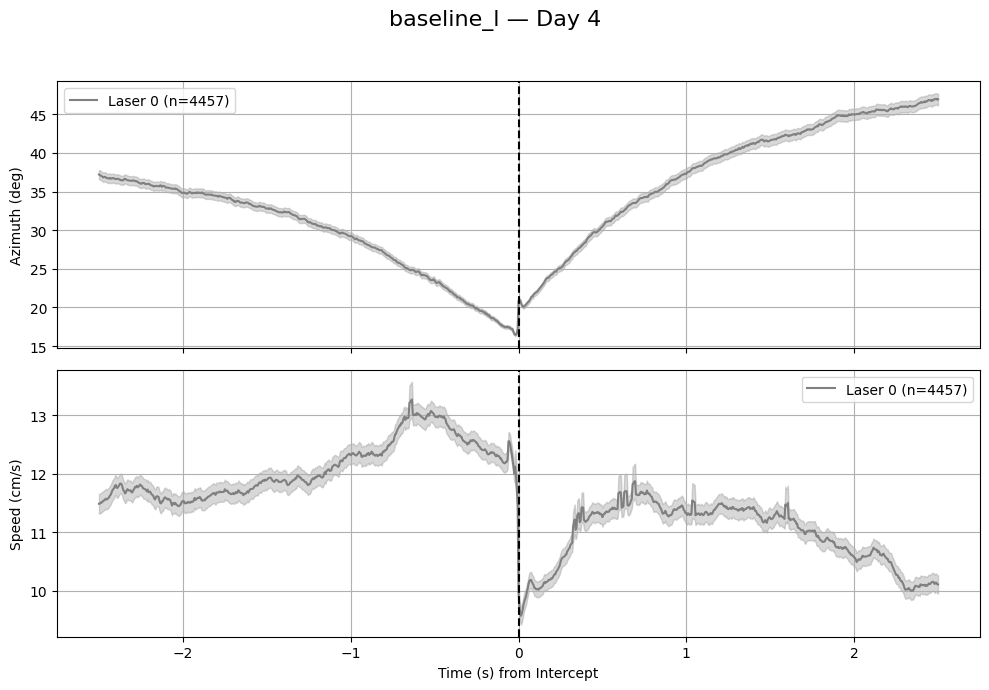

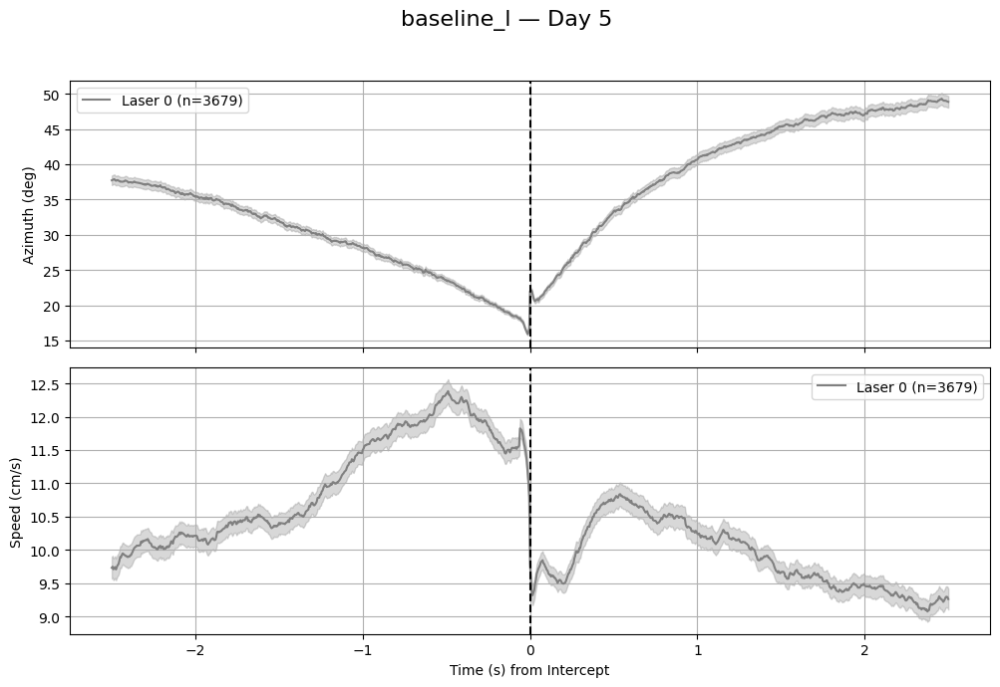

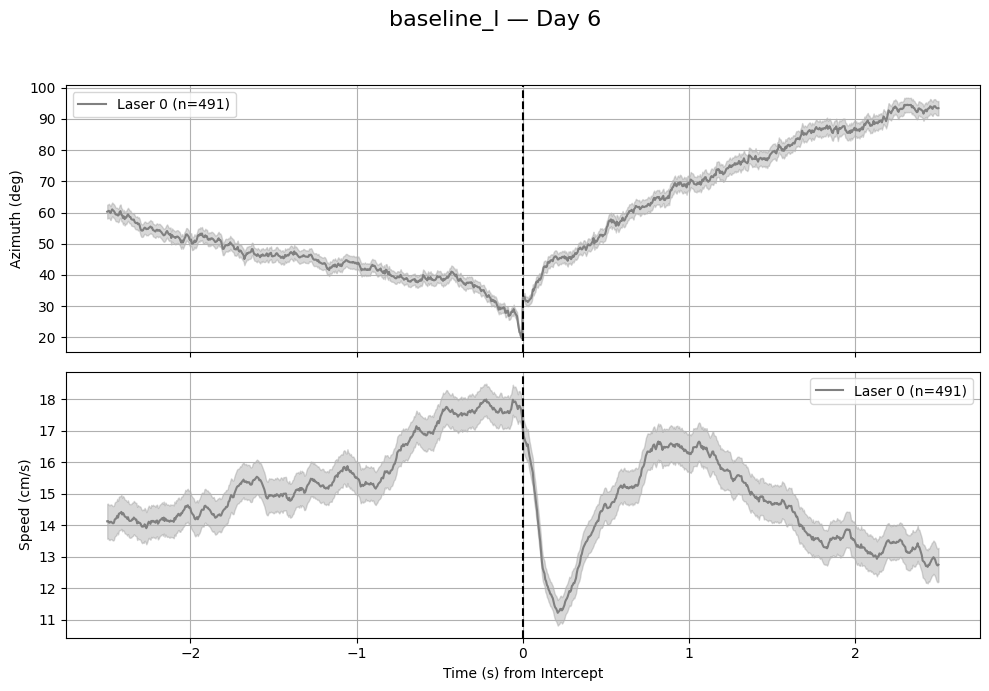

In [128]:
plot_pooled_by_day(trial_df=baseline_trials,
                   intercept_df=intercepts_df,
                   fr=200,
                   window_sec=2.5)

In [240]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re
import os
from scipy.stats import mannwhitneyu

def plot_pooled_all_days_median_on_one(trial_df: pd.DataFrame,
                                       intercept_df: pd.DataFrame,
                                       save_dir: str,
                                       fr: int = 200,
                                       window_sec: float = 2.5):
    window_frames = int(window_sec * fr)
    time_axis = np.arange(-window_frames, window_frames + 1) / fr

    if not os.path.exists(save_dir):
        os.makedirs(save_dir)

    # Merge metadata
    merged = pd.merge(intercept_df, trial_df[['filename', 'mouse_spd', 'az', 'laser_value', 'condition']],
                      on='filename', how='left')

    def extract_mouse_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        return match.groups() if match else (None, None)

    merged[['date', 'mouse']] = merged['filename'].apply(lambda f: pd.Series(extract_mouse_date(f)))
    merged['date'] = pd.to_datetime(merged['date'])
    merged['day_index'] = merged.groupby(['condition', 'mouse'])['date'].rank(method='dense').astype(int)

    # Drop Day 6 from Light condition
    merged = merged[~((merged['condition'] == 'baseline_l') & (merged['day_index'] == 6))]

    colors = {'baseline_l': 'orange', 'baseline_d': 'purple'}

    # -------------------------
    # 1) Time series plots for az and mouse_spd
    # -------------------------
    for metric, ylabel in [('az', 'Azimuth (deg)'), ('mouse_spd', 'Speed (cm/s)')]:
        fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
        fig.suptitle(f"{ylabel} Time Series — Day 1 (left) vs Day 5 (right)", fontsize=16)

        for i, day in enumerate([1, 5]):
            ax = axs[i]
            ax.set_title(f"Day {day}")
            ax.set_xlabel("Time (s) from Intercept")
            if i == 0:
                ax.set_ylabel(ylabel)
            ax.axvline(0, color='k', linestyle='--')
            ax.grid(True)

            for cond in ['baseline_l', 'baseline_d']:
                cond_group = merged[(merged['condition'] == cond) & (merged['day_index'] == day)]

                metric_traces = []
                mice_set = set()
                intercept_count = 0

                for _, row in cond_group.iterrows():
                    mice_set.add(row['mouse'])
                    for idx in row['intercept_frames']:
                        start = idx - window_frames
                        end = idx + window_frames
                        if start < 0 or end >= len(row[metric]):
                            continue
                        win = np.array(row[metric][start:end + 1], dtype=np.float32)
                        if len(win) == 2 * window_frames + 1:
                            metric_traces.append(win)
                            intercept_count += 1

                if not metric_traces:
                    continue

                stack = np.vstack(metric_traces)
                median = np.nanmedian(stack, axis=0)
                sem = np.nanstd(stack, axis=0, ddof=1) / np.sqrt(stack.shape[0])

                label = f"{'Light' if cond == 'baseline_l' else 'Dark'} (Mice: {len(mice_set)}, Contacts: {intercept_count})"
                color = colors[cond]
                linestyle = '-'

                ax.plot(time_axis, median, label=label, color=color, linestyle=linestyle)
                ax.fill_between(time_axis, median - sem, median + sem, color=color, alpha=0.3)

            ax.legend(fontsize=8)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        time_series_path = os.path.join(save_dir, f"{metric}_Day1_vs_Day5_time_series.pdf")
        plt.savefig(time_series_path)
        plt.close(fig)

    # -------------------------
    # 2) Combined scatter plots for pre_mean_az (left) and pre_peak_spds (right) in one PDF
    # -------------------------
    metrics = [
        ('pre_mean_az', 'Median Pre-contact Azimuth (deg)'),
        ('pre_peak_spds', 'Median Pre-contact Peak Speed (cm/s)')
    ]

    fig, axs = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle("Peak Values — Day 1 and Day 5", fontsize=16)

    for ax, (metric_key, title) in zip(axs, metrics):
        ax.set_title(title)
        ax.set_ylabel(title)

        xpos_map = {}
        x_ticks = []
        x_labels = []
        x_pos = 0

        mouse_data_for_stats = {}

        for day in [1, 5]:
            for cond in ['baseline_l', 'baseline_d']:
                subset = merged[(merged['condition'] == cond) & (merged['day_index'] == day)]

                mouse_vals = []

                for mouse, mouse_group in subset.groupby('mouse'):
                    metric_vals_per_intercept = []

                    for _, row in mouse_group.iterrows():
                        az_stack = []
                        spd_stack = []

                        for idx in row['intercept_frames']:
                            start = idx - window_frames
                            end = idx + window_frames
                            if start < 0 or end >= len(row['az']):
                                continue
                            az_win = np.array(row['az'][start:end + 1], dtype=np.float32)
                            spd_win = np.array(row['mouse_spd'][start:end + 1], dtype=np.float32)
                            if len(az_win) == 2 * window_frames + 1:
                                az_stack.append(az_win)
                                spd_stack.append(spd_win)

                        if not az_stack:
                            continue

                        az_stack = np.vstack(az_stack)
                        spd_stack = np.vstack(spd_stack)

                        pre_idx = np.where(time_axis < 0)[0]

                        if metric_key == 'pre_peak_spds':
                            peaks = np.nanmax(spd_stack[:, pre_idx], axis=1)
                            val = np.median(peaks)
                        elif metric_key == 'pre_mean_az':
                            azs = np.nanmedian(az_stack[:, pre_idx], axis=1)
                            val = np.median(azs)
                        else:
                            val = np.nan

                        metric_vals_per_intercept.append(val)

                    if metric_vals_per_intercept:
                        mouse_median_val = np.median(metric_vals_per_intercept)
                        mouse_vals.append(mouse_median_val)

                mouse_data_for_stats[(day, cond)] = mouse_vals

                xpos_map[(day, cond)] = x_pos
                x_ticks.append(x_pos)
                x_labels.append(f"{'Light' if cond == 'baseline_l' else 'Dark'} Day {day}")

                ax.scatter([x_pos] * len(mouse_vals), mouse_vals, color=colors[cond], alpha=0.7, edgecolor='k')
                median_val = np.median(mouse_vals) if mouse_vals else np.nan
                sem_val = np.std(mouse_vals, ddof=1) / np.sqrt(len(mouse_vals)) if len(mouse_vals) > 1 else 0
                ax.errorbar(x_pos, median_val, yerr=sem_val, fmt='o', color='k', capsize=5, markersize=10)

                x_pos += 1

        # Statistical comparisons (Day 1 vs Day 5) for each condition
        y_max = ax.get_ylim()[1]
        y_pos = y_max * 0.95
        y_step = y_max * 0.07

        for cond in ['baseline_l', 'baseline_d']:
            data_day1 = mouse_data_for_stats.get((1, cond), [])
            data_day5 = mouse_data_for_stats.get((5, cond), [])

            if data_day1 and data_day5:
                stat, p = mannwhitneyu(data_day1, data_day5, alternative='two-sided')
                x1 = xpos_map[(1, cond)]
                x2 = xpos_map[(5, cond)]
                x_center = (x1 + x2) / 2

                ax.plot([x1, x1, x2, x2], [y_pos, y_pos + y_step/2, y_pos + y_step/2, y_pos], color='k')
                ax.text(x_center, y_pos + y_step*0.6, f"p = {p:.3g}", ha='center', va='bottom', fontsize=10)

                y_pos -= y_step

        ax.grid(True, axis='y')
        ax.set_xticks(x_ticks)
        ax.set_xticklabels(x_labels, rotation=30)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    combined_scatter_path = os.path.join(save_dir, "peak_values_Day1_and_Day5_scatter.pdf")
    plt.savefig(combined_scatter_path)
    plt.close(fig)


In [241]:
plot_pooled_all_days_median_on_one(trial_df=baseline_trials,
                                       intercept_df=intercept_df,
                                       fr= 200,
                                       window_sec = 2.5,
                                       save_dir="/Users/mollyshallow/Desktop/WehrLab/PlotsForJen")

In [172]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re
import matplotlib.cm as cm
from scipy.stats import mannwhitneyu, wilcoxon

def plot_pooled_all_days_median_with_stats(trial_df: pd.DataFrame,
                                          intercept_df: pd.DataFrame,
                                          fr: int = 200,
                                          window_sec: float = 2.5):
    window_frames = int(window_sec * fr)
    time_axis = np.arange(-window_frames, window_frames + 1) / fr

    # Merge metadata
    merged = pd.merge(intercept_df, trial_df[['filename', 'mouse_spd', 'az', 'laser_value', 'condition']],
                      on='filename', how='left')

    def extract_mouse_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        return match.groups() if match else (None, None)

    merged[['date', 'mouse']] = merged['filename'].apply(lambda f: pd.Series(extract_mouse_date(f)))
    merged['date'] = pd.to_datetime(merged['date'])
    merged['day_index'] = merged.groupby(['condition', 'mouse'])['date'].rank(method='dense').astype(int)

    cmap = cm.get_cmap('tab10')

    # ====================
    # 1. All-day plots by condition
    # ====================
    for condition, cond_group in merged.groupby('condition'):
        fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
        fig.suptitle(f"{condition} — All Days", fontsize=16)

        for laser_val in [0, 1]:
            for day in sorted(cond_group['day_index'].unique()):
                day_group = cond_group[cond_group['day_index'] == day]

                az_traces = []
                spd_traces = []

                for _, row in day_group.iterrows():
                    if int(row['laser_value']) != laser_val:
                        continue
                    for idx in row['intercept_frames']:
                        start = idx - window_frames
                        end = idx + window_frames
                        if start < 0 or end >= len(row['az']):
                            continue
                        az_win = np.array(row['az'][start:end + 1], dtype=np.float32)
                        spd_win = np.array(row['mouse_spd'][start:end + 1], dtype=np.float32)
                        if len(az_win) == 2 * window_frames + 1:
                            az_traces.append(az_win)
                            spd_traces.append(spd_win)

                if not az_traces:
                    continue

                az_stack = np.vstack(az_traces)
                spd_stack = np.vstack(spd_traces)

                az_median = np.nanmedian(az_stack, axis=0)
                az_sem = np.nanstd(az_stack, axis=0, ddof=1) / np.sqrt(az_stack.shape[0])
                spd_median = np.nanmedian(spd_stack, axis=0)
                spd_sem = np.nanstd(spd_stack, axis=0, ddof=1) / np.sqrt(spd_stack.shape[0])

                linestyle = '-' if laser_val == 1 else '--'
                label = f"Day {day} Laser {laser_val} (n={az_stack.shape[0]})"
                color = cmap((day - 1) % 10)

                axs[0].plot(time_axis, az_median, color=color, linestyle=linestyle, label=label)
                axs[0].fill_between(time_axis, az_median - az_sem, az_median + az_sem, color=color, alpha=0.3)

                axs[1].plot(time_axis, spd_median, color=color, linestyle=linestyle, label=label)
                axs[1].fill_between(time_axis, spd_median - spd_sem, spd_median + spd_sem, color=color, alpha=0.3)

        axs[0].axvline(0, color='k', linestyle='--')
        axs[0].set_ylabel("Azimuth (deg)")
        axs[0].legend(loc='upper right', fontsize=8)
        axs[0].grid(True)

        axs[1].axvline(0, color='k', linestyle='--')
        axs[1].set_ylabel("Speed (cm/s)")
        axs[1].set_xlabel("Time (s) from Intercept")
        axs[1].legend(loc='upper right', fontsize=8)
        axs[1].grid(True)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

    # ====================
    # 2. Day 1 and Day 5 Comparison (Light vs Dark)
    # ====================
    global_az_min = 0
    global_spd_min = 0
    global_az_max = -np.inf
    global_spd_max = -np.inf

    day_data = {}

    for target_day in [1, 5]:
        subset = merged[(merged['condition'].isin(['baseline_l', 'baseline_d'])) &
                        (merged['day_index'] == target_day)]

        for cond in ['baseline_l', 'baseline_d']:
            cond_group = subset[subset['condition'] == cond]
            az_traces = []
            spd_traces = []

            for _, row in cond_group.iterrows():
                for idx in row['intercept_frames']:
                    start = idx - window_frames
                    end = idx + window_frames
                    if start < 0 or end >= len(row['az']):
                        continue
                    az_win = np.array(row['az'][start:end + 1], dtype=np.float32)
                    spd_win = np.array(row['mouse_spd'][start:end + 1], dtype=np.float32)
                    if len(az_win) == 2 * window_frames + 1:
                        az_traces.append(az_win)
                        spd_traces.append(spd_win)

            if not az_traces:
                continue

            az_stack = np.vstack(az_traces)
            spd_stack = np.vstack(spd_traces)

            az_median = np.nanmedian(az_stack, axis=0)
            az_sem = np.nanstd(az_stack, axis=0, ddof=1) / np.sqrt(az_stack.shape[0])
            spd_median = np.nanmedian(spd_stack, axis=0)
            spd_sem = np.nanstd(spd_stack, axis=0, ddof=1) / np.sqrt(spd_stack.shape[0])

            pre_idx = np.where(time_axis < 0)[0]
            pre_peak_spds = np.nanmax(spd_stack[:, pre_idx], axis=1)
            pre_mean_az = np.nanmedian(az_stack[:, pre_idx], axis=1)

            day_data.setdefault(target_day, {})[cond] = {
                'az_median': az_median, 'az_sem': az_sem,
                'spd_median': spd_median, 'spd_sem': spd_sem,
                'pre_peak_spds': pre_peak_spds,
                'pre_mean_az': pre_mean_az,
                'n': az_stack.shape[0]
            }

            global_az_max = max(global_az_max, np.max(az_median + az_sem))
            global_spd_max = max(global_spd_max, np.max(spd_median + spd_sem))

    # Function for repeated measures Wilcoxon test on timeseries
    def rm_wilcoxon_timeseries(data1, data2):
        # data1, data2 shape: trials x timepoints
        pvals = np.full(data1.shape[1], np.nan)
        for t in range(data1.shape[1]):
            try:
                stat, p = wilcoxon(data1[:, t], data2[:, t])
                pvals[t] = p
            except ValueError:
                # If samples identical or other issue, skip
                pvals[t] = np.nan
        return pvals

    # ====================
    # Plot day 1 and 5 with stats on timeseries
    # ====================
    for target_day in [1, 5]:
        fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
        fig.suptitle(f"Day {target_day} — Light vs Dark", fontsize=16)

        # Prepare stacks for stats
        stacks_az = {}
        stacks_spd = {}

        for cond, color in zip(['baseline_l', 'baseline_d'], ['orange', 'purple']):
            if cond not in day_data[target_day]:
                continue
            data = day_data[target_day][cond]
            label = f"{'Light' if cond == 'baseline_l' else 'Dark'} (n={data['n']})"

            axs[0].plot(time_axis, data['az_median'], color=color, label=label)
            axs[0].fill_between(time_axis, data['az_median'] - data['az_sem'], data['az_median'] + data['az_sem'], color=color, alpha=0.3)

            axs[1].plot(time_axis, data['spd_median'], color=color, label=label)
            axs[1].fill_between(time_axis, data['spd_median'] - data['spd_sem'], data['spd_median'] + data['spd_sem'], color=color, alpha=0.3)

            # Gather individual trial data for stats (to do repeated measures)
            # Extract az and spd stacks again:
            cond_group = merged[(merged['condition'] == cond) & (merged['day_index'] == target_day)]
            az_traces = []
            spd_traces = []
            for _, row in cond_group.iterrows():
                for idx in row['intercept_frames']:
                    start = idx - window_frames
                    end = idx + window_frames
                    if start < 0 or end >= len(row['az']):
                        continue
                    az_win = np.array(row['az'][start:end + 1], dtype=np.float32)
                    spd_win = np.array(row['mouse_spd'][start:end + 1], dtype=np.float32)
                    if len(az_win) == 2 * window_frames + 1:
                        az_traces.append(az_win)
                        spd_traces.append(spd_win)

            stacks_az[cond] = np.vstack(az_traces) if az_traces else None
            stacks_spd[cond] = np.vstack(spd_traces) if spd_traces else None

        axs[0].axvline(0, color='k', linestyle='--')
        axs[0].set_ylabel("Azimuth (deg)")
        axs[0].legend()
        axs[0].grid(True)
        axs[0].set_ylim(global_az_min, global_az_max)

        axs[1].axvline(0, color='k', linestyle='--')
        axs[1].set_ylabel("Speed (cm/s)")
        axs[1].set_xlabel("Time (s)")
        axs[1].legend()
        axs[1].grid(True)
        axs[1].set_ylim(global_spd_min, global_spd_max)

        # Plot stats for timeseries: Light vs Dark repeated measures Wilcoxon
        # Make sure both sets exist and have same shape
        if (stacks_az['baseline_l'] is not None and stacks_az['baseline_d'] is not None and
            stacks_az['baseline_l'].shape[0] == stacks_az['baseline_d'].shape[0]):
            pvals_az = rm_wilcoxon_timeseries(stacks_az['baseline_l'], stacks_az['baseline_d'])
            sig_times_az = time_axis[pvals_az < 0.05]

            for t in sig_times_az:
                axs[0].axvline(t, color='red', alpha=0.3)

        if (stacks_spd['baseline_l'] is not None and stacks_spd['baseline_d'] is not None and
            stacks_spd['baseline_l'].shape[0] == stacks_spd['baseline_d'].shape[0]):
            pvals_spd = rm_wilcoxon_timeseries(stacks_spd['baseline_l'], stacks_spd['baseline_d'])
            sig_times_spd = time_axis[pvals_spd < 0.05]

            for t in sig_times_spd:
                axs[1].axvline(t, color='red', alpha=0.3)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

    # ====================
    # 3. Scatter plots for pre-contact peak speed and azimuth (one median point per trial)
    # ====================
    metrics = [
        ('pre_peak_spds', 'Pre-contact Peak Speed (cm/s)'),
        ('pre_mean_az', 'Pre-contact Mean Azimuth (deg)')
    ]

    colors = {'baseline_l': 'orange', 'baseline_d': 'purple'}

    for metric_key, title in metrics:
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.set_title(title)
        ax.set_ylabel(title)

        xpos_map = {}
        x_ticks = []
        x_labels = []
        x_pos = 0

        trial_data_for_stats = {}

        for day in [1, 5]:
            for cond in ['baseline_l', 'baseline_d']:
                subset = merged[(merged['condition'] == cond) & (merged['day_index'] == day)]
                all_vals = []

                # Collect median peak/mean per trial
                for _, row in subset.iterrows():
                    vals = []
                    for idx in row['intercept_frames']:
                        start = idx - window_frames
                        end = idx + window_frames
                        if start < 0 or end >= len(row['az']):
                            continue
                        if metric_key == 'pre_peak_spds':
                            win = np.array(row['mouse_spd'][start:end + 1], dtype=np.float32)
                            pre_win = win[:window_frames]  # pre-contact window
                            peak = np.max(pre_win)
                            vals.append(peak)
                        elif metric_key == 'pre_mean_az':
                            win = np.array(row['az'][start:end + 1], dtype=np.float32)
                            pre_win = win[:window_frames]
                            mean_val = np.median(pre_win)
                            vals.append(mean_val)

                    if vals:
                        all_vals.append(np.median(vals))  # median peak per trial

                all_vals = np.array(all_vals)
                trial_data_for_stats[(day, cond)] = all_vals

                xpos_map[(day, cond)] = x_pos
                x_ticks.append(x_pos)
                day_str = f"D{day}"
                cond_str = "Light" if cond == 'baseline_l' else "Dark"
                x_labels.append(f"{day_str}\n{cond_str}")

                jitter = (np.random.rand(len(all_vals)) - 0.5) * 0.1
                ax.scatter(np.full_like(all_vals, x_pos) + jitter, all_vals,
                           alpha=0.7, color=colors[cond], label=f"{day_str} {cond_str}" if x_pos == 0 else "")

                x_pos += 1

        ax.set_xticks(x_ticks)
        ax.set_xticklabels(x_labels)
        ax.grid(True)

        # Stats annotations
        y_pos = ax.get_ylim()[1] * 0.95
        y_step = (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.1

        # Day1 vs Day5 same condition (black)
        for cond in ['baseline_l', 'baseline_d']:
            day1_vals = trial_data_for_stats.get((1, cond), [])
            day5_vals = trial_data_for_stats.get((5, cond), [])
            if len(day1_vals) > 0 and len(day5_vals) > 0:
                stat, p = mannwhitneyu(day1_vals, day5_vals, alternative='two-sided')
                x1 = xpos_map[(1, cond)]
                x2 = xpos_map[(5, cond)]
                x_center = (x1 + x2) / 2
                ax.plot([x1, x1, x2, x2], [y_pos, y_pos + y_step / 2, y_pos + y_step / 2, y_pos], color='k')
                ax.text(x_center, y_pos + y_step * 0.6, f"p = {p:.3g}", ha='center', va='bottom', fontsize=10)
                y_pos -= y_step

        # Light vs Dark same day (red)
        for day in [1, 5]:
            light_vals = trial_data_for_stats.get((day, 'baseline_l'), [])
            dark_vals = trial_data_for_stats.get((day, 'baseline_d'), [])
            if len(light_vals) > 0 and len(dark_vals) > 0:
                stat, p = mannwhitneyu(light_vals, dark_vals, alternative='two-sided')
                x1 = xpos_map[(day, 'baseline_l')]
                x2 = xpos_map[(day, 'baseline_d')]
                x_center = (x1 + x2) / 2
                ax.plot([x1, x1, x2, x2], [y_pos, y_pos + y_step / 2, y_pos + y_step / 2, y_pos], color='r')
                ax.text(x_center, y_pos + y_step * 0.6, f"p = {p:.3g}", ha='center', va='bottom', fontsize=10, color='r')
                y_pos -= y_step

        plt.tight_layout()
        plt.show()



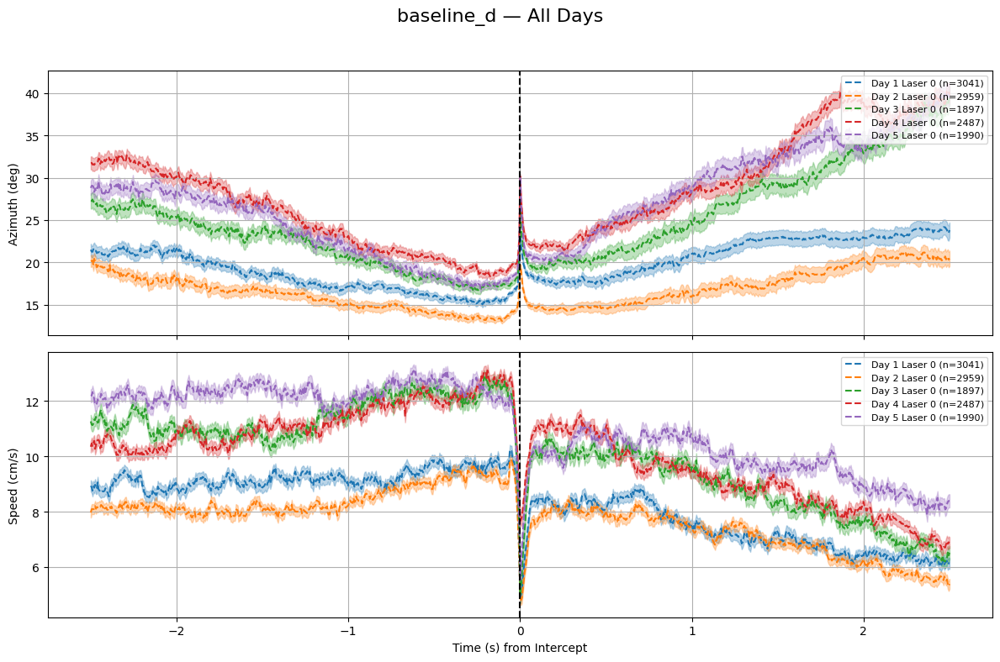

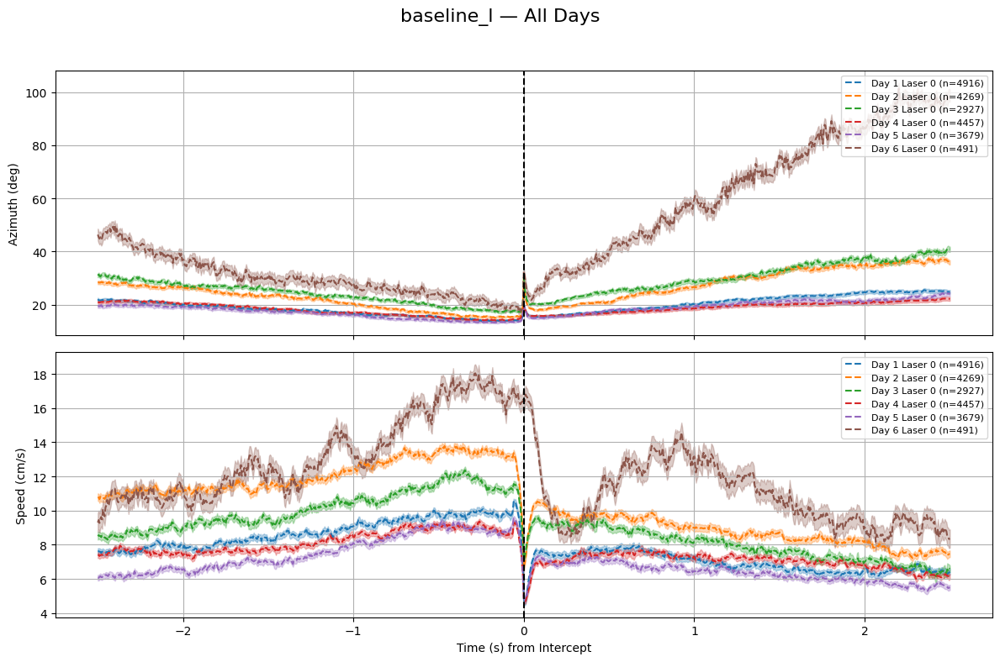

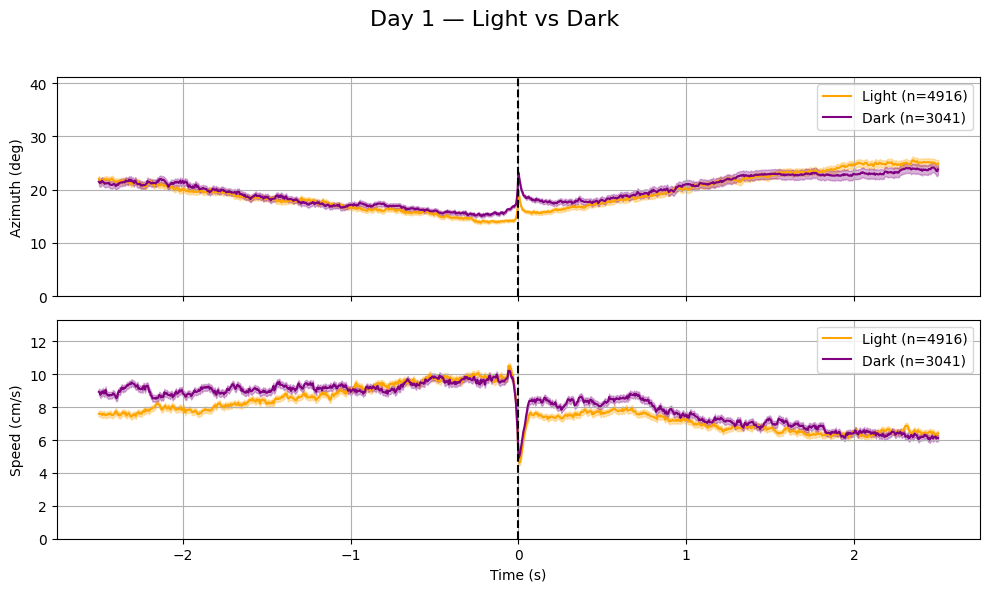

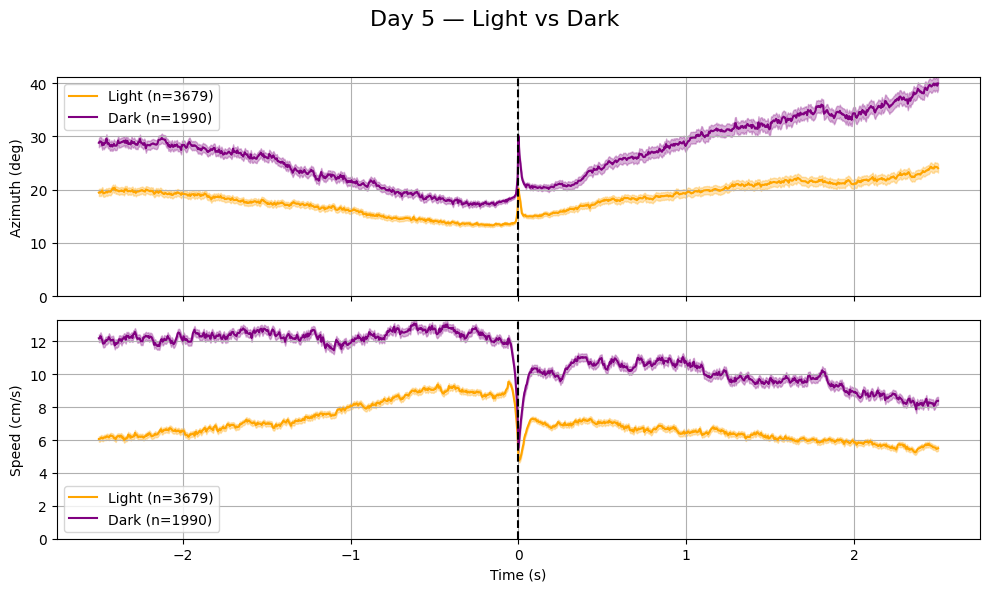

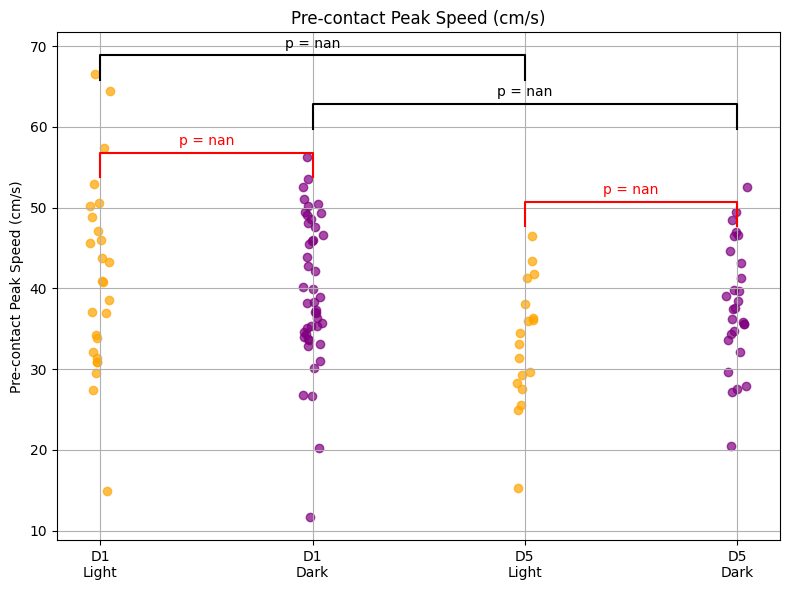

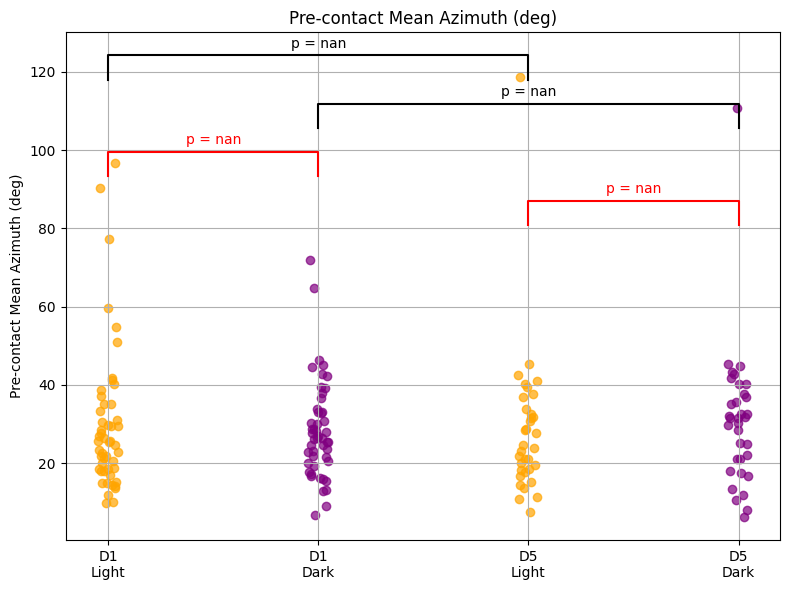

In [173]:
plot_pooled_all_days_median_with_stats(trial_df=baseline_trials,
                                           intercept_df=intercept_df,
                                           fr = 200,
                                           window_sec = 2.5)

In [174]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import re

def plot_capture_learning_curve_from_trial_df(trial_df: pd.DataFrame):
    """
    Plot learning curves of capture time (captureT) across days from trial_df.
    Points are trials; lines show median ± SEM.
    """

    df = trial_df.copy()

    # --- Extract mouse and date from filename ---
    def extract_mouse_and_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        if match:
            return pd.Series({'date': match.group(1), 'mouse': match.group(2)})
        return pd.Series({'date': None, 'mouse': None})

    df[['date', 'mouse']] = df['filename'].apply(extract_mouse_and_date)
    df['date'] = pd.to_datetime(df['date'])
    df = df.dropna(subset=['captureT', 'date', 'mouse', 'condition'])  # keep only usable trials

    # --- Assign day index per mouse per condition ---
    df['mouse'] = df['mouse'].astype(str)
    df['day_index'] = df.groupby(['mouse', 'condition'])['date'].rank(method='dense').astype(int)

    # --- Prep for plotting ---
    palette = {'baseline_l': 'orange', 'baseline_d': 'purple'}
    plt.figure(figsize=(10, 6))
    sns.set(style="whitegrid")

    # --- Scatter + Median ± SEM per condition ---
    for condition in df['condition'].unique():
        sub = df[df['condition'] == condition]
        jitter = (np.random.rand(len(sub)) - 0.5) * 0.3
        plt.scatter(sub['day_index'] + jitter, sub['captureT'],
                    alpha=0.6, label=f"{condition} trials",
                    color=palette.get(condition, 'gray'), edgecolor='k', linewidth=0.5)

        grouped = sub.groupby('day_index')['captureT']
        medians = grouped.median()
        sems = grouped.std(ddof=1) / np.sqrt(grouped.count())

        plt.errorbar(medians.index, medians.values, yerr=sems.values,
                     fmt='-o', label=f"{condition} median ± SEM",
                     color=palette.get(condition, 'gray'))

    plt.title("Capture Time Learning Curve")
    plt.xlabel("Day Index")
    plt.ylabel("Capture Time (s)")
    plt.legend()
    plt.tight_layout()
    plt.show()


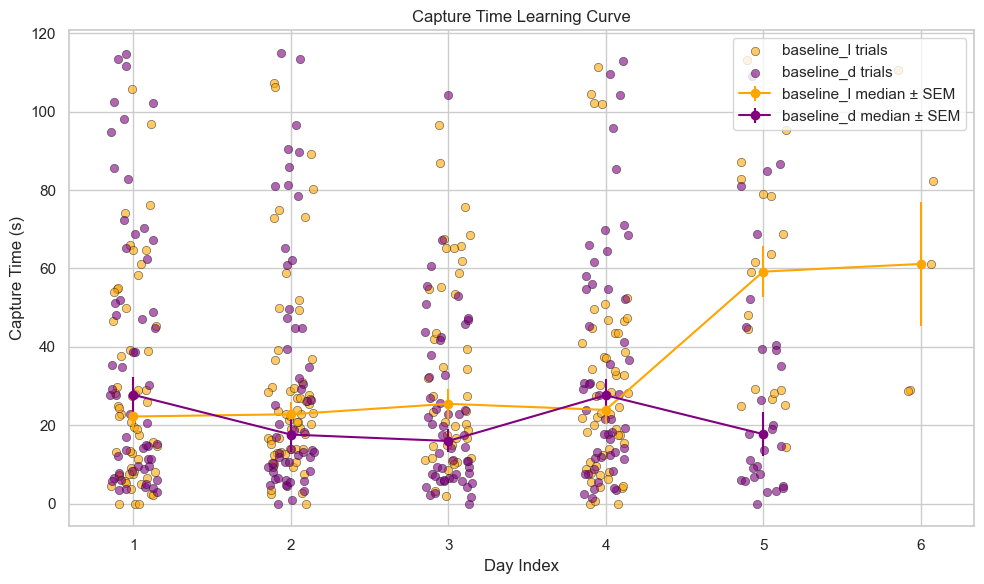

In [175]:
plot_capture_learning_curve_from_trial_df(baseline_trials)

In [194]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import re

def plot_capture_learning_curve_by_condition(trial_df: pd.DataFrame):
    """
    Plot learning curves of capture time across days in separate plots for light and dark conditions,
    dropping day 6 from light condition and showing mouse/trial counts in a legend box.
    """
    df = trial_df.copy()

    def extract_mouse_and_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        if match:
            return pd.Series({'date': match.group(1), 'mouse': match.group(2)})
        return pd.Series({'date': None, 'mouse': None})

    df[['date', 'mouse']] = df['filename'].apply(extract_mouse_and_date)
    df['date'] = pd.to_datetime(df['date'])
    df = df.dropna(subset=['captureT', 'date', 'mouse', 'condition'])
    df['mouse'] = df['mouse'].astype(str)
    df['day_index'] = df.groupby(['mouse', 'condition'])['date'].rank(method='dense').astype(int)

    palette = {'baseline_l': 'orange', 'baseline_d': 'purple'}
    sns.set(style="whitegrid")

    for condition in ['baseline_l', 'baseline_d']:
        sub = df[df['condition'] == condition]

        # Drop day 6 for light condition only
        if condition == 'baseline_l':
            sub = sub[sub['day_index'] != 6]

        if sub.empty:
            continue

        plt.figure(figsize=(10, 6))
        jitter = (np.random.rand(len(sub)) - 0.5) * 0.3
        plt.scatter(sub['day_index'] + jitter, sub['captureT'],
                    alpha=0.6, label="Trials", color=palette[condition],
                    edgecolor='k', linewidth=0.5)

        grouped = sub.groupby('day_index')['captureT']
        medians = grouped.median()
        sems = grouped.std(ddof=1) / np.sqrt(grouped.count())

        plt.errorbar(medians.index, medians.values, yerr=sems.values,
                     fmt='-o', color='k', ecolor='gray',
                     capsize=5, label="Median ± SEM")

        # Mouse and trial counts per day
        mouse_counts = sub.groupby('day_index')['mouse'].nunique()
        trial_counts = sub.groupby('day_index')['captureT'].count()

        # Create legend-like text box with mouse and trial counts per day
        legend_text = "Day  |  Mice  |  Trials\n"
        legend_text += "\n".join(f"{day:<4} | {mice:<5} | {trials:<6}"
                                 for day, mice, trials in zip(mouse_counts.index, mouse_counts, trial_counts))

        plt.gca().text(1.02, 0.5, legend_text, transform=plt.gca().transAxes,
                       fontsize=10, verticalalignment='center',
                       bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray'))

        plt.title(f"Capture Time Learning Curve — {'Light' if condition == 'baseline_l' else 'Dark'}")
        plt.xlabel("Day Index")
        plt.ylabel("Capture Time (s)")
        plt.xticks(medians.index)
        plt.grid(True, axis='y')
        plt.legend()
        plt.tight_layout(rect=[0, 0, 0.85, 1])  # leave room for legend box on the right
        plt.show()


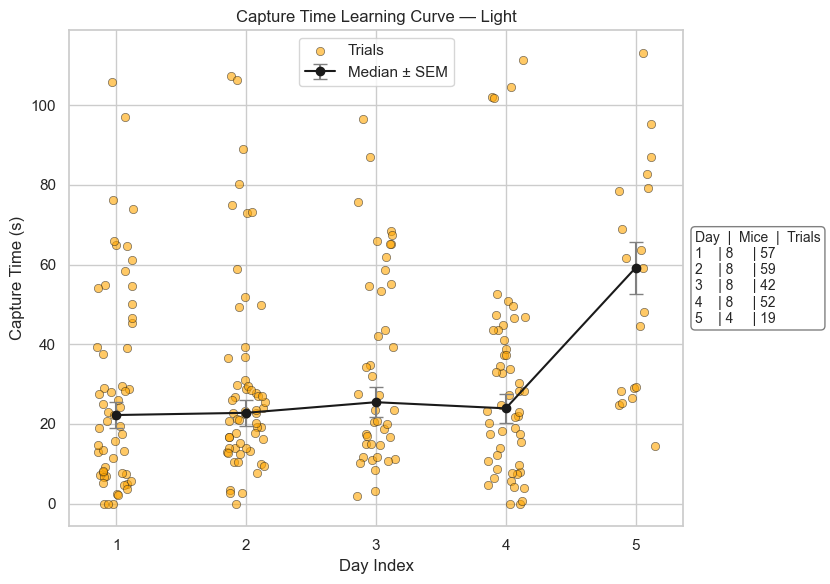

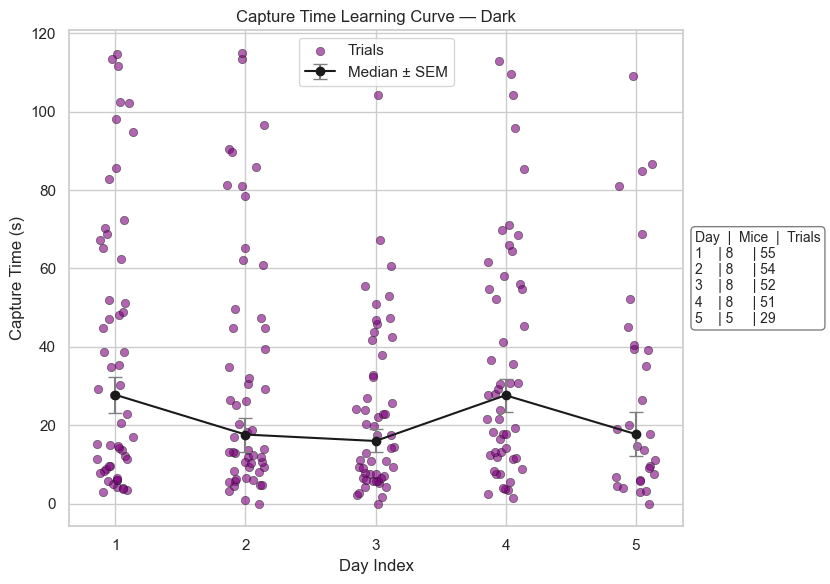

In [195]:
plot_capture_learning_curve_by_condition(baseline_trials)

In [200]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import re

def plot_capture_learning_curve_by_condition_mean(trial_df: pd.DataFrame):
    """
    Plot learning curves of capture time across days (using mean ± SEM),
    in separate plots for light and dark conditions. Removes day 6 from light.
    Displays mouse and trial n per day in legend.
    """
    df = trial_df.copy()

    # Extract date and mouse from filename
    def extract_mouse_and_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        if match:
            return pd.Series({'date': match.group(1), 'mouse': match.group(2)})
        return pd.Series({'date': None, 'mouse': None})

    df[['date', 'mouse']] = df['filename'].apply(extract_mouse_and_date)
    df['date'] = pd.to_datetime(df['date'])
    df = df.dropna(subset=['captureT', 'date', 'mouse', 'condition'])  # drop unusable rows
    df['mouse'] = df['mouse'].astype(str)
    df['day_index'] = df.groupby(['mouse', 'condition'])['date'].rank(method='dense').astype(int)

    palette = {'baseline_l': 'orange', 'baseline_d': 'purple'}
    sns.set(style="whitegrid")

    for condition in ['baseline_l', 'baseline_d']:
        sub = df[df['condition'] == condition].copy()

        if condition == 'baseline_l':
            sub = sub[sub['day_index'] <= 5]  # Remove day 6

        if sub.empty:
            continue

        plt.figure(figsize=(10, 6))

        # Scatter points (jittered) for each trial
        jitter = (np.random.rand(len(sub)) - 0.5) * 0.3
        plt.scatter(sub['day_index'] + jitter, sub['captureT'],
                    alpha=0.6, color=palette[condition],
                    edgecolor='k', linewidth=0.5, label="Trials")

        # Group stats
        grouped = sub.groupby('day_index')
        means = grouped['captureT'].mean()
        sems = grouped['captureT'].std(ddof=1) / np.sqrt(grouped['captureT'].count())

        # Count per day
        trial_counts = grouped['captureT'].count()
        mouse_counts = grouped['mouse'].nunique()

        # Plot error bars
        plt.errorbar(means.index, means.values, yerr=sems.values,
                     fmt='-o', color='k', ecolor='gray',
                     capsize=5, label="Mean ± SEM")

        # Custom legend with counts
        legend_entries = [f"Day {d}: n={trial_counts[d]}, mice={mouse_counts[d]}"
                          for d in means.index]
        legend_text = '\n'.join(legend_entries)

        plt.title(f"Capture Time Learning Curve — {'Light' if condition == 'baseline_l' else 'Dark'}")
        plt.xlabel("Day Index")
        plt.ylabel("Capture Time (s)")
        plt.grid(True, axis='y')
        plt.legend(title=legend_text, loc='upper right', fontsize=9)
        plt.tight_layout()
        plt.show()


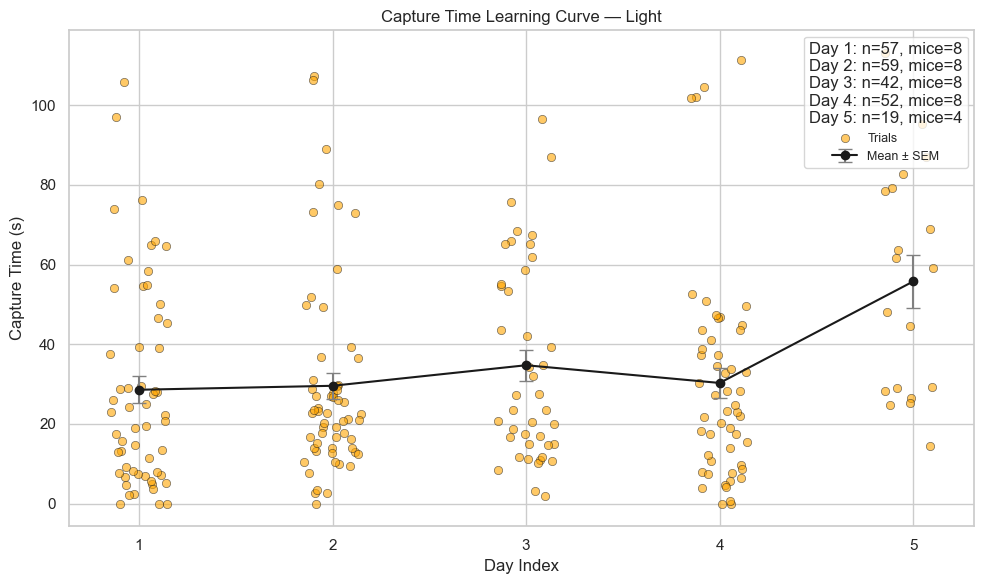

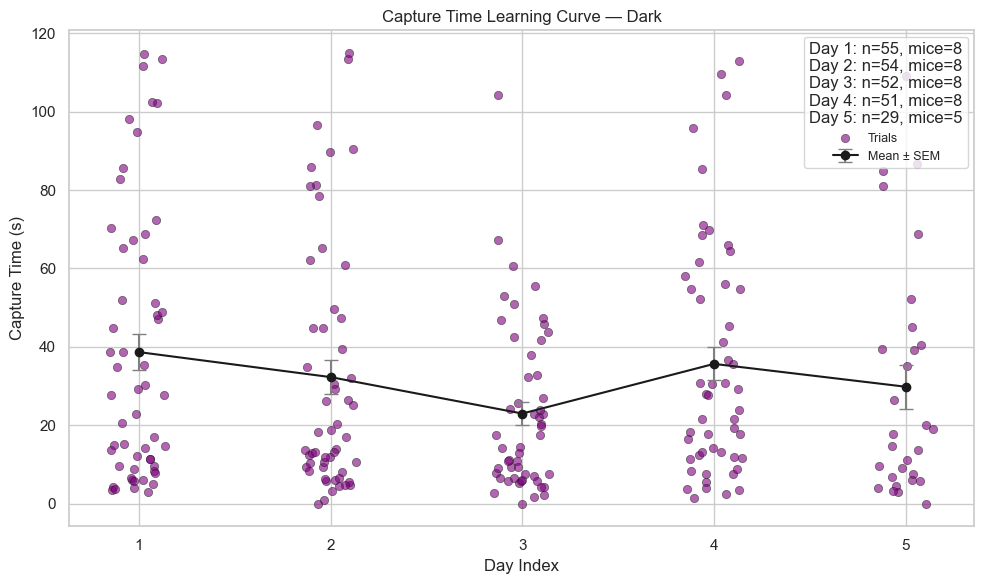

In [201]:
plot_capture_learning_curve_by_condition_mean(baseline_trials)

In [202]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import re
import os

def extract_mouse_and_date(filename):
    match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
    if match:
        return pd.Series({'date': match.group(1), 'mouse': match.group(2)})
    return pd.Series({'date': None, 'mouse': None})

def plot_capture_learning_curves_side_by_side(trial_df: pd.DataFrame, save_dir: str = "./figures"):
    """
    Plot side-by-side learning curves of capture time (medians and means) for light and dark conditions.
    Saves output as .pdf.
    """
    os.makedirs(save_dir, exist_ok=True)

    df = trial_df.copy()
    df[['date', 'mouse']] = df['filename'].apply(extract_mouse_and_date)
    df['date'] = pd.to_datetime(df['date'])
    df = df.dropna(subset=['captureT', 'date', 'mouse', 'condition'])
    df['mouse'] = df['mouse'].astype(str)
    df['day_index'] = df.groupby(['mouse', 'condition'])['date'].rank(method='dense').astype(int)

    palette = {'baseline_l': 'orange', 'baseline_d': 'purple'}
    sns.set(style="whitegrid")

    for stat in ['median', 'mean']:
        fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
        fig.suptitle(f"Capture Time Learning Curve ({stat.title()} ± SEM)", fontsize=16)

        for ax, condition in zip(axes, ['baseline_l', 'baseline_d']):
            sub = df[df['condition'] == condition]

            # Drop day 6 for light condition
            if condition == 'baseline_l':
                sub = sub[sub['day_index'] <= 5]

            if sub.empty:
                continue

            jitter = (np.random.rand(len(sub)) - 0.5) * 0.3
            ax.scatter(sub['day_index'] + jitter, sub['captureT'],
                       alpha=0.6, label="Trials", color=palette[condition],
                       edgecolor='k', linewidth=0.5)

            grouped = sub.groupby('day_index')['captureT']
            if stat == 'median':
                y_vals = grouped.median()
            else:
                y_vals = grouped.mean()
            sems = grouped.std(ddof=1) / np.sqrt(grouped.count())

            # Count mice and trials per day for legend
            trial_counts = grouped.count()
            mouse_counts = sub.groupby('day_index')['mouse'].nunique()

            ax.errorbar(y_vals.index, y_vals.values, yerr=sems.values,
                        fmt='-o', color='k', ecolor='gray', capsize=5,
                        label="± SEM")

            legend_labels = [
                f"Day {day}: {trial_counts[day]} trials, {mouse_counts[day]} mice"
                for day in y_vals.index
            ]

            ax.set_title("Light" if condition == 'baseline_l' else "Dark")
            ax.set_xlabel("Day Index")
            ax.set_ylabel("Capture Time (s)")
            ax.set_xticks(sorted(y_vals.index))
            ax.set_ylim(bottom=0)
            ax.grid(True, axis='y')

            # Custom legend with counts
            handles, _ = ax.get_legend_handles_labels()
            handles.append(plt.Line2D([], [], color='w', label="\n".join(legend_labels)))
            ax.legend(handles=handles, loc='upper right', fontsize=9)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        filename = os.path.join(save_dir, f"capture_learning_curve_{stat}.pdf")
        plt.savefig(filename, format='pdf')
        plt.show()


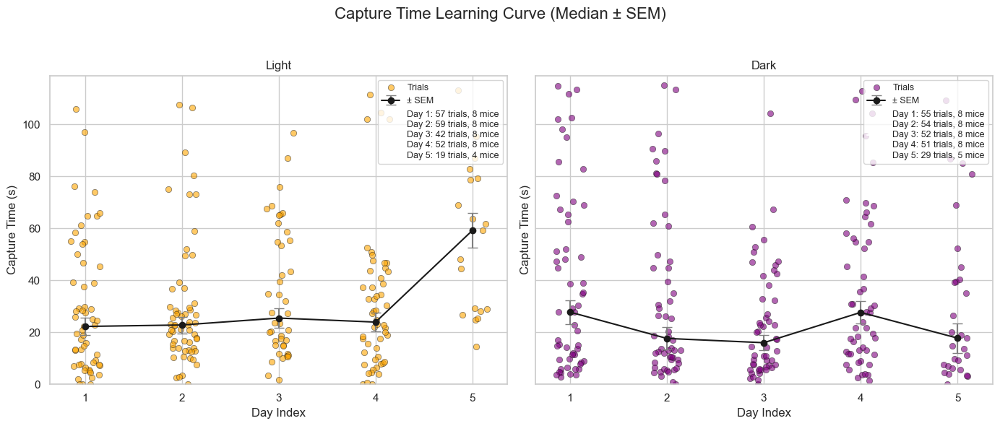

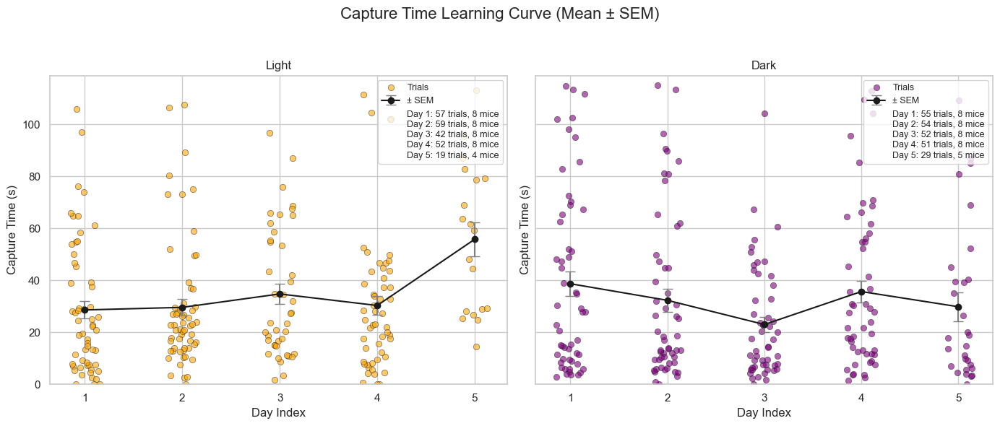

In [203]:
plot_capture_learning_curves_side_by_side(baseline_trials, save_dir="/Users/mollyshallow/Desktop/WehrLab/PlotsForJen")


In [210]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import re
import os

def plot_capture_learning_curves_median_and_mean(
    trial_df: pd.DataFrame,
    save_dir: str = None
):
    """
    Plot side-by-side learning curves of capture time (median and mean per mouse per day),
    with separate lines/dots for light and dark conditions.
    Mouse and trial n per day shown inside legend text box.
    Optionally saves the figure as PDF if save_dir is provided.
    """

    df = trial_df.copy()

    # Extract mouse and date from filename
    def extract_mouse_and_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        if match:
            return pd.Series({'date': match.group(1), 'mouse': match.group(2)})
        return pd.Series({'date': None, 'mouse': None})

    df[['date', 'mouse']] = df['filename'].apply(extract_mouse_and_date)
    df['date'] = pd.to_datetime(df['date'])
    df = df.dropna(subset=['captureT', 'date', 'mouse', 'condition'])
    df['mouse'] = df['mouse'].astype(str)
    df['day_index'] = df.groupby(['mouse', 'condition'])['date'].rank(method='dense').astype(int)

    # Drop day 6 from baseline_l (light) condition if exists
    df = df[~((df['condition'] == 'baseline_l') & (df['day_index'] > 5))]
    df = df[df['day_index'] <= 5]  # keep max 5 days overall

    palette = {'baseline_l': 'orange', 'baseline_d': 'purple'}
    sns.set(style="whitegrid")

    fig, axs = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    fig.suptitle("Capture Time Learning Curves: Median (Left) & Mean (Right) per Mouse", fontsize=18)

    # For storing legend text info (mouse and trial counts)
    def get_counts_text(sub, mouse_day_vals):
        lines = []
        for day in sorted(sub['day_index'].unique()):
            mouse_n = mouse_day_vals[day]['mouse_n']
            trial_n = mouse_day_vals[day]['trial_n']
            lines.append(f"Day {day}: {mouse_n} mice, {trial_n} trials")
        return "\n".join(lines)

    # Plot Median per mouse
    ax = axs[0]
    for cond in ['baseline_l', 'baseline_d']:
        sub = df[df['condition'] == cond]

        if sub.empty:
            continue

        # Compute median per mouse per day
        mouse_day_medians = sub.groupby(['mouse', 'day_index'])['captureT'].median().reset_index()

        # Plot points jittered
        jitter = (np.random.rand(len(mouse_day_medians)) - 0.5) * 0.3
        ax.scatter(mouse_day_medians['day_index'] + jitter,
                   mouse_day_medians['captureT'],
                   alpha=0.7, color=palette[cond], edgecolor='k', label=f"{cond} mouse medians")

        # Group stats (mean and sem of medians across mice)
        summary = mouse_day_medians.groupby('day_index')['captureT']
        means = summary.mean()
        sems = summary.std(ddof=1) / np.sqrt(summary.count())

        ax.errorbar(means.index, means.values, yerr=sems.values,
                    fmt='-o', color=palette[cond], capsize=5,
                    label=f"{cond} group mean±SEM")

        # Prepare counts text
        mouse_day_vals = {}
        for day in means.index:
            mouse_n = mouse_day_medians[mouse_day_medians['day_index'] == day]['mouse'].nunique()
            trial_n = sub[sub['day_index'] == day].shape[0]
            mouse_day_vals[day] = {'mouse_n': mouse_n, 'trial_n': trial_n}

        # Add counts text box near legend
        counts_text = get_counts_text(sub, mouse_day_vals)
        # Position box on the right side for light and left side for dark to avoid overlap
        xpos = 1.05 if cond == 'baseline_l' else -0.25
        ypos = 0.5 if cond == 'baseline_l' else 0.1
        ax.text(xpos, ypos, counts_text, transform=ax.transAxes,
                fontsize=9, verticalalignment='center',
                bbox=dict(boxstyle='round,pad=0.4', facecolor=palette[cond], alpha=0.15),
                clip_on=False)

    ax.set_title("Median per Mouse")
    ax.set_xlabel("Day")
    ax.set_ylabel("Capture Time (s)")
    ax.grid(True)
    ax.legend(loc='upper left', fontsize=9)

    # Plot Mean per mouse
    ax = axs[1]
    for cond in ['baseline_l', 'baseline_d']:
        sub = df[df['condition'] == cond]

        if sub.empty:
            continue

        # Compute mean per mouse per day
        mouse_day_means = sub.groupby(['mouse', 'day_index'])['captureT'].mean().reset_index()

        jitter = (np.random.rand(len(mouse_day_means)) - 0.5) * 0.3
        ax.scatter(mouse_day_means['day_index'] + jitter,
                   mouse_day_means['captureT'],
                   alpha=0.7, color=palette[cond], edgecolor='k', label=f"{cond} mouse means")

        summary = mouse_day_means.groupby('day_index')['captureT']
        means = summary.mean()
        sems = summary.std(ddof=1) / np.sqrt(summary.count())

        ax.errorbar(means.index, means.values, yerr=sems.values,
                    fmt='-o', color=palette[cond], capsize=5,
                    label=f"{cond} group mean±SEM")

        mouse_day_vals = {}
        for day in means.index:
            mouse_n = mouse_day_means[mouse_day_means['day_index'] == day]['mouse'].nunique()
            trial_n = sub[sub['day_index'] == day].shape[0]
            mouse_day_vals[day] = {'mouse_n': mouse_n, 'trial_n': trial_n}

        counts_text = get_counts_text(sub, mouse_day_vals)
        xpos = 1.05 if cond == 'baseline_l' else -0.25
        ypos = 0.5 if cond == 'baseline_l' else 0.1
        ax.text(xpos, ypos, counts_text, transform=ax.transAxes,
                fontsize=9, verticalalignment='center',
                bbox=dict(boxstyle='round,pad=0.4', facecolor=palette[cond], alpha=0.15),
                clip_on=False)

    ax.set_title("Mean per Mouse")
    ax.set_xlabel("Day")
    ax.grid(True)
    ax.legend(loc='upper left', fontsize=9)

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
        save_path = os.path.join(save_dir, "capture_learning_curves_median_mean.pdf")
        plt.savefig(save_path, format='pdf')
        print(f"Figure saved to {save_path}")

    plt.show()


Figure saved to /Users/mollyshallow/Desktop/WehrLab/PlotsForJen/capture_learning_curves_median_mean.pdf


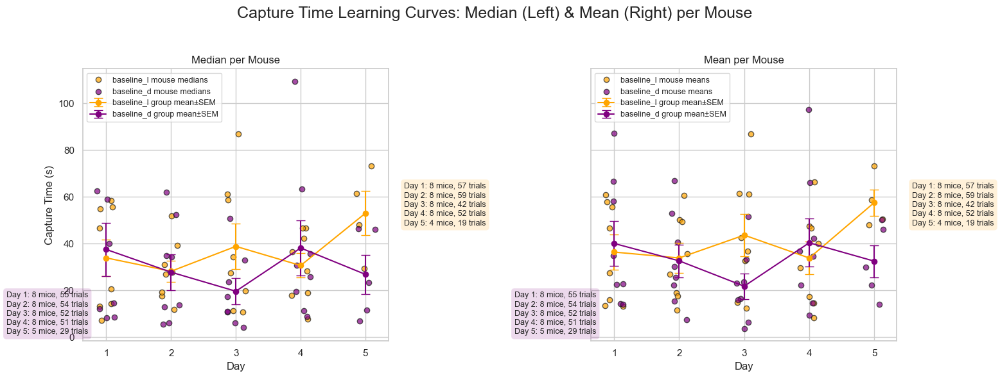

In [211]:
# plot_capture_learning_curve_median_by_mouse(baseline_trials, save_dir="/Users/mollyshallow/Desktop/WehrLab/PlotsForJen")

plot_capture_learning_curves_median_and_mean(trial_df=baseline_trials, save_dir="/Users/mollyshallow/Desktop/WehrLab/PlotsForJen")




In [215]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import re
import os

def plot_capture_learning_curves_separate(
    trial_df: pd.DataFrame,
    save_dir: str = None
):
    """
    Plot capture time learning curves as two separate figures:
    - Figure 1: Median per mouse (2 horizontal subplots: light left, dark right)
    - Figure 2: Mean per mouse (2 horizontal subplots: light left, dark right)
    Mouse and trial counts per day displayed in text boxes in each subplot.
    Saves PDFs if save_dir provided.
    """

    df = trial_df.copy()

    # Extract mouse and date from filename
    def extract_mouse_and_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        if match:
            return pd.Series({'date': match.group(1), 'mouse': match.group(2)})
        return pd.Series({'date': None, 'mouse': None})

    df[['date', 'mouse']] = df['filename'].apply(extract_mouse_and_date)
    df['date'] = pd.to_datetime(df['date'])
    df = df.dropna(subset=['captureT', 'date', 'mouse', 'condition'])
    df['mouse'] = df['mouse'].astype(str)
    df['day_index'] = df.groupby(['mouse', 'condition'])['date'].rank(method='dense').astype(int)

    # Drop day 6+ from baseline_l (light)
    df = df[~((df['condition'] == 'baseline_l') & (df['day_index'] > 5))]
    df = df[df['day_index'] <= 5]

    palette = {'baseline_l': 'orange', 'baseline_d': 'purple'}
    sns.set(style="whitegrid")

    def plot_metric_figure(stat='median'):
        fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
        fig.suptitle(f"Capture Time Learning Curve ({stat.title()}) per Mouse", fontsize=16)

        for ax, cond in zip(axes, ['baseline_l', 'baseline_d']):
            sub = df[df['condition'] == cond]
            if sub.empty:
                ax.set_visible(False)
                continue

            # Per mouse, per day stat (median or mean)
            if stat == 'median':
                mouse_day_stat = sub.groupby(['mouse', 'day_index'])['captureT'].median().reset_index()
            else:
                mouse_day_stat = sub.groupby(['mouse', 'day_index'])['captureT'].mean().reset_index()

            # Scatter dots jittered on x-axis
            jitter = (np.random.rand(len(mouse_day_stat)) - 0.5) * 0.3
            ax.scatter(mouse_day_stat['day_index'] + jitter,
                       mouse_day_stat['captureT'],
                       alpha=0.7, color=palette[cond], edgecolor='k',
                       label=f"{cond} mouse {stat}s")

            # Group mean ± SEM of the per-mouse stats for each day
            summary = mouse_day_stat.groupby('day_index')['captureT']
            means = summary.mean()
            sems = summary.std(ddof=1) / np.sqrt(summary.count())

            ax.errorbar(means.index, means.values, yerr=sems.values,
                        fmt='-o', color=palette[cond], capsize=5,
                        label=f"Group mean±SEM")

            # Mouse and trial counts per day
            mouse_day_vals = {}
            for day in means.index:
                mouse_n = mouse_day_stat[mouse_day_stat['day_index'] == day]['mouse'].nunique()
                trial_n = sub[sub['day_index'] == day].shape[0]
                mouse_day_vals[day] = {'mouse_n': mouse_n, 'trial_n': trial_n}

            # Build text box content
            text_lines = [f"Day {day}: {vals['mouse_n']} mice, {vals['trial_n']} trials"
                          for day, vals in sorted(mouse_day_vals.items())]
            text = "\n".join(text_lines)

            # Place text box in upper right corner of subplot
            ax.text(0.98, 0.95, text, transform=ax.transAxes,
                    fontsize=9, verticalalignment='top', horizontalalignment='right',
                    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8, edgecolor='gray'))

            ax.set_title(f"{'Light' if cond=='baseline_l' else 'Dark'}")
            ax.set_xlabel("Day Index")
            ax.set_xlim(0.5, 5.5)
            ax.grid(True, axis='y')

            if ax == axes[0]:
                ax.set_ylabel("Capture Time (s)")

        plt.tight_layout(rect=[0, 0, 1, 0.95])

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            filename = os.path.join(save_dir, f"capture_learning_curve_{stat}.pdf")
            plt.savefig(filename)
            print(f"Saved plot: {filename}")

        plt.show()

    # Plot median and mean figures separately
    plot_metric_figure(stat='median')
    plot_metric_figure(stat='mean')


Saved plot: /Users/mollyshallow/Desktop/WehrLab/PlotsForJen/capture_learning_curve_median.pdf


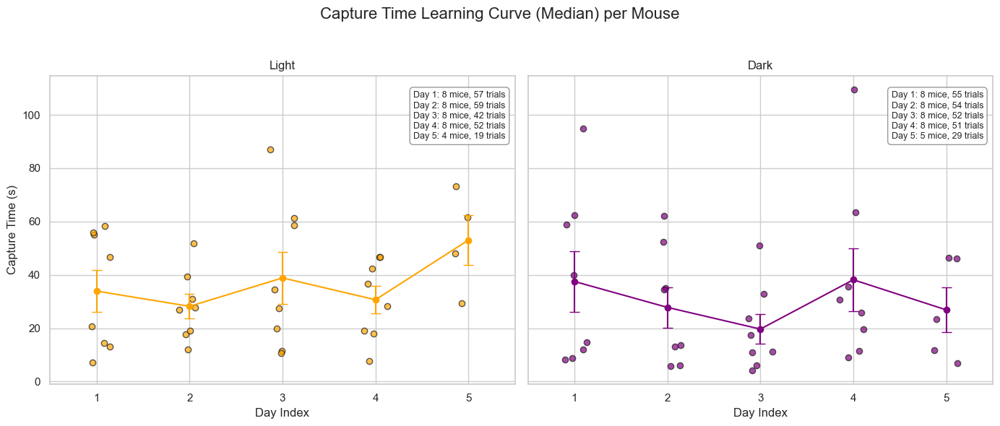

Saved plot: /Users/mollyshallow/Desktop/WehrLab/PlotsForJen/capture_learning_curve_mean.pdf


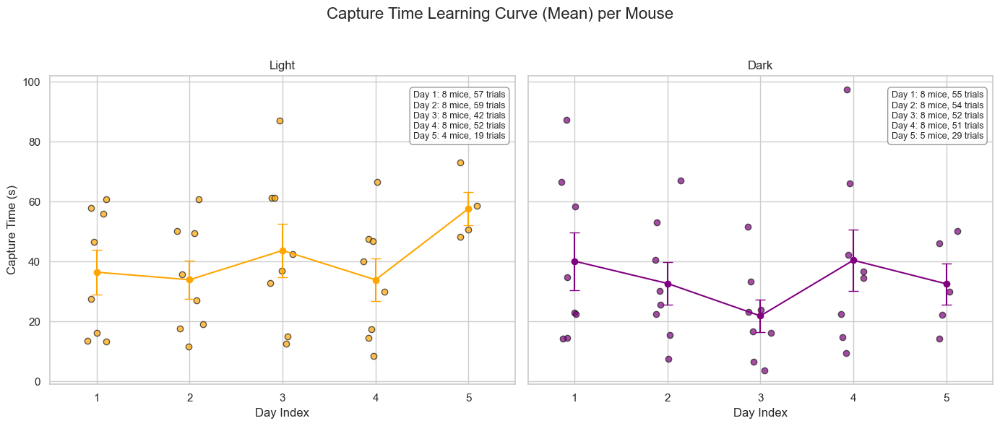

In [216]:
plot_capture_learning_curves_separate(trial_df=baseline_trials, save_dir="/Users/mollyshallow/Desktop/WehrLab/PlotsForJen")


In [217]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import re
import os

def plot_capture_learning_curves_separate_cleaned(
    trial_df: pd.DataFrame,
    save_dir: str = None
):
    """
    Plot capture time learning curves as two separate figures:
    - Figure 1: Median per mouse (2 horizontal subplots: light left, dark right)
    - Figure 2: Mean per mouse (2 horizontal subplots: light left, dark right)
    Mouse and trial counts per day displayed in text boxes in each subplot.
    Saves PDFs if save_dir provided.
    """

    df = trial_df.copy()

    # Extract mouse and date from filename
    def extract_mouse_and_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        if match:
            return pd.Series({'date': match.group(1), 'mouse': match.group(2)})
        return pd.Series({'date': None, 'mouse': None})

    df[['date', 'mouse']] = df['filename'].apply(extract_mouse_and_date)
    df['date'] = pd.to_datetime(df['date'])
    df = df.dropna(subset=['captureT', 'date', 'mouse', 'condition'])
    df['mouse'] = df['mouse'].astype(str)

    # Drop mouse '1337'
    df = df[df['mouse'] != '1337']

    df['day_index'] = df.groupby(['mouse', 'condition'])['date'].rank(method='dense').astype(int)

    # Drop day 6+ from baseline_l (light)
    df = df[~((df['condition'] == 'baseline_l') & (df['day_index'] > 5))]
    df = df[df['day_index'] <= 5]

    palette = {'baseline_l': 'orange', 'baseline_d': 'purple'}
    sns.set(style="whitegrid")

    def plot_metric_figure(stat='median'):
        fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
        fig.suptitle(f"Capture Time Learning Curve ({stat.title()}) per Mouse", fontsize=16)

        for ax, cond in zip(axes, ['baseline_l', 'baseline_d']):
            sub = df[df['condition'] == cond]
            if sub.empty:
                ax.set_visible(False)
                continue

            # Per mouse, per day stat (median or mean)
            if stat == 'median':
                mouse_day_stat = sub.groupby(['mouse', 'day_index'])['captureT'].median().reset_index()
            else:
                mouse_day_stat = sub.groupby(['mouse', 'day_index'])['captureT'].mean().reset_index()

            # Scatter dots jittered on x-axis
            jitter = (np.random.rand(len(mouse_day_stat)) - 0.5) * 0.3
            ax.scatter(mouse_day_stat['day_index'] + jitter,
                       mouse_day_stat['captureT'],
                       alpha=0.7, color=palette[cond], edgecolor='k',
                       label=f"{cond} mouse {stat}s")

            # Group mean ± SEM of the per-mouse stats for each day
            summary = mouse_day_stat.groupby('day_index')['captureT']
            means = summary.mean()
            sems = summary.std(ddof=1) / np.sqrt(summary.count())

            ax.errorbar(means.index, means.values, yerr=sems.values,
                        fmt='-o', color=palette[cond], capsize=5,
                        label=f"Group mean±SEM")

            # Mouse and trial counts per day
            mouse_day_vals = {}
            for day in means.index:
                mouse_n = mouse_day_stat[mouse_day_stat['day_index'] == day]['mouse'].nunique()
                trial_n = sub[sub['day_index'] == day].shape[0]
                mouse_day_vals[day] = {'mouse_n': mouse_n, 'trial_n': trial_n}

            # Build text box content
            text_lines = [f"Day {day}: {vals['mouse_n']} mice, {vals['trial_n']} trials"
                          for day, vals in sorted(mouse_day_vals.items())]
            text = "\n".join(text_lines)

            # Place text box in upper right corner of subplot
            ax.text(0.98, 0.95, text, transform=ax.transAxes,
                    fontsize=9, verticalalignment='top', horizontalalignment='right',
                    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8, edgecolor='gray'))

            ax.set_title(f"{'Light' if cond=='baseline_l' else 'Dark'}")
            ax.set_xlabel("Day Index")
            ax.set_xlim(0.5, 5.5)
            ax.grid(True, axis='y')

            if ax == axes[0]:
                ax.set_ylabel("Capture Time (s)")

        plt.tight_layout(rect=[0, 0, 1, 0.95])

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            filename = os.path.join(save_dir, f"capture_learning_curve_{stat}_no_1337.pdf")
            plt.savefig(filename)
            print(f"Saved plot: {filename}")

        plt.show()

    # Plot median and mean figures separately
    plot_metric_figure(stat='median')
    plot_metric_figure(stat='mean')


Saved plot: /Users/mollyshallow/Desktop/WehrLab/PlotsForJen/capture_learning_curve_median_no_1337.pdf


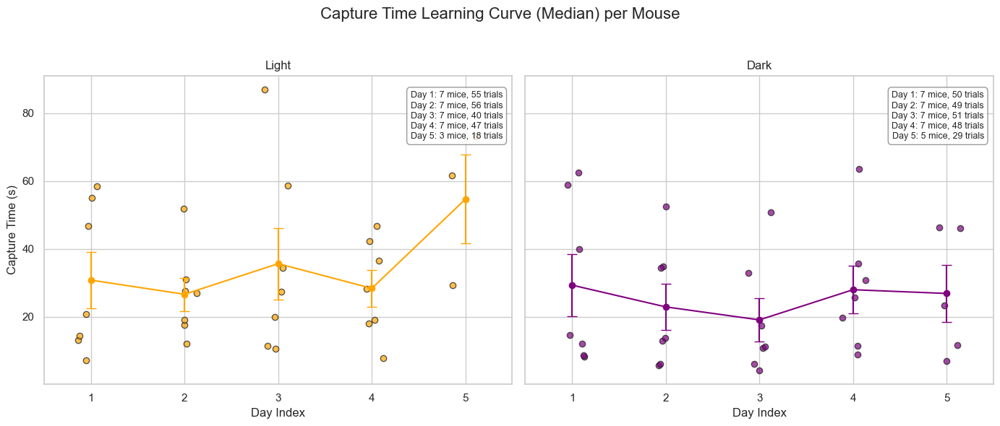

Saved plot: /Users/mollyshallow/Desktop/WehrLab/PlotsForJen/capture_learning_curve_mean_no_1337.pdf


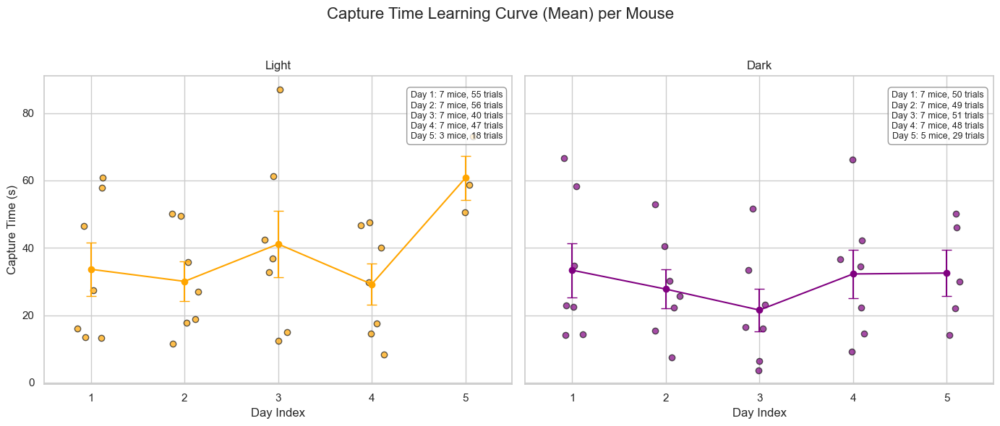

In [218]:
plot_capture_learning_curves_separate_cleaned(trial_df=baseline_trials, save_dir="/Users/mollyshallow/Desktop/WehrLab/PlotsForJen")

In [421]:
import pandas as pd

# Read the three CSV files into separate DataFrames
df1 = pd.read_csv('/Users/mollyshallow/Desktop/WehrLab/learning_curves_expert_transgenic.csv', skiprows=1)
df2 = pd.read_csv('/Users/mollyshallow/Desktop/WehrLab/learning_curves_expert_viral.csv', skiprows=1)
df3 = pd.read_csv('/Users/mollyshallow/Desktop/WehrLab/learning_curves_gad2.csv', skiprows=1)
df4 = pd.read_csv('/Users/mollyshallow/Desktop/WehrLab/learning_curves_novice_transgenic.csv', skiprows=1)

# Add a new column to each DataFrame to mark its origin
df1['source'] = 'transgenic-vgat'
df2['source'] = 'viral-vgat'
df3['source'] = 'gad2'
df4['source'] = 'novice-transgenic-vgat'

# Combine all three DataFrames into one
combined_df = pd.concat([df1, df2, df3, df4], ignore_index=True)

# Now combined_df contains all data, with a 'source' column indicating origin
print(combined_df.head())


   mouse_number  day condition  catch  no_catch  total_trials  catch_rate sex   
0           894    1     light   10.0       0.0          10.0         1.0   m  \
1           894    2     light   10.0       0.0          10.0         1.0   m   
2           894    3     light    7.0       0.0           7.0         1.0   m   
3           894    4     light    7.0       0.0           7.0         1.0   m   
4           894    5     light    NaN       NaN           NaN         NaN   m   

            source  laser_catch  no_laser_catch  Unnamed: 9  
0  transgenic-vgat          NaN             NaN         NaN  
1  transgenic-vgat          NaN             NaN         NaN  
2  transgenic-vgat          NaN             NaN         NaN  
3  transgenic-vgat          NaN             NaN         NaN  
4  transgenic-vgat          NaN             NaN         NaN  


In [422]:
combined_df

,mouse_number,day,condition,catch,no_catch,total_trials,catch_rate,sex,source,laser_catch,no_laser_catch,Unnamed: 9
0,894,1,light,10.0,0.0,10.0,1.0,m,transgenic-vgat,NaN,NaN,NaN
1,894,2,light,10.0,0.0,10.0,1.0,m,transgenic-vgat,NaN,NaN,NaN
2,894,3,light,7.0,0.0,7.0,1.0,m,transgenic-vgat,NaN,NaN,NaN
3,894,4,light,7.0,0.0,7.0,1.0,m,transgenic-vgat,NaN,NaN,NaN
4,894,5,light,NaN,NaN,NaN,NaN,m,transgenic-vgat,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
300,3841,1,dark,9.0,1.0,10.0,0.9,m,novice-transgenic-vgat,4.0,5.0,NaN
301,3841,2,dark,8.0,2.0,10.0,0.8,m,novice-transgenic-vgat,4.0,4.0,NaN
302,3841,3,dark,9.0,1.0,10.0,0.9,m,novice-transgenic-vgat,5.0,4.0,NaN
303,3841,4,dark,8.0,2.0,10.0,0.8,m,novice-transgenic-vgat,4.0,4.0,NaN


In [423]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def plot_catch_rate_with_counts_table(combined_df, condition):
    df_cond = combined_df[combined_df['condition'] == condition].dropna(subset=['catch_rate'])

    fig, ax = plt.subplots(figsize=(14, 8))

    # Prepare a DataFrame to hold counts for the table
    table_data = []

    for source, group in df_cond.groupby('source'):
        # Average catch rate per day
        daily_avg = group.groupby('day')['catch_rate'].mean()

        # SEM of catch rate per day
        daily_sem = group.groupby('day')['catch_rate'].sem()

        # Number of unique mice per day
        daily_mice = group.groupby('day')['mouse_number'].nunique()

        # Total trials per day
        daily_trials = group.groupby('day')['total_trials'].sum()

        days = daily_avg.index
        values = daily_avg.values
        sem_values = daily_sem.values

        # Plot with error bars
        ax.errorbar(days, values, yerr=sem_values, marker='o', capsize=5, label=source)

        # Prepare table rows for this source
        for day in days:
            table_data.append({
                'Day': day,
                'Source': source,
                'Mice': daily_mice.loc[day],
                'Trials': int(daily_trials.loc[day])
            })

    ax.set_title(f"Average Catch Rate Over Days — {condition.capitalize()}")
    ax.set_xlabel("Day")
    ax.set_ylabel("Average Catch Rate")
    ax.grid(True)
    ax.legend(title="Source")

    # Create DataFrame for table
    table_df = pd.DataFrame(table_data)
    table_df = table_df.pivot(index='Day', columns='Source', values=['Mice', 'Trials'])

    # Format the table data into strings (mice and trials stacked)
    cell_text = []
    for day in table_df.index:
        row = []
        for source in table_df.columns.levels[1]:
            try:
                mice = int(table_df.loc[day, ('Mice', source)])
                trials = int(table_df.loc[day, ('Trials', source)])
                row.append(f"M: {mice}\nT: {trials}")
            except KeyError:
                row.append("M: 0\nT: 0")
        cell_text.append(row)

    # Column labels (sources)
    col_labels = table_df.columns.levels[1].tolist()

    # Add table to the right of the plot with bigger font
    table = plt.table(cellText=cell_text,
                      rowLabels=table_df.index,
                      colLabels=col_labels,
                      cellLoc='center',
                      rowLoc='center',
                      loc='right',
                      bbox=[1.05, 0.1, 0.3, 0.8])
    table.auto_set_font_size(False)
    table.set_fontsize(7.5)

    plt.subplots_adjust(right=0.7)
    plt.show()


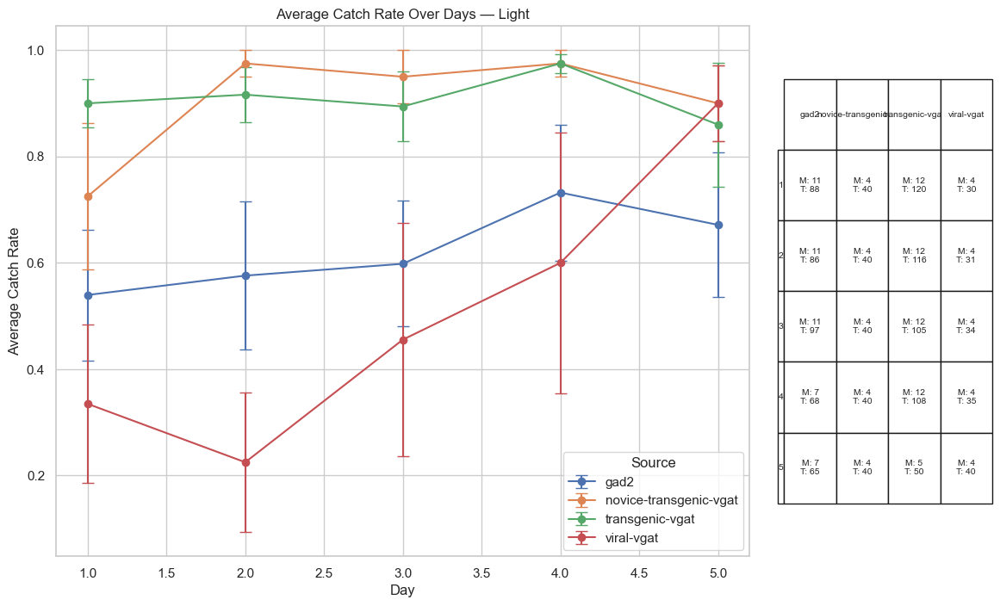

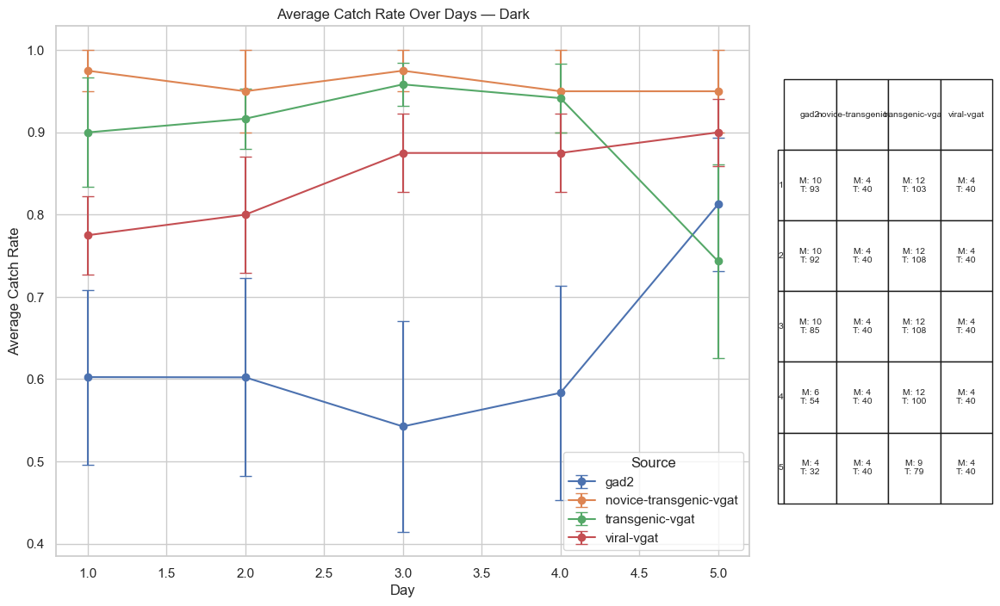

In [424]:
plot_catch_rate_with_counts_table(combined_df, 'light')
plot_catch_rate_with_counts_table(combined_df, 'dark')

In [425]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.gridspec import GridSpec

def plot_catch_rate_with_counts_table(combined_df, condition, save_path=None):
    df_cond = combined_df[(combined_df['condition'] == condition)].dropna(subset=['catch_rate'])

    fig = plt.figure(figsize=(14, 10))
    gs = GridSpec(2, 1, height_ratios=[3, 1], figure=fig)

    ax = fig.add_subplot(gs[0])
    ax_table = fig.add_subplot(gs[1])
    ax_table.axis('off')

    table_data = []

    # Assign unique color per source using a colormap
    sources = df_cond['source'].unique()
    colors = plt.cm.get_cmap('tab10', len(sources))
    source_colors = {source: colors(i) for i, source in enumerate(sources)}

    for source in sources:
        group = df_cond[df_cond['source'] == source]
        color = source_colors[source]

        # Plot individual mouse daily means
        mouse_day_means = group.groupby(['mouse_number', 'day'])['catch_rate'].mean().reset_index()
        for mouse in mouse_day_means['mouse_number'].unique():
            mouse_data = mouse_day_means[mouse_day_means['mouse_number'] == mouse]
            ax.scatter(mouse_data['day'], mouse_data['catch_rate'], alpha=0.4, s=30, label=None, color=color)

        # Group mean and SEM
        daily_avg = group.groupby('day')['catch_rate'].mean()
        daily_sem = group.groupby('day')['catch_rate'].sem()
        daily_mice = group.groupby('day')['mouse_number'].nunique()
        daily_trials = group.groupby('day')['total_trials'].sum()

        days = daily_avg.index
        values = daily_avg.values
        sem_values = daily_sem.values

        ax.errorbar(days, values, yerr=sem_values, marker='o', capsize=5, label=source, color=color)

        for day in days:
            table_data.append({
                'Day': day,
                'Source': source,
                'Mice': daily_mice.loc[day],
                'Trials': int(daily_trials.loc[day])
            })

    ax.set_title(f"Average Catch Rate Over Days — {condition.capitalize()}")
    ax.set_xlabel("Day")
    ax.set_ylabel("Average Catch Rate")
    ax.grid(True)
    ax.legend(title="Source")

    # Table formatting
    table_df = pd.DataFrame(table_data)
    table_df = table_df.pivot(index='Day', columns='Source', values=['Mice', 'Trials'])

    cell_text = []
    for day in table_df.index:
        row = []
        for source in table_df.columns.levels[1]:
            mice = table_df.loc[day].get(('Mice', source), np.nan)
            trials = table_df.loc[day].get(('Trials', source), np.nan)
            if pd.isna(mice) or pd.isna(trials):
                row.append("")
            else:
                row.append(f"M: {int(mice)}\nT: {int(trials)}")
        cell_text.append(row)

    col_labels = table_df.columns.levels[1].tolist()

    table = ax_table.table(cellText=cell_text,
                           rowLabels=table_df.index,
                           colLabels=col_labels,
                           cellLoc='center',
                           loc='center')

    table.auto_set_font_size(False)
    table.set_fontsize(10)

    # Increase row height
    for (row, col), cell in table.get_celld().items():
        cell.set_height(0.2)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight')

    plt.show()


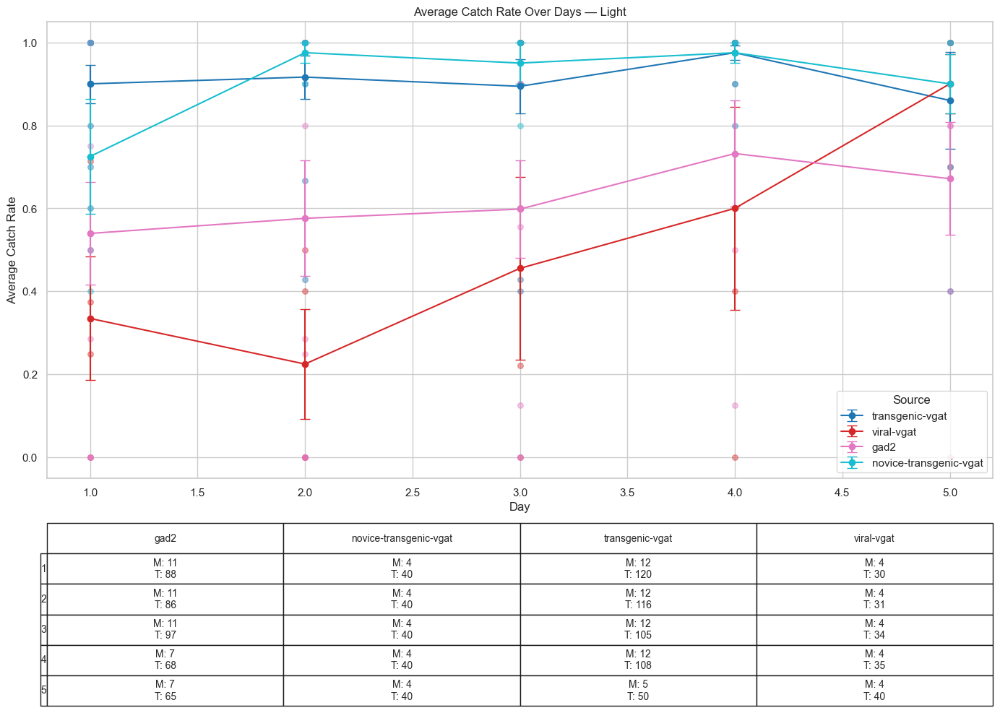

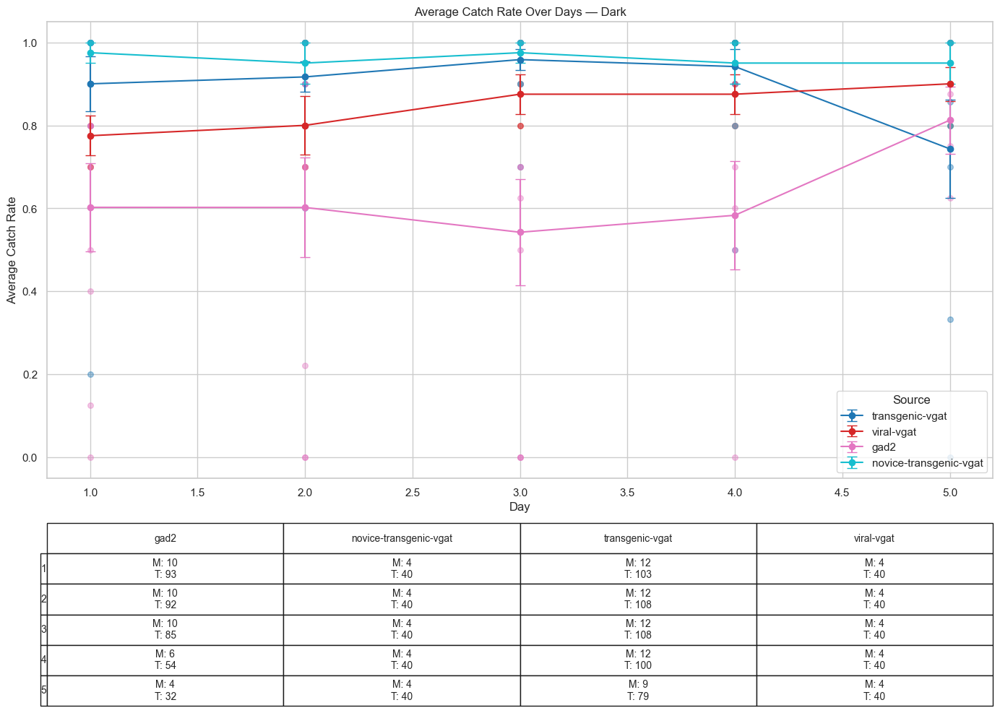

In [426]:
plot_catch_rate_with_counts_table(combined_df, 'light', save_path='/Users/mollyshallow/Desktop/WehrLab/PlotsForJen/learning_curves/catch_rate_light_wscatter.pdf')
plot_catch_rate_with_counts_table(combined_df, 'dark', save_path='/Users/mollyshallow/Desktop/WehrLab/PlotsForJen/learning_curves/catch_rate_dark_wscatter.pdf')


In [427]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def plot_catch_rate_by_sex_with_counts_table(combined_df, condition, save_path=None):
    df = combined_df.copy()
    df['sex'] = df['sex'].str.upper()  # Normalize sex labels to uppercase
    df_cond = df[df['condition'] == condition].dropna(subset=['catch_rate'])

    sexes = ['M', 'F']
    fig, axs = plt.subplots(2, 2, figsize=(16, 12), gridspec_kw={'height_ratios': [3, 1.5]})
    plt.subplots_adjust(hspace=0.5)

    # Unique sources and colors for consistent coloring
    sources = df_cond['source'].unique()
    colors = plt.cm.get_cmap('tab10', len(sources))
    source_colors = {source: colors(i) for i, source in enumerate(sources)}

    for i, sex in enumerate(sexes):
        df_sex = df_cond[df_cond['sex'] == sex]

        if df_sex.empty:
            axs[0, i].text(0.5, 0.5, f'No data for sex {sex} under condition "{condition}"',
                           ha='center', va='center', fontsize=14)
            axs[0, i].set_axis_off()
            axs[1, i].set_axis_off()
            continue

        ax_plot = axs[0, i]
        ax_table = axs[1, i]

        table_data = []

        for source, group in df_sex.groupby('source'):
            color = source_colors[source]

            # Plot individual mouse daily means as scatter
            mouse_day_means = group.groupby(['mouse_number', 'day'])['catch_rate'].mean().reset_index()
            for mouse in mouse_day_means['mouse_number'].unique():
                mouse_data = mouse_day_means[mouse_day_means['mouse_number'] == mouse]
                ax_plot.scatter(mouse_data['day'], mouse_data['catch_rate'], 
                                alpha=0.5, s=30, color=color, label=None)

            daily_avg = group.groupby('day')['catch_rate'].mean()
            daily_sem = group.groupby('day')['catch_rate'].sem()

            days = daily_avg.index.values
            values = daily_avg.values
            sem_values = daily_sem.values

            ax_plot.errorbar(days, values, yerr=sem_values, marker='o', capsize=5, label=source, color=color)

            # Collect counts for table
            daily_mice = group.groupby('day')['mouse_number'].nunique()
            daily_trials = group.groupby('day')['total_trials'].sum()

            for day in days:
                mice_count = daily_mice.get(day, np.nan)
                trials_count = daily_trials.get(day, np.nan)
                table_data.append({
                    'Day': day,
                    'Source': source,
                    'Mice': mice_count,
                    'Trials': trials_count
                })

        ax_plot.set_title(f"{sex} — {condition.capitalize()}", fontsize=14)
        ax_plot.set_xlabel("Day", fontsize=12)
        ax_plot.set_ylabel("Average Catch Rate", fontsize=12)
        ax_plot.grid(True)
        ax_plot.legend(title="Source")

        # Table setup
        table_df = pd.DataFrame(table_data)
        if not table_df.empty:
            table_pivot = table_df.pivot(index='Day', columns='Source', values=['Mice', 'Trials'])

            cell_text = []
            for day in table_pivot.index:
                row = []
                for source in table_pivot.columns.levels[1]:
                    try:
                        mice = table_pivot.loc[day, ('Mice', source)]
                        trials = table_pivot.loc[day, ('Trials', source)]
                        if pd.notna(mice) and pd.notna(trials):
                            row.append(f"M: {int(mice)}\nT: {int(trials)}")
                        else:
                            row.append("")
                    except KeyError:
                        row.append("")
                cell_text.append(row)

            col_labels = table_pivot.columns.levels[1].tolist()
            row_labels = [int(day) if float(day).is_integer() else day for day in table_pivot.index]

            ax_table.axis('off')
            table = ax_table.table(cellText=cell_text,
                                   rowLabels=row_labels,
                                   colLabels=col_labels,
                                   cellLoc='center',
                                   loc='center')

            table.auto_set_font_size(False)
            table.set_fontsize(12)

            # Make cells taller
            for (row, col), cell in table.get_celld().items():
                cell.set_height(cell.get_height() * 2.0)  # Increase vertical height
                if row == 0 and col >= 0:
                    cell.get_text().set_fontsize(12)
                    cell.get_text().set_ha('center')

    plt.suptitle(f"Catch Rate by Sex with Counts Table — Condition: {condition.capitalize()}", fontsize=18)

    plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle

    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight')

    plt.show()


/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/matplotlib/axes/_base.py:2480: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)


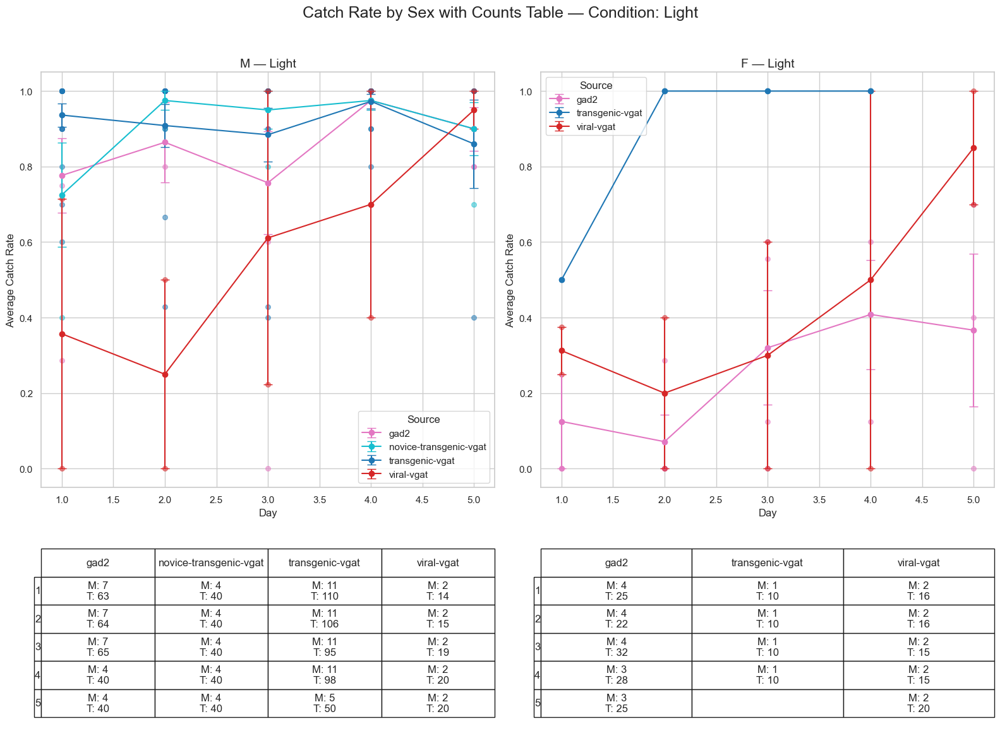

/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/matplotlib/axes/_base.py:2480: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)


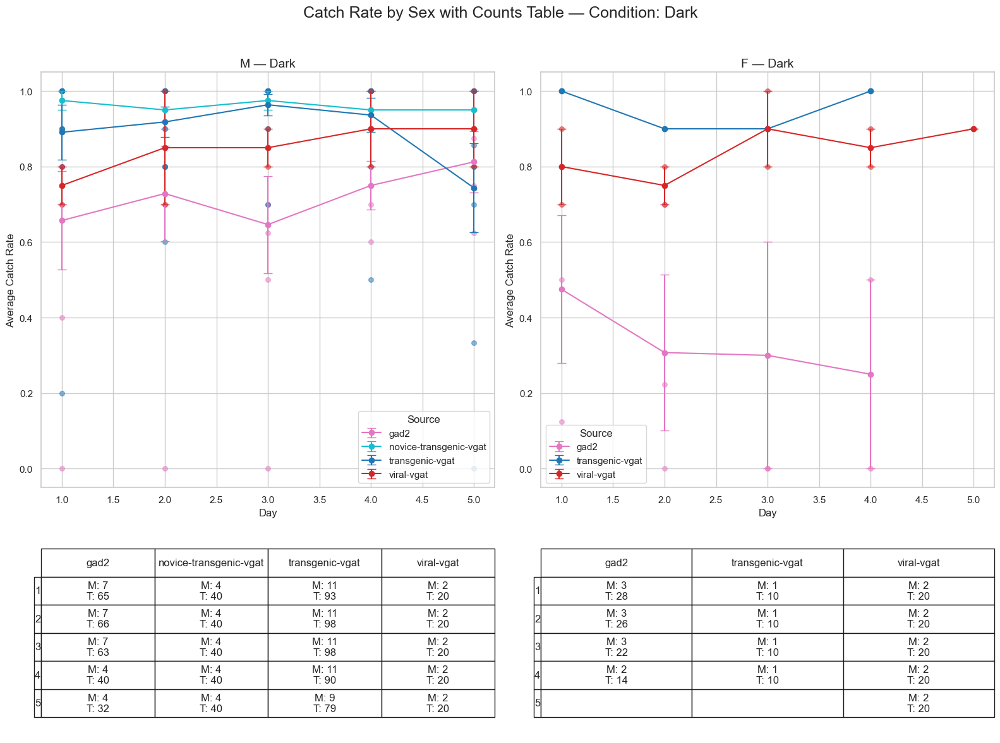

In [428]:
plot_catch_rate_by_sex_with_counts_table(combined_df, 'light', save_path='/Users/mollyshallow/Desktop/WehrLab/PlotsForJen/learning_curves/catch_rate_light_mf.pdf')
plot_catch_rate_by_sex_with_counts_table(combined_df, 'dark', save_path='/Users/mollyshallow/Desktop/WehrLab/PlotsForJen/learning_curves/catch_rate_dark_mf.pdf')



In [429]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def plot_catch_rate_by_sex_with_counts_table(combined_df, condition, save_path=None):
    df = combined_df.copy()
    df['sex'] = df['sex'].str.upper()  # Normalize sex labels to uppercase
    df_cond = df[df['condition'] == condition].dropna(subset=['catch_rate'])

    sexes = ['M', 'F']
    sources = df_cond['source'].unique()
    n_rows = len(sexes)
    n_cols = len(sources)

    # 🔥 DOUBLE subplot size by scaling figsize
    fig_width = 10 * n_cols     # Width per column
    fig_height = 10 * n_rows    # Height per row (each row has 2 subplots stacked: plot + table)

    fig, axs = plt.subplots(n_rows * 2, n_cols,
                            figsize=(fig_width, fig_height),
                            gridspec_kw={'height_ratios': [4, 2] * n_rows})

    if n_cols == 1:
        axs = np.array([[axs[i]] for i in range(n_rows * 2)])
    elif n_rows * 2 == 1:
        axs = np.array([axs])

    # plt.subplots_adjust(hspace=1.0)  # More space between plots and tables

    # Color map
    color_map = plt.cm.get_cmap('tab10', len(sources))
    source_colors = {source: color_map(i) for i, source in enumerate(sources)}

    for row_idx, sex in enumerate(sexes):
        df_sex = df_cond[df_cond['sex'] == sex]
        for col_idx, source in enumerate(sources):
            df_group = df_sex[df_sex['source'] == source]
            ax_plot = axs[row_idx * 2, col_idx]
            ax_table = axs[row_idx * 2 + 1, col_idx]

            if df_group.empty:
                ax_plot.text(0.5, 0.5, f'No data for {sex} / {source}',
                             ha='center', va='center', fontsize=20)
                ax_plot.set_axis_off()
                ax_table.set_axis_off()
                continue

            # Plot mouse lines
            mouse_day_means = df_group.groupby(['mouse_number', 'day'])['catch_rate'].mean().reset_index()
            for mouse in mouse_day_means['mouse_number'].unique():
                mouse_data = mouse_day_means[mouse_day_means['mouse_number'] == mouse]
                ax_plot.plot(mouse_data['day'], mouse_data['catch_rate'],
                             alpha=0.5, color=source_colors[source], label=None)
                ax_plot.scatter(mouse_data['day'], mouse_data['catch_rate'],
                                alpha=0.5, s=60, color=source_colors[source], label=None)

            # Mean ± SEM
            daily_avg = df_group.groupby('day')['catch_rate'].mean()
            daily_sem = df_group.groupby('day')['catch_rate'].sem()
            days = daily_avg.index.values
            ax_plot.errorbar(days, daily_avg.values, yerr=daily_sem.values,
                             marker='o', capsize=6, label='Mean ± SEM', color='black', linewidth=2)

            ax_plot.set_title(f"{sex} — {source}", fontsize=20)
            ax_plot.set_xlabel("Day", fontsize=18)
            ax_plot.set_ylabel("Catch Rate", fontsize=18)
            ax_plot.tick_params(labelsize=16)
            ax_plot.grid(True)

            # Table data
            table_data = []
            daily_mice = df_group.groupby('day')['mouse_number'].nunique()
            daily_trials = df_group.groupby('day')['total_trials'].sum()

            for day in sorted(df_group['day'].unique()):
                mice = daily_mice.get(day, np.nan)
                trials = daily_trials.get(day, np.nan)
                if pd.notna(mice) and pd.notna(trials):
                    table_data.append([int(day), f"M: {int(mice)}\nT: {int(trials)}"])

            if table_data:
                table_df = pd.DataFrame(table_data, columns=['Day', 'Info'])
                row_labels = table_df['Day'].tolist()
                cell_text = table_df['Info'].tolist()

                ax_table.axis('off')
                table = ax_table.table(cellText=[[text] for text in cell_text],
                                       rowLabels=row_labels,
                                       colLabels=["Counts"],
                                       cellLoc='center',
                                       loc='center')

                table.auto_set_font_size(False)
                table.set_fontsize(18)  # Larger font

                # Even bigger table cells
                for (row, col), cell in table.get_celld().items():
                    cell.set_height(cell.get_height() * 3.5)
                    cell.set_width(cell.get_width() * 1.8)
                    if row == 0 and col == 0:
                        cell.set_fontsize(18)
                        cell.set_text_props(weight='bold')

    plt.suptitle(f"Catch Rate by Sex and Source — Condition: {condition.capitalize()}",
                 fontsize=28, y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.95])

    if save_path:
        plt.savefig(save_path, format='pdf', bbox_inches='tight')

    plt.show()


/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/matplotlib/axes/_base.py:2480: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)


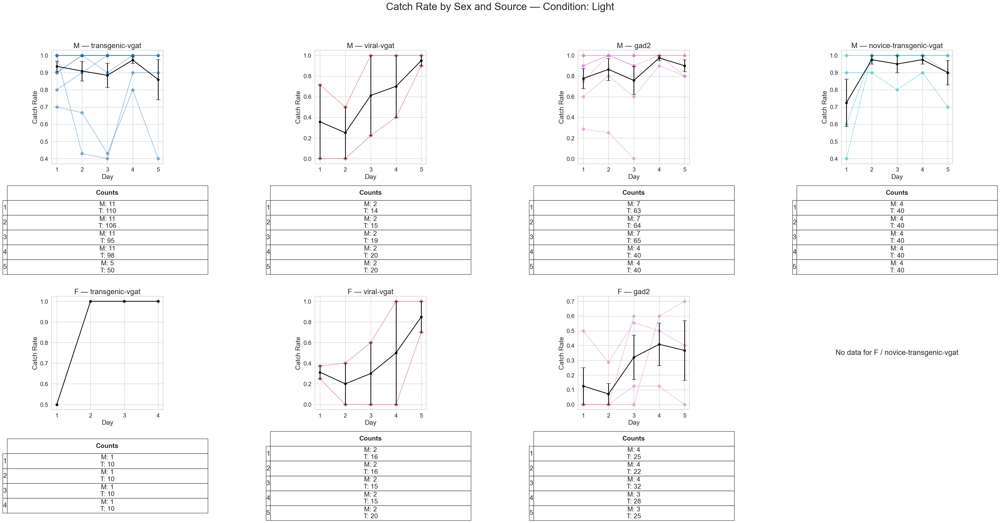

/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/matplotlib/axes/_base.py:2480: UserWarning: Warning: converting a masked element to nan.
  xys = np.asarray(xys)


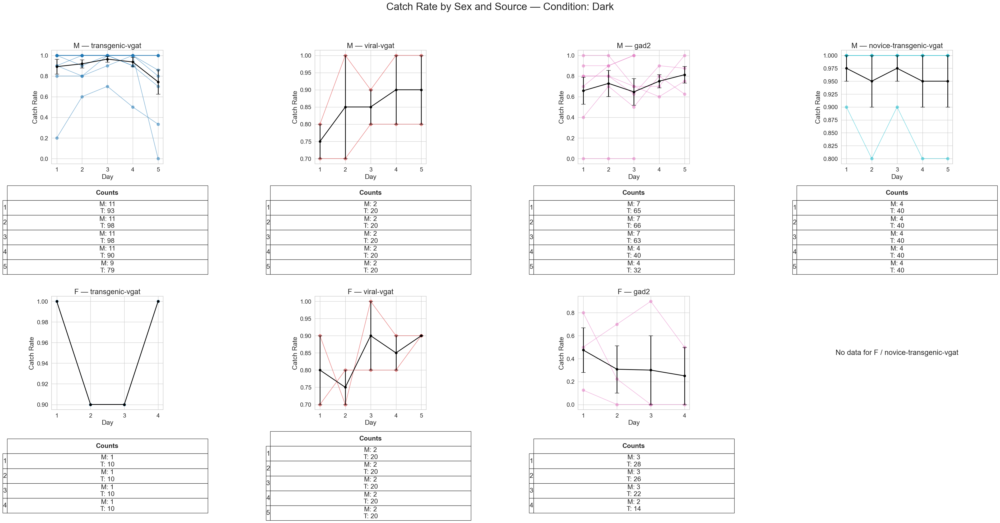

In [430]:
plot_catch_rate_by_sex_with_counts_table(combined_df, 'light', save_path='/Users/mollyshallow/Desktop/WehrLab/PlotsForJen/learning_curves/catch_rate_light_mf_indtrends.pdf')
plot_catch_rate_by_sex_with_counts_table(combined_df, 'dark', save_path='/Users/mollyshallow/Desktop/WehrLab/PlotsForJen/learning_curves/catch_rate_dark_mf_indtrends.pdf')



In [443]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

def plot_mean_az_spd_by_mouse_day(trial_df: pd.DataFrame,
                                  intercept_df: pd.DataFrame,
                                  fr: int = 200,
                                  window_sec: float = 2.5):
    """
    Plot mean azimuth and speed with SEM around intercepts, grouped by mouse and condition.
    Each plot contains subplots per day, labeled as Day 1, Day 2, etc.

    Args:
        trial_df (pd.DataFrame): trial-level data; each row contains list-type columns.
        intercept_df (pd.DataFrame): output from intercept function; contains 'filename' and 'intercept_frames'.
        fr (int): frame rate (Hz)
        window_sec (float): window in seconds before/after intercept
    """
    window_frames = int(window_sec * fr)
    time_axis = np.arange(-window_frames, window_frames + 1) / fr

    # Merge trial and intercept info
    merged = pd.merge(
        intercept_df,
        trial_df[['filename', 'mouse_spd', 'az', 'laser_value', 'condition']],
        on='filename',
        how='left'
    )

    # Extract mouse ID and date from filename
    def extract_mouse_date(filename):
        match = re.search(r'(\d{4}-\d{2}-\d{2}).*mouse-(\d+)', filename)
        return match.groups() if match else (None, None)

    merged[['date', 'mouse']] = merged['filename'].apply(lambda f: pd.Series(extract_mouse_date(f)))
    merged['date'] = pd.to_datetime(merged['date'])

    # Assign day index
    merged['day_index'] = merged.groupby(['condition', 'mouse'])['date'].rank(method='dense').astype(int)

    # Group by mouse and condition
    for (condition, mouse_id), group in merged.groupby(['condition', 'mouse']):
        n_days = group['day_index'].nunique()
        fig, axs = plt.subplots(2, n_days, figsize=(5 * n_days, 8), sharex=True)
        if n_days == 1:
            axs = np.array([[axs[0]], [axs[1]]])

        fig.suptitle(f"Mouse {mouse_id} — {condition}", fontsize=16)

        # Group by day and laser_value
        for (day_idx, laser_val), day_group in group.groupby(['day_index', 'laser_value']):
            if pd.isna(laser_val):
                continue
            try:
                laser_val = int(laser_val)
            except (ValueError, TypeError):
                continue

            az_traces = []
            spd_traces = []

            for _, row in day_group.iterrows():
                intercept_frames = row['intercept_frames']
                az_series = row['az']
                spd_series = row['mouse_spd']

                for idx in intercept_frames:
                    start = idx - window_frames
                    end = idx + window_frames
                    if start < 0 or end >= len(az_series):
                        continue
                    az_win = np.array(az_series[start:end + 1], dtype=np.float32)
                    spd_win = np.array(spd_series[start:end + 1], dtype=np.float32)
                    if len(az_win) == 2 * window_frames + 1:
                        az_traces.append(az_win)
                        spd_traces.append(spd_win)

            if not az_traces:
                continue

            az_stack = np.vstack(az_traces)
            spd_stack = np.vstack(spd_traces)

            az_mean = np.nanmean(az_stack, axis=0)
            az_sem = np.nanstd(az_stack, axis=0, ddof=1) / np.sqrt(az_stack.shape[0])
            spd_mean = np.nanmean(spd_stack, axis=0)
            spd_sem = np.nanstd(spd_stack, axis=0, ddof=1) / np.sqrt(spd_stack.shape[0])

            day = int(day_idx) - 1  # 0-indexed
            color = 'blue' if laser_val == 1 else 'gray'
            label = f"Laser {laser_val} (n={az_stack.shape[0]})"

            axs[0, day].plot(time_axis, az_mean, color=color, label=label)
            axs[0, day].fill_between(time_axis, az_mean - az_sem, az_mean + az_sem, color=color, alpha=0.3)

            axs[1, day].plot(time_axis, spd_mean, color=color, label=label)
            axs[1, day].fill_between(time_axis, spd_mean - spd_sem, spd_mean + spd_sem, color=color, alpha=0.3)

        for d in range(n_days):
            axs[0, d].axvline(0, color='k', linestyle='--')
            axs[0, d].set_title(f"Day {d + 1}")
            axs[0, d].set_ylabel("Azimuth (deg)")
            axs[0, d].grid(True)
            axs[0, d].legend()

            axs[1, d].axvline(0, color='k', linestyle='--')
            axs[1, d].set_ylabel("Speed (cm/s)")
            axs[1, d].set_xlabel("Time (s) from Intercept")
            axs[1, d].grid(True)
            axs[1, d].legend()

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()


In [431]:
lasers_intercept_df=intercepts_from_trialwise_df(cleaned_conds_keep)

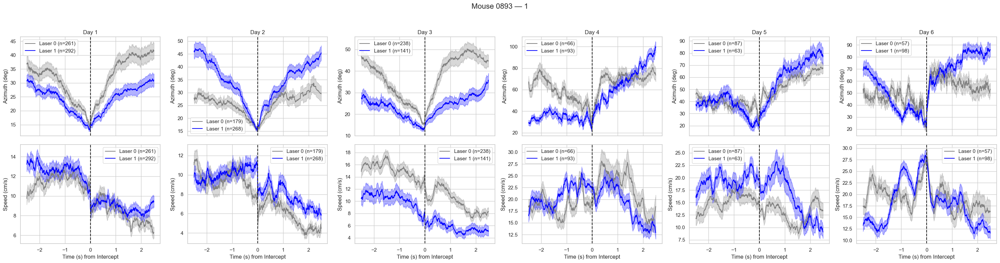

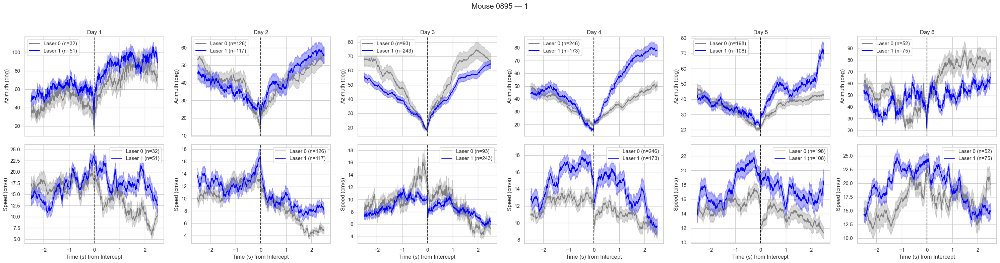

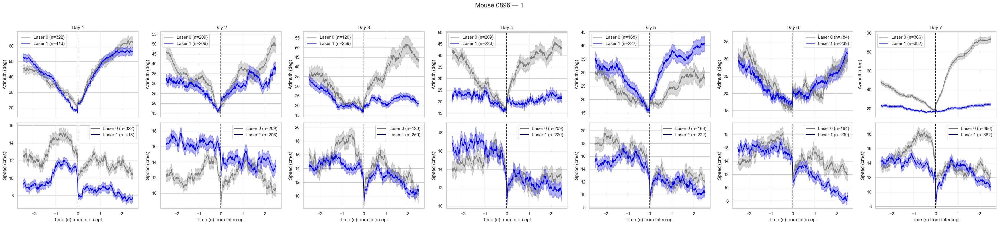

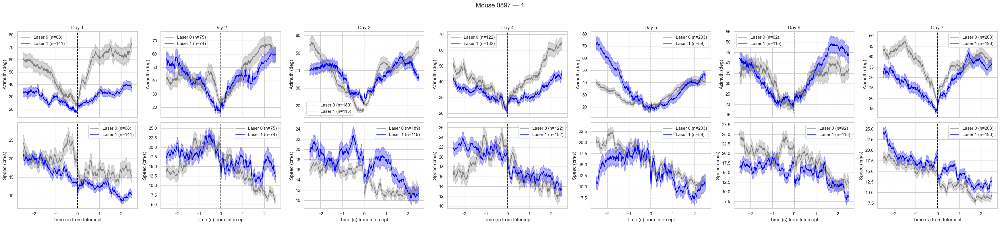

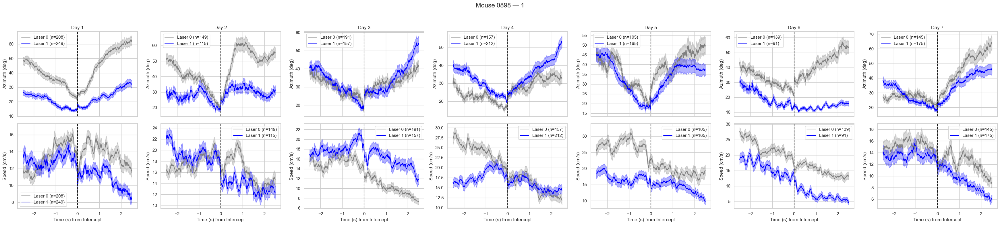

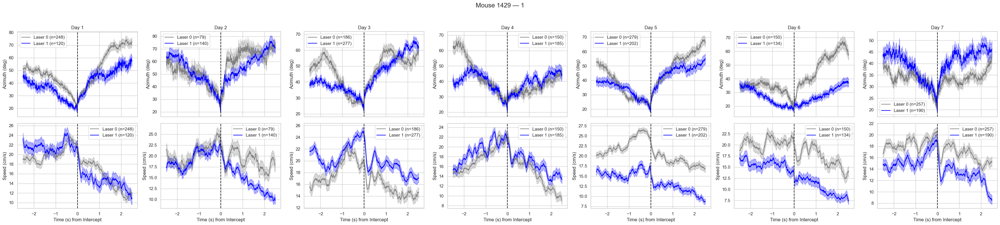

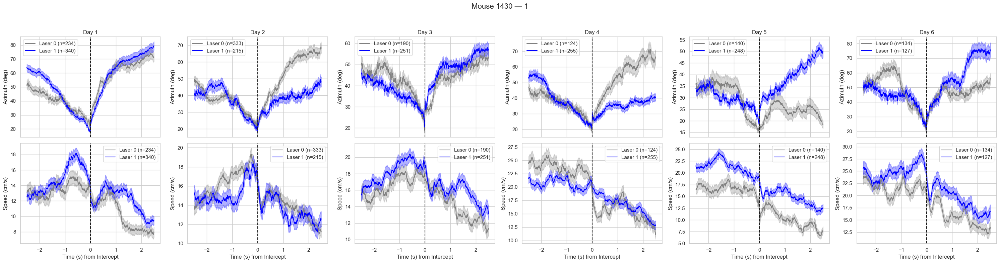

/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_92476/4252964135.py:85: RuntimeWarning: Mean of empty slice
  az_mean = np.nanmean(az_stack, axis=0)
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


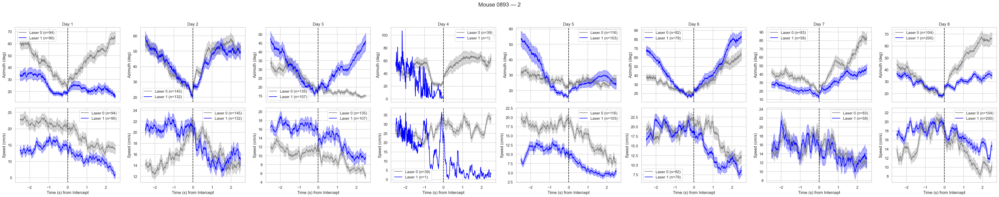

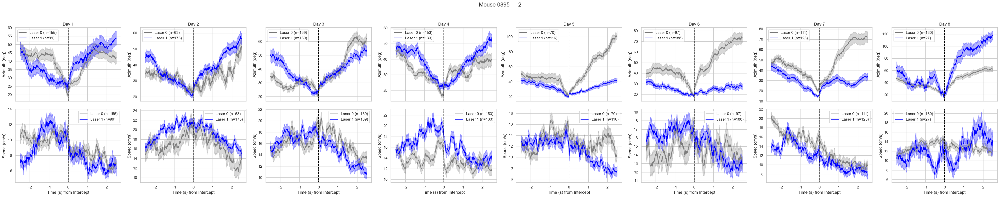

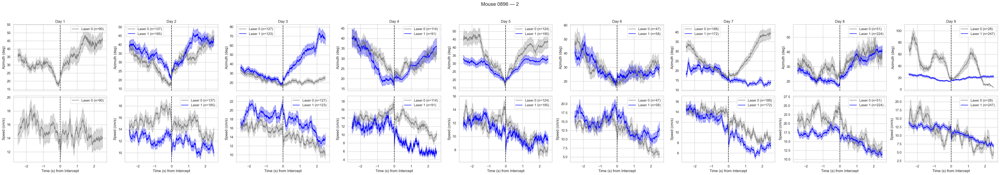

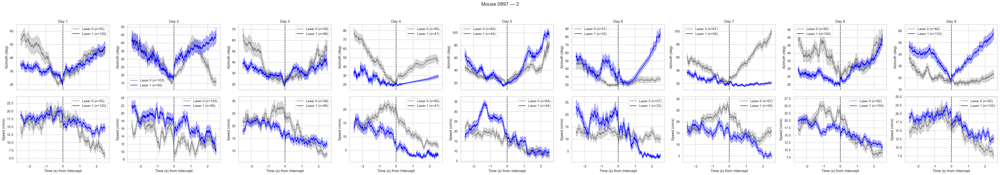

/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_92476/4252964135.py:85: RuntimeWarning: Mean of empty slice
  az_mean = np.nanmean(az_stack, axis=0)
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


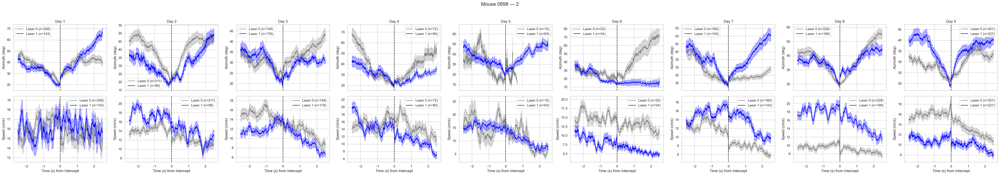

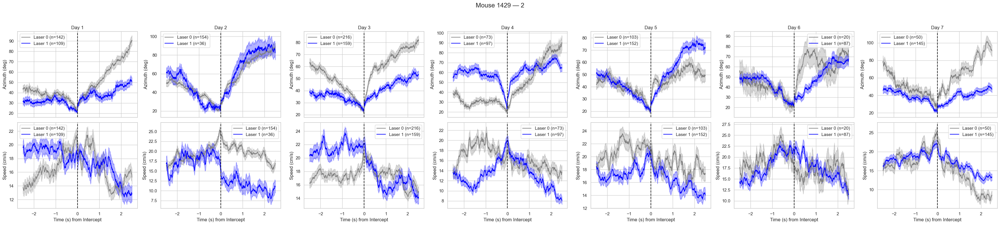

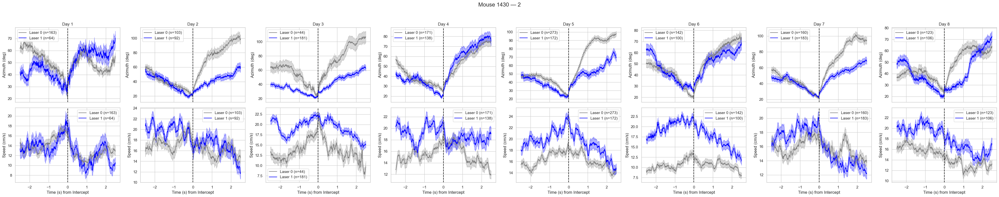

In [ ]:
plot_mean_az_spd_by_mouse_day(trial_df=cleaned_conds_keep, intercept_df=lasers_intercept_df)

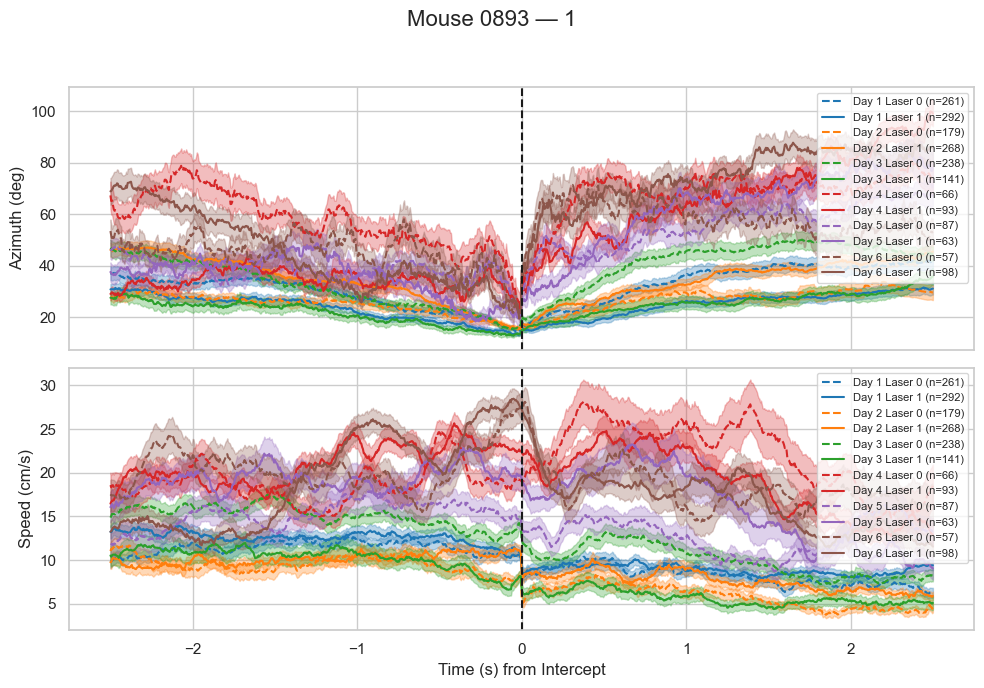

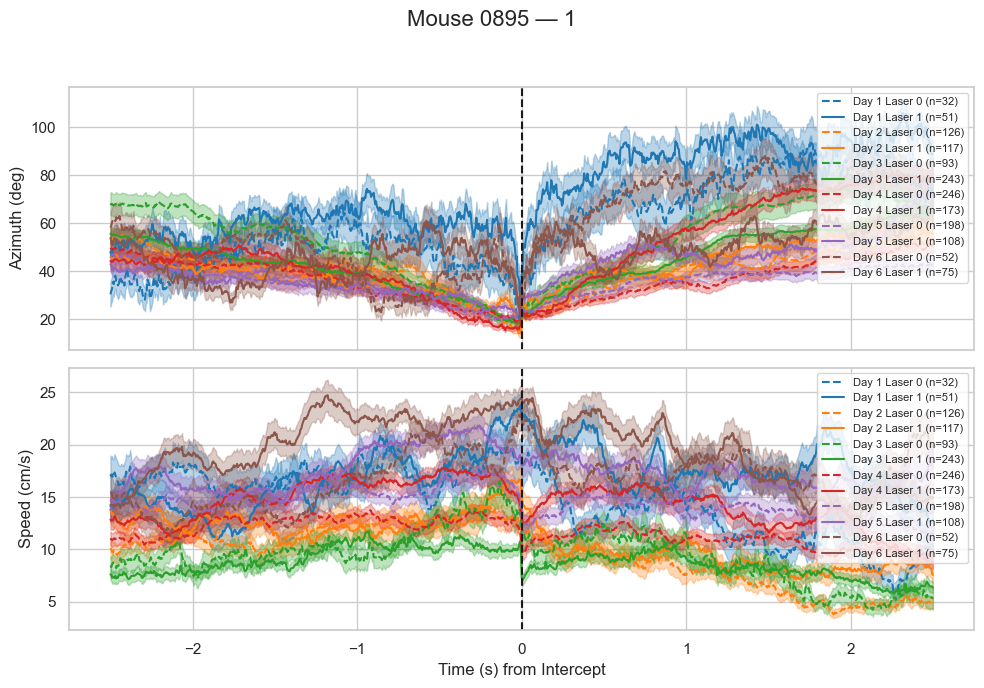

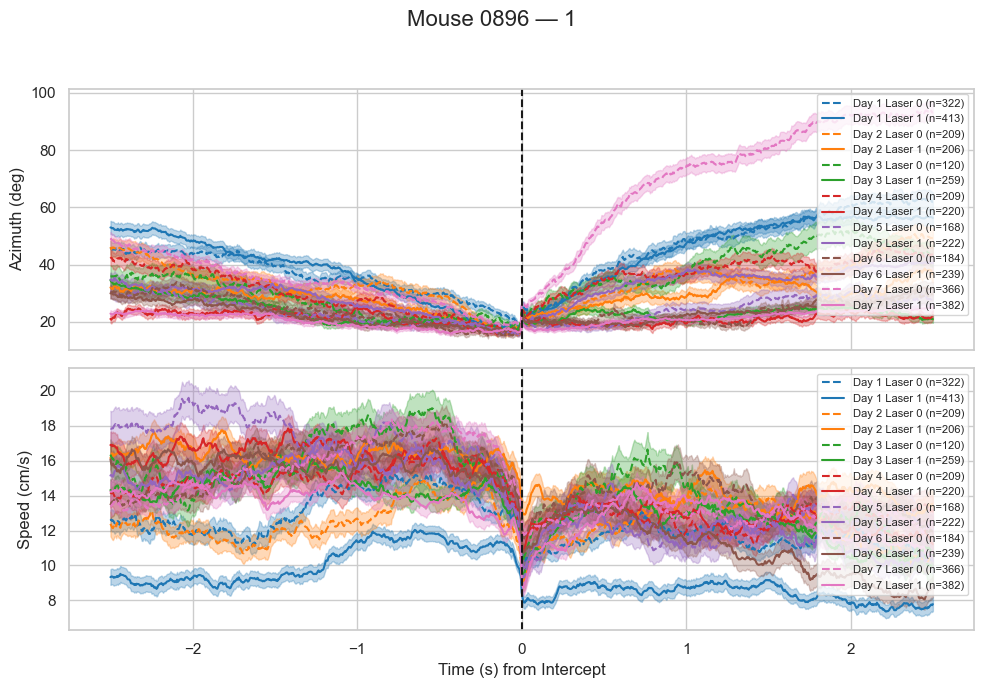

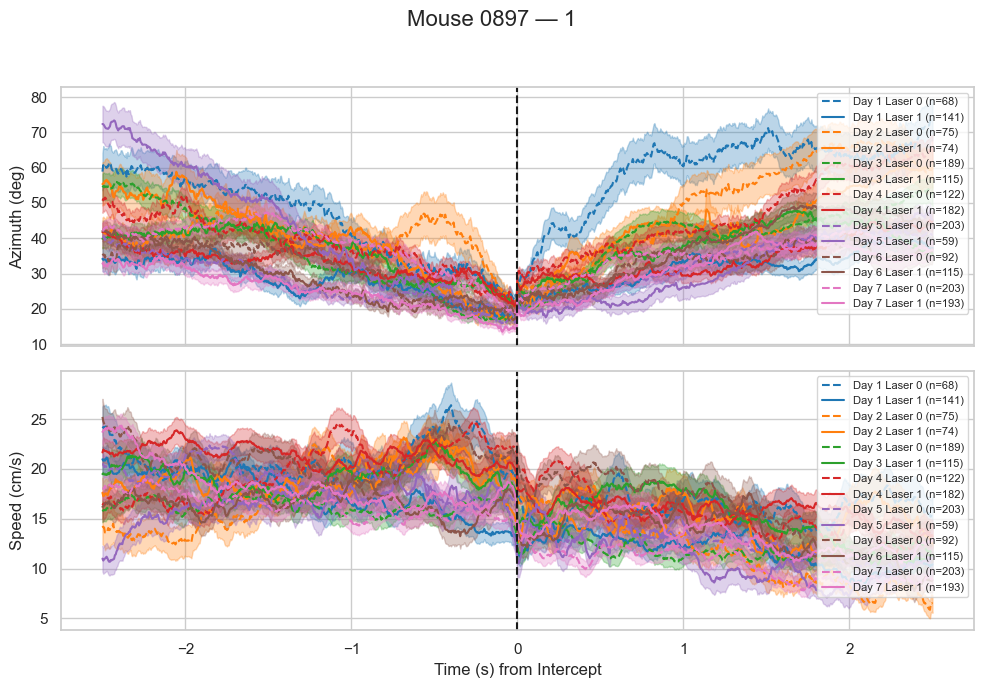

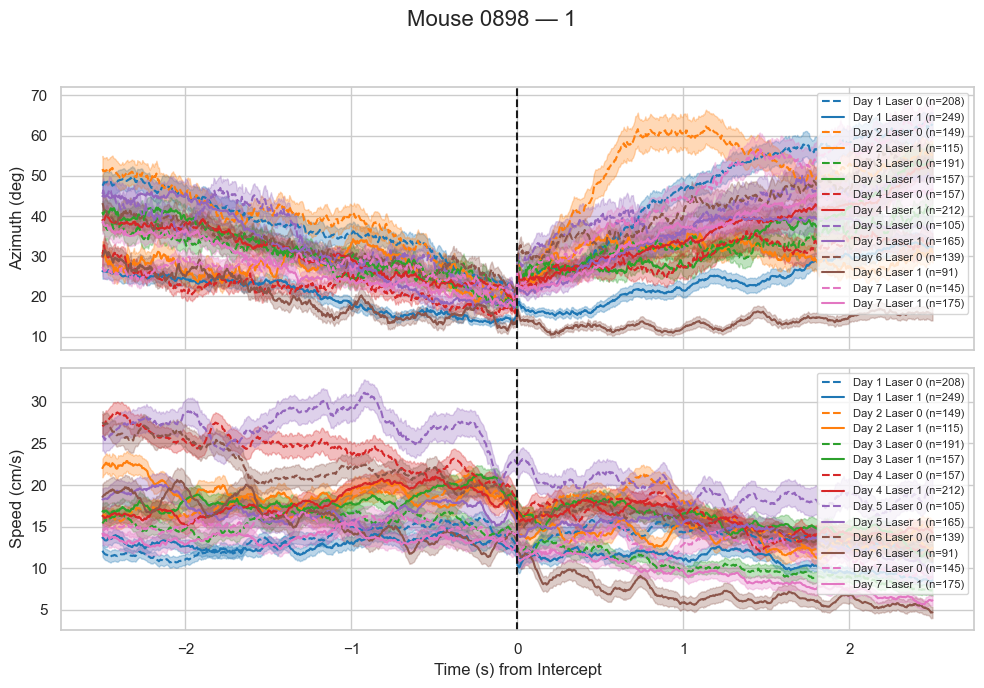

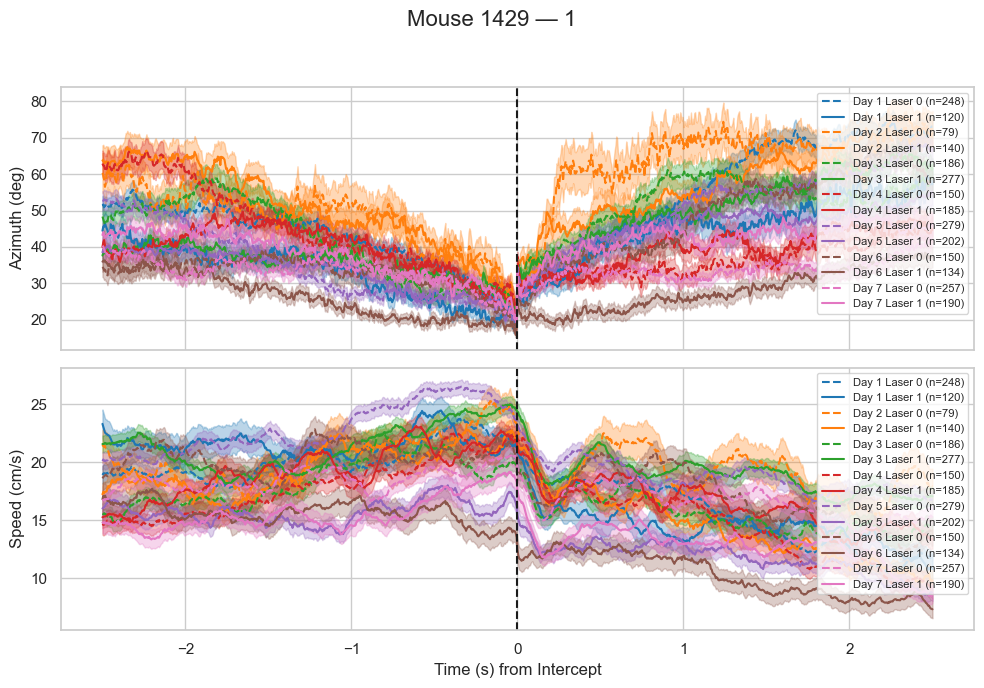

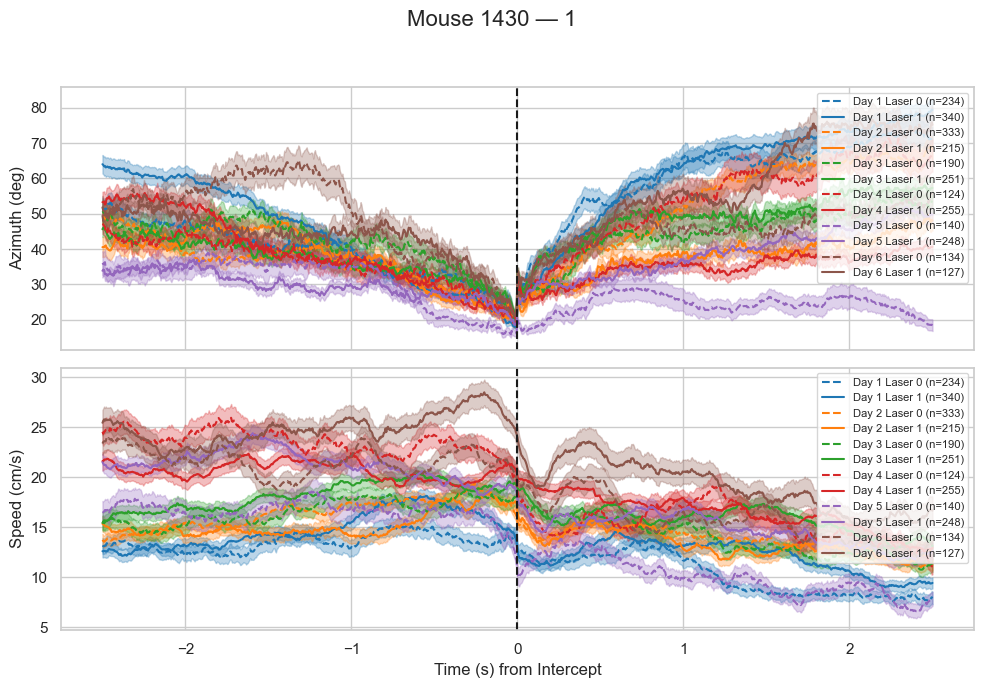

ValueError: cannot convert float NaN to integer

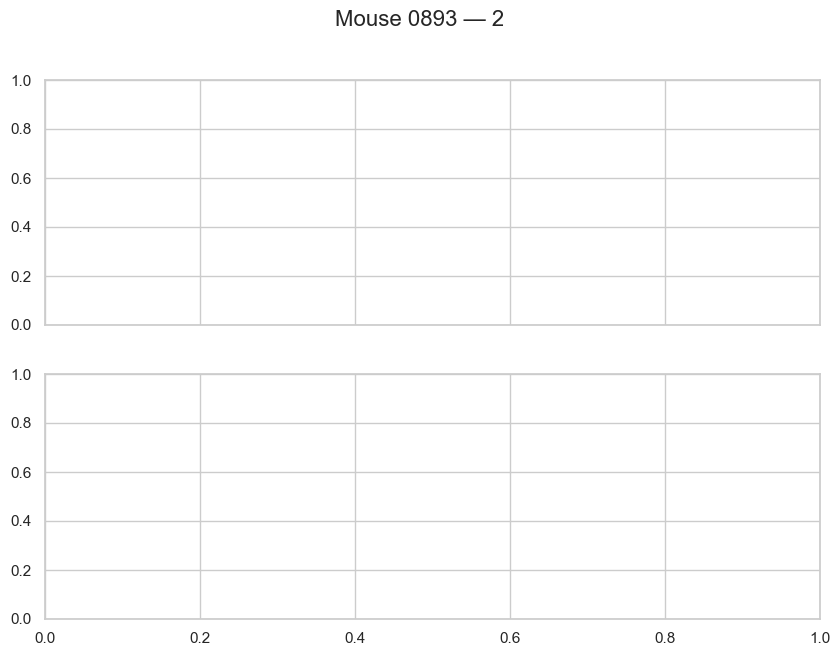

In [447]:
plot_mean_az_spd_by_mouse_all_days(trial_df=cleaned_conds_keep, intercept_df=lasers_intercept_df)

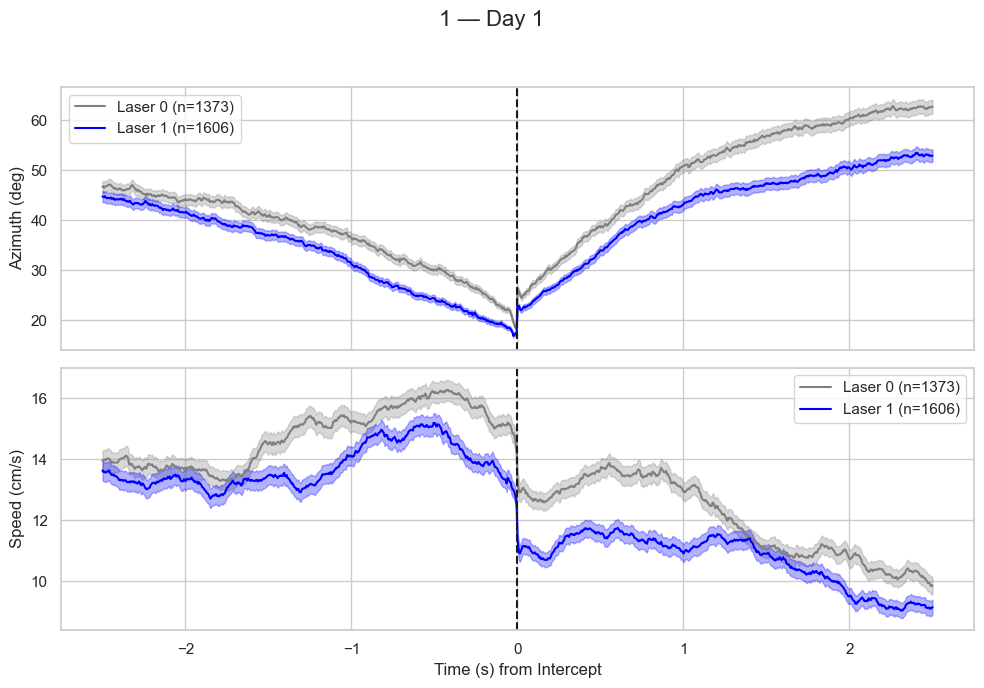

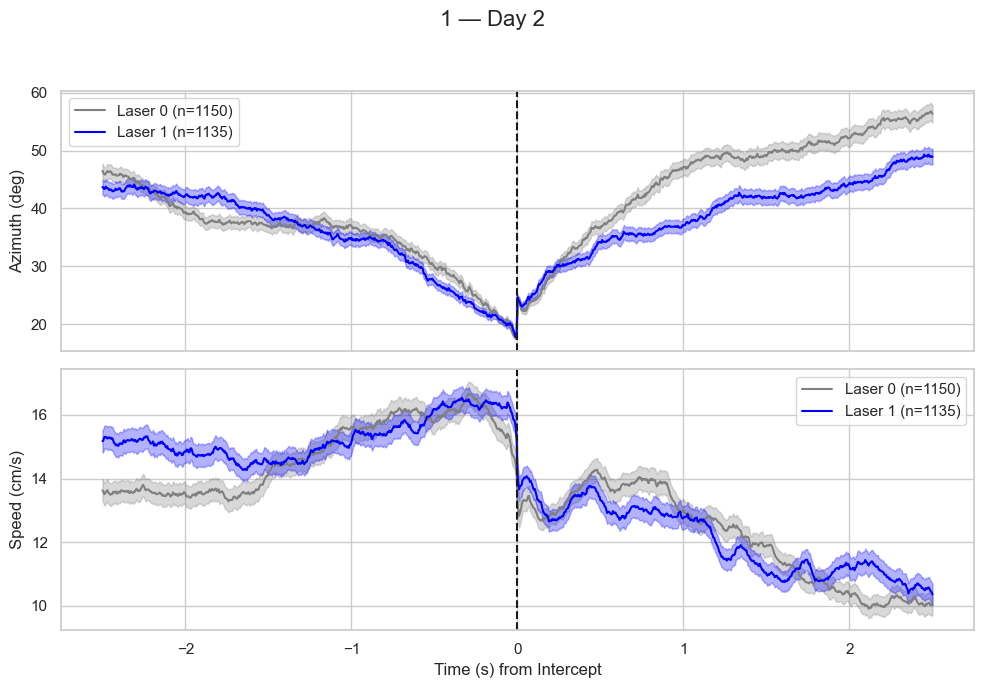

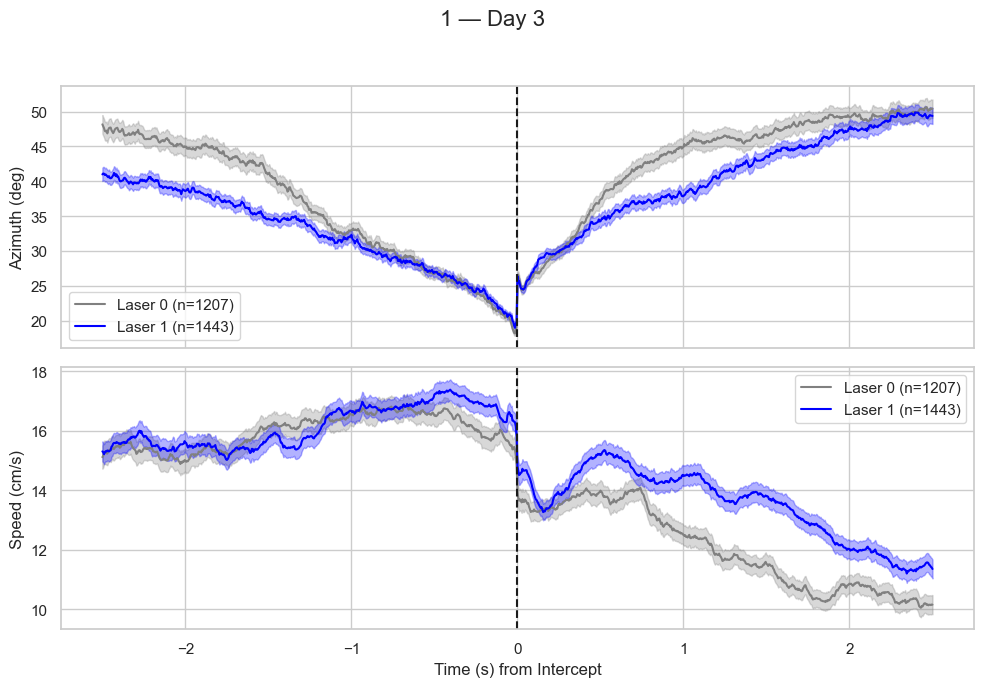

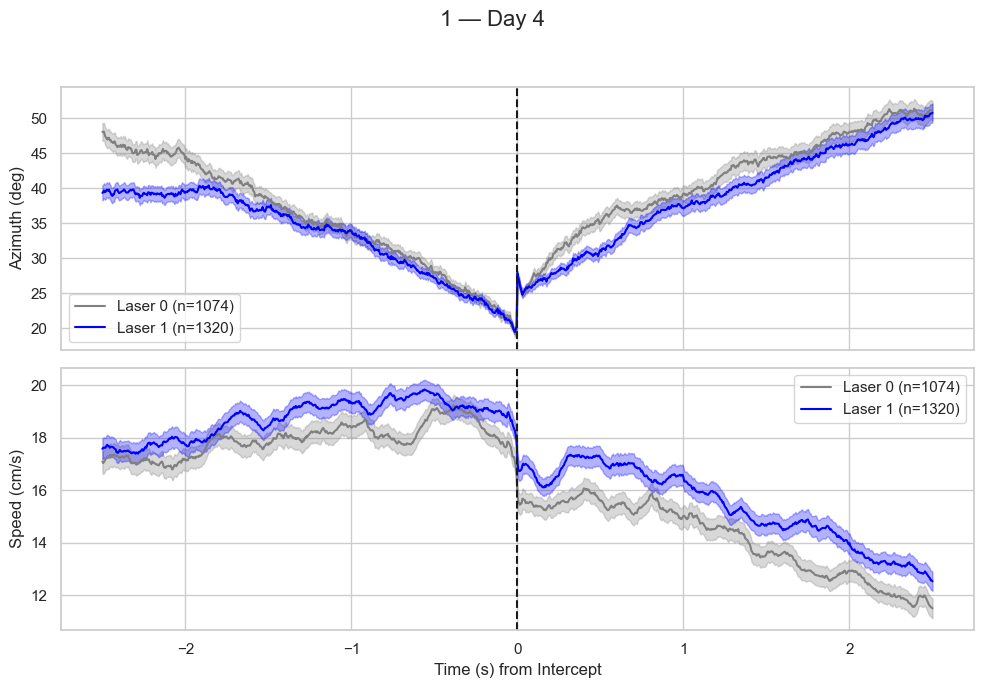

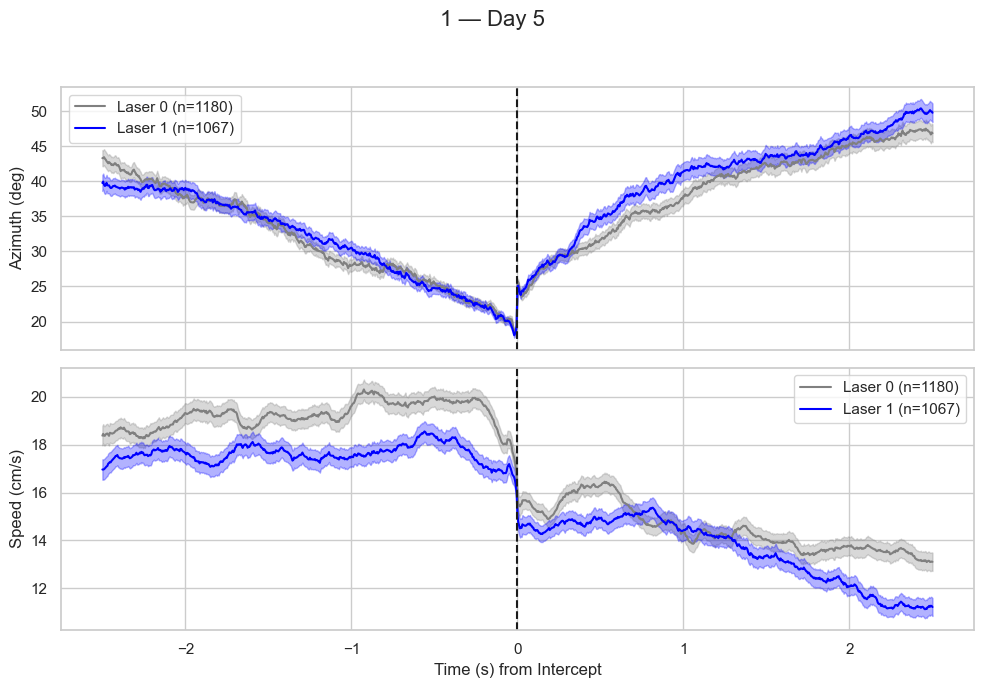

...

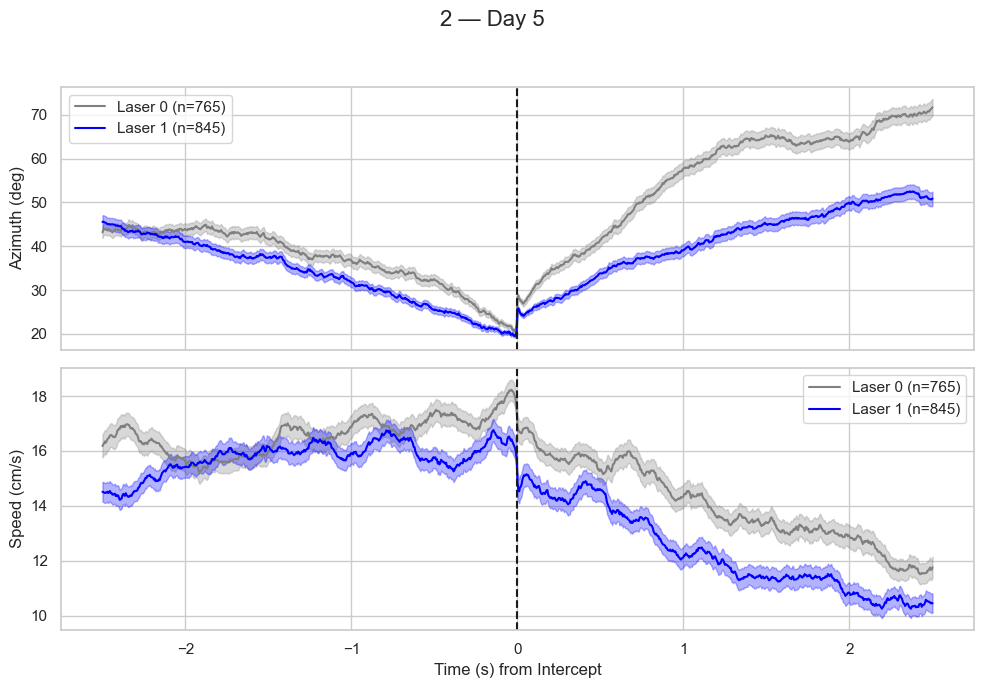

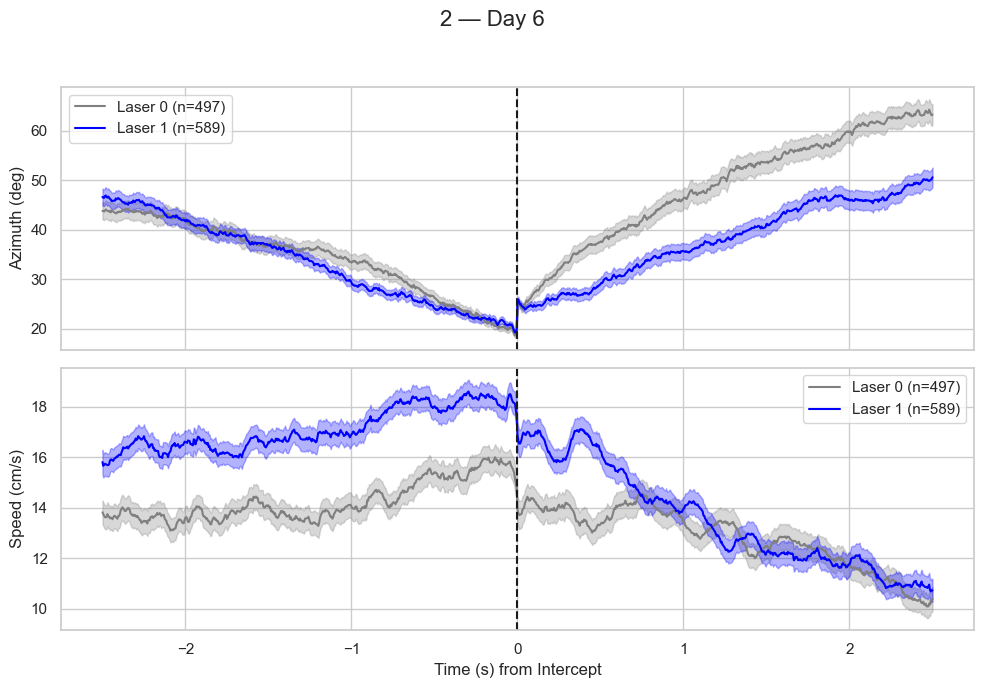

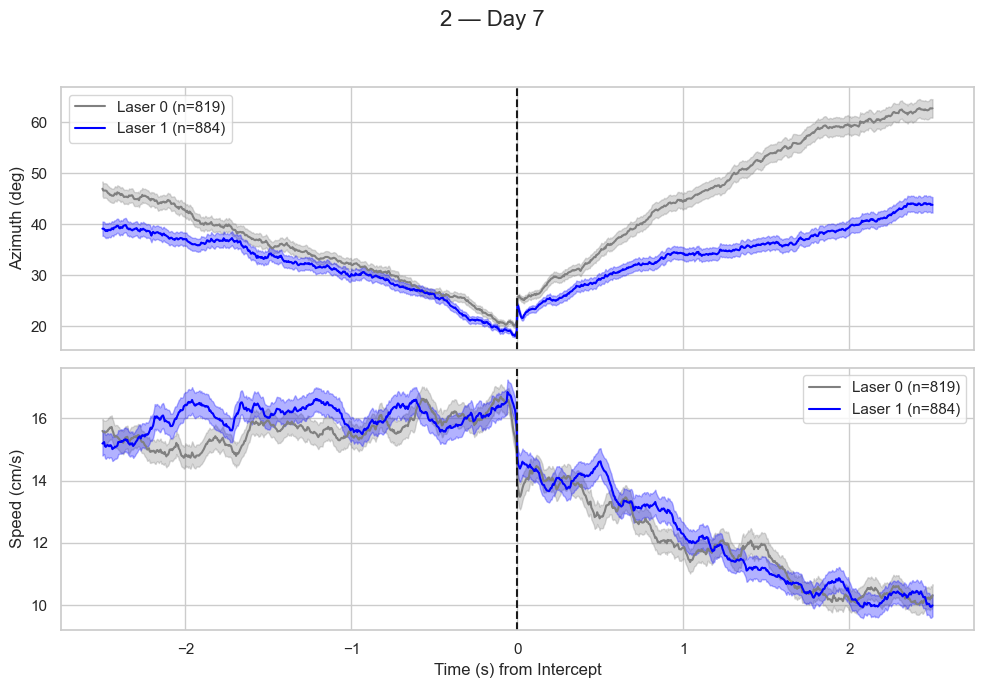

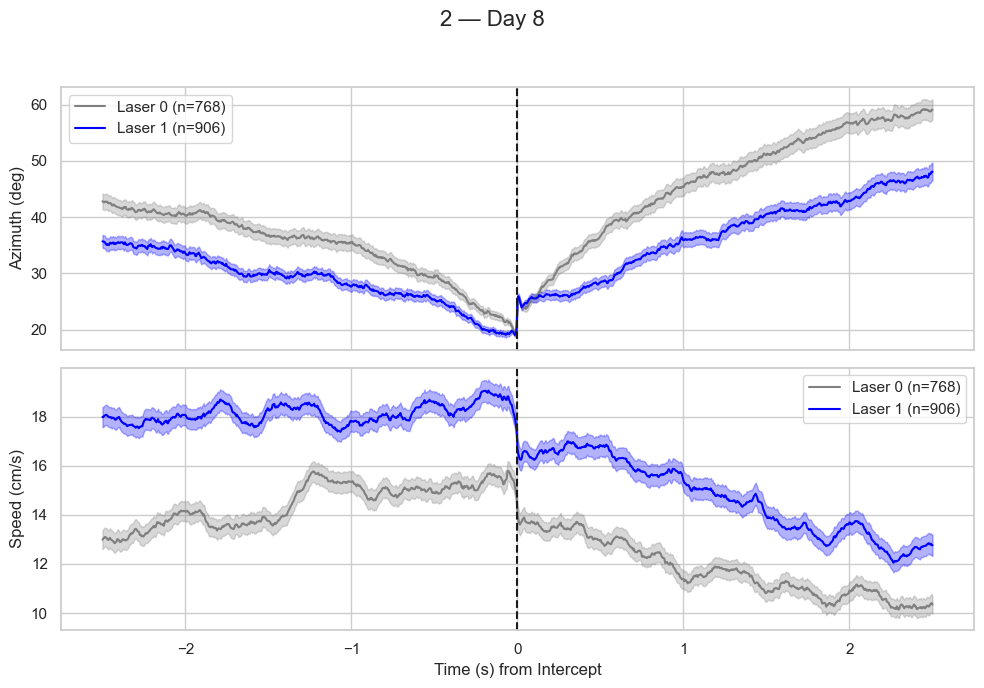

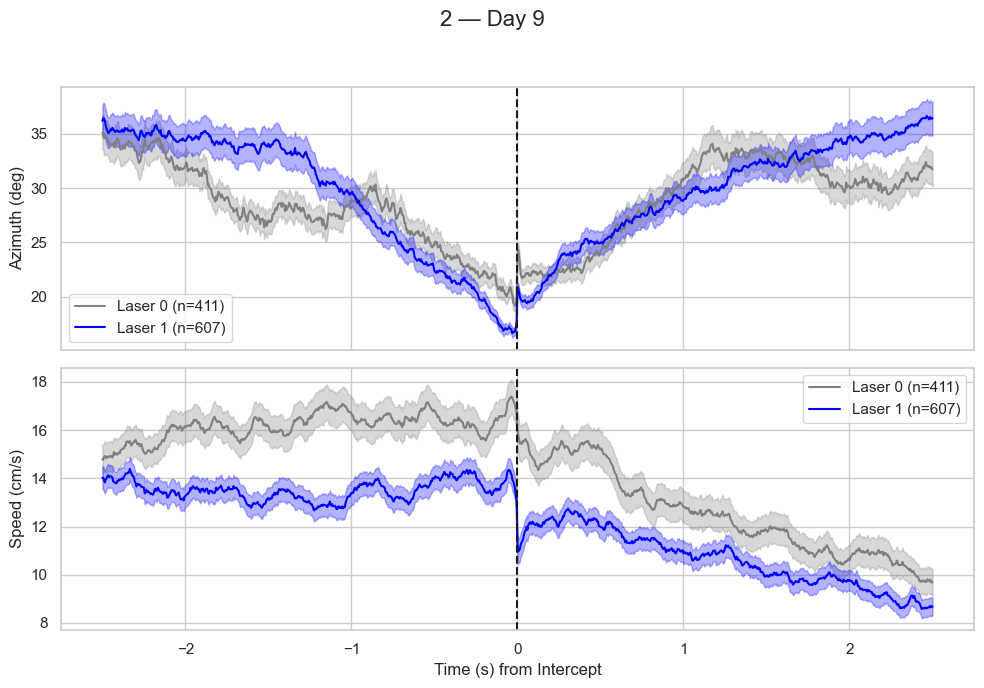

In [450]:
plot_pooled_by_day(trial_df=cleaned_conds_keep, intercept_df=lasers_intercept_df)

In [494]:
pip install statsannotations

ERROR: Could not find a version that satisfies the requirement statsannotations (from versions: none)
ERROR: No matching distribution found for statsannotations
Note: you may need to restart the kernel to use updated packages.


In [535]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re
import matplotlib.cm as cm
import seaborn as sns
from scipy.stats import wilcoxon
# from statannotations.Annotator import Annotator  # If you want brackets with p-values (needs statannotations package)

def plot_laser_analysis_with_saving(trial_df: pd.DataFrame,
                                   intercept_df: pd.DataFrame,
                                   fr: int = 200,
                                   window_sec: float = 2.5,
                                   save_dir: str = '.'):
    """
    Plot time series, peak violin plots, number of contacts violin plots,
    and dot plots of medians per mouse and overall median, comparing laser=0 and laser=1
    within each condition. Saves all plots as PDFs in save_dir.
    """

    window_frames = int(window_sec * fr)
    time_axis = np.arange(-window_frames, window_frames + 1) / fr

    # Merge metadata
    merged = pd.merge(intercept_df, trial_df[['filename', 'mouse_spd', 'az', 'laser_value', 'condition']],
                      on='filename', how='left')

    # Drop rows where laser_value is NaN
    merged = merged[merged['laser_value'].notna()]

    # Extract mouse ID from filename (assumes "mouse-XXXX" somewhere in filename)
    def extract_mouse(filename):
        m = re.search(r'mouse-([^\W_]+)', filename)
        return m.group(1) if m else np.nan
    merged['mouse'] = merged['filename'].apply(extract_mouse)
    merged = merged[merged['mouse'].notna()]

    cmap = {0: 'grey', 1: 'blue'}

    # 1. Time series plots by condition and laser value
    for condition, cond_group in merged.groupby('condition'):
        fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
        fig.suptitle(f"{condition} — Time Series", fontsize=16)

        for laser_val in [0, 1]:
            az_traces = []
            spd_traces = []

            laser_group = cond_group[cond_group['laser_value'] == laser_val]

            for _, row in laser_group.iterrows():
                for idx in row['intercept_frames']:
                    start = idx - window_frames
                    end = idx + window_frames
                    if start < 0 or end >= len(row['az']):
                        continue
                    az_win = np.array(row['az'][start:end + 1], dtype=np.float32)
                    spd_win = np.array(row['mouse_spd'][start:end + 1], dtype=np.float32)
                    if len(az_win) == 2 * window_frames + 1:
                        az_traces.append(az_win)
                        spd_traces.append(spd_win)

            if not az_traces:
                continue

            az_stack = np.vstack(az_traces)
            spd_stack = np.vstack(spd_traces)

            az_median = np.nanmedian(az_stack, axis=0)
            az_sem = np.nanstd(az_stack, axis=0, ddof=1) / np.sqrt(az_stack.shape[0])
            spd_median = np.nanmedian(spd_stack, axis=0)
            spd_sem = np.nanstd(spd_stack, axis=0, ddof=1) / np.sqrt(spd_stack.shape[0])

            linestyle = '-' if laser_val == 1 else '--'
            label = f"Laser {laser_val} (n={az_stack.shape[0]})"
            color = cmap[laser_val]

            axs[0].plot(time_axis, az_median, color=color, linestyle=linestyle, label=label)
            axs[0].fill_between(time_axis, az_median - az_sem, az_median + az_sem, color=color, alpha=0.3)

            axs[1].plot(time_axis, spd_median, color=color, linestyle=linestyle, label=label)
            axs[1].fill_between(time_axis, spd_median - spd_sem, spd_median + spd_sem, color=color, alpha=0.3)

        axs[0].axvline(0, color='k', linestyle='--')
        axs[0].set_ylabel("Azimuth (deg)")
        axs[0].legend(loc='upper right', fontsize=8)
        axs[0].grid(True)

        axs[1].axvline(0, color='k', linestyle='--')
        axs[1].set_ylabel("Speed (cm/s)")
        axs[1].set_xlabel("Time (s) from Intercept")
        axs[1].legend(loc='upper right', fontsize=8)
        axs[1].grid(True)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.savefig(f"{save_dir}/{condition}_time_series.pdf")
        plt.close()

    # Prepare data for peak and contacts plots
    peak_data = []
    contacts_data = []

    for condition, cond_group in merged.groupby('condition'):
        for laser_val in [0, 1]:
            laser_group = cond_group[cond_group['laser_value'] == laser_val]

            for mouse, mouse_group in laser_group.groupby('mouse'):
                all_peaks = []
                for _, row in mouse_group.iterrows():
                    for idx in row['intercept_frames']:
                        start = idx - window_frames
                        end = idx + window_frames
                        if start < 0 or end >= len(row['az']):
                            continue
                        spd_win = np.array(row['mouse_spd'][start:end + 1], dtype=np.float32)
                        pre_win = spd_win[:window_frames]  # pre-contact window
                        peak_speed = np.max(pre_win)
                        all_peaks.append(peak_speed)

                if all_peaks:
                    median_peak = np.median(all_peaks)
                    peak_data.append({'condition': condition, 'laser_value': laser_val,
                                      'mouse': mouse, 'median_peak': median_peak})

                # Number of contacts per mouse/laser/condition
                n_contacts = mouse_group['intercept_frames'].apply(len).sum()
                contacts_data.append({'condition': condition, 'laser_value': laser_val,
                                      'mouse': mouse, 'n_contacts': n_contacts})

    peak_df = pd.DataFrame(peak_data)
    contacts_df = pd.DataFrame(contacts_data)

    # 2. Peak speed violin plots with stats brackets
    for condition, cond_peak_df in peak_df.groupby('condition'):
        plt.figure(figsize=(8,6))
        sns.violinplot(data=cond_peak_df, x='laser_value', y='median_peak',
                       palette=[cmap[0], cmap[1]], inner=None)
        sns.swarmplot(data=cond_peak_df, x='laser_value', y='median_peak',
                      color='k', alpha=0.7, size=4)

        # Statistical test (Wilcoxon signed-rank test, paired by mouse)
        laser0 = cond_peak_df[cond_peak_df['laser_value'] == 0].set_index('mouse')['median_peak']
        laser1 = cond_peak_df[cond_peak_df['laser_value'] == 1].set_index('mouse')['median_peak']
        common_mice = laser0.index.intersection(laser1.index)
        if len(common_mice) > 0:
            stat, p = wilcoxon(laser0.loc[common_mice], laser1.loc[common_mice])
            p_text = f"p = {p:.3g}"
        else:
            p_text = "p = N/A (no paired data)"

        plt.title(f"{condition} — Peak Speed Pre-contact\n{p_text}")
        plt.xlabel("Laser Value")
        plt.ylabel("Median Peak Speed (cm/s)")
        plt.xticks([0, 1], ['Laser 0 (grey)', 'Laser 1 (blue)'])
        plt.grid(True)

        # Add bracket manually
        y_max = cond_peak_df['median_peak'].max()
        y_min = cond_peak_df['median_peak'].min()
        y_bracket = y_max + (y_max - y_min) * 0.1

        plt.plot([0, 0, 1, 1], [y_bracket - (y_max - y_min)*0.02, y_bracket, y_bracket, y_bracket - (y_max - y_min)*0.02], color='k')
        plt.text(0.5, y_bracket + (y_max - y_min)*0.02, p_text, ha='center')

        plt.tight_layout()
        plt.savefig(f"{save_dir}/{condition}_peak_speed_violin.pdf")
        plt.close()

    # 3. Number of contacts violin plots with stats brackets
    for condition, cond_contacts_df in contacts_df.groupby('condition'):
        plt.figure(figsize=(8,6))
        sns.violinplot(data=cond_contacts_df, x='laser_value', y='n_contacts',
                       palette=[cmap[0], cmap[1]], inner=None)
        sns.swarmplot(data=cond_contacts_df, x='laser_value', y='n_contacts',
                      color='k', alpha=0.7, size=4)

        # Statistical test (Wilcoxon signed-rank test, paired by mouse)
        laser0 = cond_contacts_df[cond_contacts_df['laser_value'] == 0].set_index('mouse')['n_contacts']
        laser1 = cond_contacts_df[cond_contacts_df['laser_value'] == 1].set_index('mouse')['n_contacts']
        common_mice = laser0.index.intersection(laser1.index)
        if len(common_mice) > 0:
            stat, p = wilcoxon(laser0.loc[common_mice], laser1.loc[common_mice])
            p_text = f"p = {p:.3g}"
        else:
            p_text = "p = N/A (no paired data)"

        plt.title(f"{condition} — Number of Contacts\n{p_text}")
        plt.xlabel("Laser Value")
        plt.ylabel("Number of Contacts")
        plt.xticks([0, 1], ['Laser 0 (grey)', 'Laser 1 (blue)'])
        plt.grid(True)

        # Add bracket manually
        y_max = cond_contacts_df['n_contacts'].max()
        y_min = cond_contacts_df['n_contacts'].min()
        y_bracket = y_max + (y_max - y_min) * 0.1

        plt.plot([0, 0, 1, 1], [y_bracket - (y_max - y_min)*0.02, y_bracket, y_bracket, y_bracket - (y_max - y_min)*0.02], color='k')
        plt.text(0.5, y_bracket + (y_max - y_min)*0.02, p_text, ha='center')

        plt.tight_layout()
        plt.savefig(f"{save_dir}/{condition}_contacts_violin.pdf")
        plt.close()

    # 4. Dot plots for peaks and contacts
    for df, val_col, ylabel, fname_prefix in [
        (peak_df, 'median_peak', "Median Peak Speed (cm/s)", 'peak_speed_dotplot'),
        (contacts_df, 'n_contacts', "Number of Contacts", 'contacts_dotplot'),
    ]:
        for condition, cond_df in df.groupby('condition'):
            plt.figure(figsize=(8,6))
            colors = cond_df['laser_value'].map(cmap)
            unique_lasers = sorted(cond_df['laser_value'].unique())
            xpos_map = {val: i for i, val in enumerate(unique_lasers)}

            # Plot individual mouse medians (alphaed)
            for laser_val in unique_lasers:
                subset = cond_df[cond_df['laser_value'] == laser_val]
                x = np.full(len(subset), xpos_map[laser_val]) + (np.random.rand(len(subset)) - 0.5)*0.1
                plt.scatter(x, subset[val_col], color=cmap[laser_val], alpha=0.5, s=40, label=f"Laser {laser_val} mice")

            # Plot overall median (big dot)
            for laser_val in unique_lasers:
                median_val = cond_df[cond_df['laser_value'] == laser_val][val_col].median()
                plt.scatter(xpos_map[laser_val], median_val, color=cmap[laser_val], s=100, edgecolor='k', label=f"Laser {laser_val} median")

            plt.xticks([xpos_map[lv] for lv in unique_lasers],
                       [f"Laser {lv}" for lv in unique_lasers])
            plt.xlabel("Laser Value")
            plt.ylabel(ylabel)
            plt.title(f"{condition} — {ylabel}")

            # Statistical test
            laser0 = cond_df[cond_df['laser_value'] == 0].set_index('mouse')[val_col]
            laser1 = cond_df[cond_df['laser_value'] == 1].set_index('mouse')[val_col]
            common_mice = laser0.index.intersection(laser1.index)
            if len(common_mice) > 0:
                stat, p = wilcoxon(laser0.loc[common_mice], laser1.loc[common_mice])
                p_text = f"p = {p:.3g}"
            else:
                p_text = "p = N/A (no paired data)"

            # Place p-value text above points
            y_max = cond_df[val_col].max()
            y_min = cond_df[val_col].min()
            y_pos = y_max + (y_max - y_min)*0.1
            plt.text(np.mean(list(xpos_map.values())), y_pos, p_text,
                     ha='center', fontsize=12)

            plt.grid(True)
            plt.tight_layout()
            plt.savefig(f"{save_dir}/{condition}_{fname_prefix}.pdf")
            plt.close()

    print(f"All plots saved to {save_dir}")



In [537]:
plot_laser_analysis_with_saving(trial_df=cleaned_conds_keep, intercept_df=lasers_intercept_df, fr=200, window_sec=2.5, save_dir='/Users/mollyshallow/Desktop/WehrLab/contact_aligned_geos_plots')


posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
posx and posy should be finite values
posx and posy should be finite values
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
posx and posy sh

All plots saved to /Users/mollyshallow/Desktop/WehrLab/contact_aligned_geos_plots


In [504]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon

def plot_laser_behavior_two_dfs(df_main, df_intercept, save_dir):
    """
    df_main: main DataFrame with columns including:
        - 'filename' (string, containing mouse ID),
        - 'laser_value' (0 or 1, can have NaNs),
        - 'condition',
        - 'time',
        - 'speed' (continuous measure)
        
    df_intercept: intercept DataFrame with columns including:
        - 'filename' (string, containing mouse ID),
        - 'laser_value' (0 or 1, can have NaNs),
        - 'condition',
        - 'intercept' (number of contacts or similar count)

    save_dir: directory path to save all PDF plots.

    This function:
        - extracts mouse IDs from filename in both dfs,
        - removes NaN laser rows,
        - plots time series from df_main,
        - calculates median peak speed per mouse/laser/condition from df_main,
        - calculates median intercept count per mouse/laser/condition from df_intercept,
        - plots violin and dot plots with stats for peak speed and intercepts,
        - saves all plots as PDFs.
    """
    
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)

    # Helper to extract mouse ID from filename
    def extract_mouse(filename):
        match = re.search(r'mouse-([A-Za-z0-9]+)', filename)
        return match.group(1) if match else np.nan

    # Add mouse column
    for df in [df_main, df_intercept]:
        df['mouse'] = df['filename'].apply(extract_mouse)
        df.dropna(subset=['laser_value', 'mouse'], inplace=True)
        df['laser_value'] = df['laser_value'].astype(int)

    cmap = {0: 'grey', 1: 'blue'}

    # --- Time series plots from df_main ---
    for condition, cond_df in df_main.groupby('condition'):
        plt.figure(figsize=(10,6))
        for laser_val in sorted(cond_df['laser_value'].unique()):
            subset = cond_df[cond_df['laser_value'] == laser_val]
            median_speed = subset.groupby('time')['speed'].median()
            plt.plot(median_speed.index, median_speed.values, label=f"Laser {laser_val}", color=cmap[laser_val])
        
        plt.title(f"Time Series of Speed - {condition}")
        plt.xlabel("Time")
        plt.ylabel("Speed")
        plt.legend()
        plt.tight_layout()
        plt.savefig(f"{save_dir}/{condition}_time_series.pdf")
        plt.close()

    # --- Peak speed summary from df_main ---
    def get_peak_speed(group):
        peaks = group.groupby('filename')['speed'].max()
        return peaks.median()

    peak_df = (
        df_main.groupby(['condition', 'laser_value', 'mouse'])
        .apply(get_peak_speed)
        .reset_index()
        .rename(columns={0: 'median_peak'})
    )

    # --- Intercept summary from df_intercept ---
    def get_n_contacts(group):
        contacts = group.groupby('filename')['intercept'].sum()
        return contacts.median()

    contacts_df = (
        df_intercept.groupby(['condition', 'laser_value', 'mouse'])
        .apply(get_n_contacts)
        .reset_index()
        .rename(columns={0: 'n_contacts'})
    )

    # --- Violin plot function ---
    def plot_violin(data_df, value_col, ylabel, fname_prefix):
        for condition, cond_df in data_df.groupby('condition'):
            plt.figure(figsize=(8,6))
            sns.violinplot(
                x='laser_value', y=value_col, data=cond_df,
                palette=[cmap[0], cmap[1]], cut=0, inner=None
            )
            sns.stripplot(
                x='laser_value', y=value_col, data=cond_df,
                color='k', size=6, jitter=True, alpha=0.7
            )
            # Stats
            laser0 = cond_df[cond_df['laser_value'] == 0].set_index('mouse')[value_col]
            laser1 = cond_df[cond_df['laser_value'] == 1].set_index('mouse')[value_col]
            common_mice = laser0.index.intersection(laser1.index)
            if len(common_mice) > 0:
                stat, p = wilcoxon(laser0.loc[common_mice], laser1.loc[common_mice])
                p_text = f"Wilcoxon p = {p:.3g}"
            else:
                p_text = "Wilcoxon p = N/A (no paired data)"

            plt.title(f"{condition} — {ylabel}")
            plt.xlabel("Laser Value")
            plt.ylabel(ylabel)
            y_max = cond_df[value_col].max()
            y_min = cond_df[value_col].min()
            plt.text(0.5, y_max + (y_max - y_min)*0.1, p_text,
                     ha='center', va='bottom', fontsize=12)
            plt.tight_layout()
            plt.savefig(f"{save_dir}/{condition}_{fname_prefix}_violin.pdf")
            plt.close()

    # --- Dot plot function ---
    def plot_dot(data_df, value_col, ylabel, fname_prefix):
        for condition, cond_df in data_df.groupby('condition'):
            plt.figure(figsize=(8,6))
            unique_lasers = sorted(cond_df['laser_value'].unique())
            xpos_map = {val: i for i, val in enumerate(unique_lasers)}

            # mouse medians alpha faded
            for laser_val in unique_lasers:
                subset = cond_df[cond_df['laser_value'] == laser_val]
                if subset.empty:
                    continue
                x = np.full(len(subset), xpos_map[laser_val]) + (np.random.rand(len(subset)) - 0.5)*0.1
                plt.scatter(x, subset[value_col], color=cmap[laser_val], alpha=0.5, s=40)

            # group median big dots
            for laser_val in unique_lasers:
                median_val = cond_df[cond_df['laser_value'] == laser_val][value_col].median()
                plt.scatter(xpos_map[laser_val], median_val, color=cmap[laser_val], s=150, edgecolors='k', linewidth=1)

            plt.xticks([xpos_map[lv] for lv in unique_lasers], [f"Laser {lv}" for lv in unique_lasers])
            plt.xlabel("Laser Value")
            plt.ylabel(ylabel)
            plt.title(f"{condition} — {ylabel}")

            # Stats
            laser0 = cond_df[cond_df['laser_value'] == 0].set_index('mouse')[value_col]
            laser1 = cond_df[cond_df['laser_value'] == 1].set_index('mouse')[value_col]
            common_mice = laser0.index.intersection(laser1.index)
            if len(common_mice) > 0:
                stat, p = wilcoxon(laser0.loc[common_mice], laser1.loc[common_mice])
                p_text = f"Wilcoxon p = {p:.3g}"
            else:
                p_text = "Wilcoxon p = N/A (no paired data)"

            y_max = cond_df[value_col].max()
            y_min = cond_df[value_col].min()
            y_pos = y_max + (y_max - y_min)*0.1
            plt.text(np.mean(list(xpos_map.values())), y_pos, p_text, ha='center', fontsize=12)

            plt.grid(True)
            plt.tight_layout()
            plt.savefig(f"{save_dir}/{condition}_{fname_prefix}_dot.pdf")
            plt.close()

    # --- Run plots ---
    plot_violin(peak_df, 'median_peak', "Median Peak Speed", "peak_speed")
    plot_violin(contacts_df, 'n_contacts', "Number of Contacts", "contacts")

    plot_dot(peak_df, 'median_peak', "Median Peak Speed", "peak_speed")
    plot_dot(contacts_df, 'n_contacts', "Number of Contacts", "contacts")

    print(f"All plots saved to {save_dir}")



In [461]:
cleaned_conds_keep

,filename,folder_path,condition,laser_value,dist,cricket_spd,mouse_spd,az,captureT,cricketdrop,...,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,trials_to_drop,corrected_timetointercept,corrected_capduration,timestamps
244,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-05-07_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.4692367137209918, 2.779779701312001, 3.2017...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",19.145,2312.0,...,0.875000,0.142857,5.350,1070.0,11.96500,13.795,NaN,-6.210,25.355,2022-02-22 10:05:07
245,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-07-02_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.757072790716952, 9.362620173911946, 9.82083...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",7.435,2005.0,...,0.750000,0.333333,1.970,394.0,7.51450,5.465,NaN,-8.055,15.490,2022-02-22 10:07:02
246,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-12-42_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.0548578586351982, 1.1435315586646064, 1.217...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",1.665,2246.0,...,1.000000,1.000000,1.640,328.0,10.95325,0.025,NaN,-9.590,11.255,2022-02-22 10:12:42
247,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-14-33_mouse-0897,1,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.447304574249497, 8.829336439003862, 10.5655...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",8.040,1781.0,...,0.500000,1.000000,3.460,692.0,14.81550,4.580,NaN,-5.445,13.485,2022-02-22 10:14:33
248,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-16-01_mouse-0897,1,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[5.550975346948177, 5.2380705840289234, 5.6036...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",6.510,1125.0,...,1.000000,0.500000,5.670,1134.0,11.11225,0.840,NaN,0.045,6.465,2022-02-22 10:16:01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2435,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-25-16_mouse-1430,2,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[4.686184402668794, 5.375521759637996, 7.19742...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",22.525,1805.0,...,0.666667,0.250000,6.905,1381.0,9.36850,15.620,left_only,-2.120,24.645,2023-01-29 13:25:16
2436,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-27-15_mouse-1430,2,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.593484666671011, 1.7669192009721417, 1.8651...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",12.125,1513.0,...,0.200000,1.000000,11.625,2325.0,10.74700,0.500,left_only,4.060,8.065,2023-01-29 13:27:15
2437,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-29-34_mouse-1430,2,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[13.55084575241241, 15.911738188176692, 18.134...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",6.740,1766.0,...,1.000000,1.000000,6.720,1344.0,10.24200,0.020,left_only,-2.110,8.850,2023-01-29 13:29:34
2438,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-30-57_mouse-1430,2,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[5.6081144264218015, 6.058750344073401, 6.2490...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",NaN,1494.0,...,0.263158,0.100000,27.820,5564.0,7.58625,NaN,left_only,20.350,NaN,2023-01-29 13:30:57


In [462]:
lasers_intercept_df


,filename,intercept_frames,n_intercepts
0,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[3398, 3548, 3551, 3588, 3630, 3634, 3648, 367...",61
1,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[2370, 2385, 2401, 2404, 2412, 2420, 2492, 251...",14
2,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[2564, 2567, 2619, 2680, 2727, 2839, 2860, 289...",46
3,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[293, 328, 401, 2460, 2471, 2485, 2487, 3263, ...",11
4,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[2242, 2261, 2409, 2425, 2454, 2507, 2529]",7
...,...,...,...
958,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[2477, 2490, 2495, 2497, 2574, 2666, 2751, 282...",38
959,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[2004, 2246, 2248, 3923, 3975]",5
960,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[3142, 3182, 3210]",3
961,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[6988, 7003, 7039, 7061, 7485, 7492, 7505, 752...",64
